## Results comparison for evaluation runs under spawn15 rule, and across the following sets of varying conditions:

#### -- TASK:
- Single class vs 
- multi-class environment
#### -- NAVIGATION:
- 4 naive policies vs 
- 1 AIF-inspired model
#### -- DETECTION MODEL:
- Ground-Truth deterministic detector based on FoV projection geometry vs 
- YOLO v11s trained on custom collected datasets (both bottles only and multiclass)
#### -- DETECTION SPEED CONSTRAINT:
- Full-speed, detection processing on every single frame
- Frame-constrained at 1 process every 10/20/50 frames
- Frame-constrained at 1 process every 0.1/0.5/1 seconds

In [1]:
from pathlib import Path
from glob import glob
import json
import math
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(
    context="talk",
    style="whitegrid",
    palette="deep",
    font_scale=1.05,
)

plt.rcParams.update({
    "figure.figsize": (14, 8),
    "figure.dpi": 120,
    "savefig.dpi": 250,
    "axes.titlesize": 22,
    "axes.labelsize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
    "legend.title_fontsize": 15,
    "axes.titlepad": 18,
})

In [2]:
# ---------------------------------------------------------------------
# EDIT THIS CELL ONLY WHEN YOU ADD / MOVE EXPERIMENT RESULT FILES
# ---------------------------------------------------------------------
#
# Each entry can point to:
# - a single eval_report.json file
# - a directory containing one or more eval_report.json files
# - a glob pattern, e.g. ".../eval_*/eval_report.json"
#
# The policy is intentionally NOT specified here.
# It is read directly from each eval_report.json file.

REPORT_SOURCES = [
    # -----------------------
    # Bottles-only dataset
    # -----------------------
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_aif_saccade_FAKER_spawn15_YOLO/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_aif_saccade_FAKER_spawn15_GT/eval_report/eval_report.json",
    },
    
        {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_pseudo_random_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_pseudo_random_spawn15_YOLO/eval_report/eval_report.json",
    },

        {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_rotate_and_measure_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_rotate_and_measure_spawn15_YOLO/eval_report/eval_report.json",
    },

        {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_spiral_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_spiral_spawn15_YOLO/eval_report/eval_report.json",
    },

            {
        "dataset": "Bottles only",
        "detector": "GT",
        "path": "../logs_bottles_only/eval_wall_following_spawn15_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Bottles only",
        "detector": "YOLO",
        "path": "../logs_bottles_only/eval_wall_following_spawn15_YOLO/eval_report/eval_report.json",
    },

    # -----------------------
    # Mixed / multiclass dataset
    # -----------------------
    {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_aif_saccade_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_aif_saccade_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_pseudo_random_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_pseudo_random_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_spiral_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_spiral_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_wall_following_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_wall_following_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },

        {
        "dataset": "Mixed",
        "detector": "GT",
        "path": "../logs/eval_rotate_and_measure_spawn15_mix_GT/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_rotate_and_measure_spawn15_mix_YOLO_FULL/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_aif_saccade_spawn15_mix_YOLO_t625_conf_6/eval_report/eval_report.json",
    },
    {
        "dataset": "Mixed",
        "detector": "YOLO",
        "path": "../logs/eval_spiral_spawn15_mix_YOLO_t625_conf_6/eval_report/eval_report.json",
    },
]

POLICY_ORDER = [
    "aif_saccade",
    "pseudo_random",
    "wall_following",
    "spiral",
    "rotate_and_measure",
]

POLICY_LABELS = {
    "aif_saccade": "AIF Saccade",
    "pseudo_random": "Pseudo Random",
    "wall_following": "Wall Following",
    "spiral": "Spiral",
    "rotate_and_measure": "Rotate and Measure",
}

DETECTOR_ORDER = ["GT", "YOLO"]
DATASET_ORDER = ["Bottles only", "Mixed"]

SAVE_FIGURES = True
FIGURE_DIR = Path("figures_eval_comparison")
FIGURE_DIR.mkdir(exist_ok=True)

In [3]:
def expand_report_paths(path_like):
    """
    Accepts a file, directory, or glob pattern.
    Returns a sorted list of eval_report.json paths.
    """
    path_str = str(path_like)
    p = Path(path_str)

    if any(ch in path_str for ch in ["*", "?", "["]):
        paths = [Path(x) for x in glob(path_str, recursive=True)]
    elif p.is_dir():
        paths = list(p.rglob("eval_report.json"))
    elif p.is_file():
        paths = [p]
    else:
        paths = []

    return sorted(set(path.resolve() for path in paths if path.name.endswith(".json")))


def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


def normalize_policy_name(policy):
    """
    Normalizes policy names so small naming variations still group together.
    The value is read from the JSON report, not from REPORT_SOURCES.
    """
    if policy is None or pd.isna(policy):
        return "unknown_policy"

    p = str(policy).strip().lower()
    p = p.replace("-", "_").replace(" ", "_")

    aliases = {
        "aif": "aif_saccade",
        "aif_saccade": "aif_saccade",
        "saccade": "aif_saccade",

        "pseudo_random": "pseudo_random",
        "pseudorandom": "pseudo_random",
        "random": "pseudo_random",

        "wall_following": "wall_following",
        "wallfollowing": "wall_following",

        "rotate_and_measure": "rotate_and_measure",
        "rotate_measure": "rotate_and_measure",
        "rotateandmeasure": "rotate_and_measure",
        "rotate_measure_policy": "rotate_and_measure",

        "spiral": "spiral",
    }

    return aliases.get(p, p)


def pretty_policy_name(policy):
    """
    Converts machine names into readable labels without changing grouping.
    Uses POLICY_LABELS from the config cell when available.
    """
    if policy is None or pd.isna(policy):
        return "Unknown"

    policy = normalize_policy_name(policy)

    if "POLICY_LABELS" in globals() and policy in POLICY_LABELS:
        return POLICY_LABELS[policy]

    replacements = {
        "aif_saccade": "AIF Saccade",
        "pseudo_random": "Pseudo Random",
        "wall_following": "Wall Following",
        "rotate_and_measure": "Rotate and Measure",
        "spiral": "Spiral",
    }

    return replacements.get(policy, policy.replace("_", " ").title())


def infer_success(run):
    """
    Robust run-level success inference.
    Prefer explicit remaining_objects when available.
    Otherwise use reason == 'done'.
    """
    if "remaining_objects" in run and run["remaining_objects"] is not None:
        return float(run["remaining_objects"] == 0)

    reason = str(run.get("reason", "")).lower()
    if reason:
        return float(reason in {"done", "success", "completed", "complete"})

    return np.nan


def _clean_optional_number(value):
    """
    Converts missing / None / NaN / stringified None into None.
    Otherwise returns the original value.
    """
    if value is None:
        return None

    if isinstance(value, float) and np.isnan(value):
        return None

    if isinstance(value, str) and value.strip().lower() in {"", "none", "null", "nan"}:
        return None

    return value


def infer_detector_condition(report, detector, run=None):
    """
    Infers the detector-processing condition.

    New report format:
        "detector_limitations": {
            "mode": "time" | "frames" | "none",
            "frames_interval": null | int,
            "time_interval_s": null | float
        }

    Behavior:
    - GT reports are marked as GT.
    - YOLO reports with detector_limitations.mode == "time" use time_interval_s.
    - YOLO reports with detector_limitations.mode == "frames" use frames_interval.
    - YOLO reports with detector_limitations.mode == "none" are marked as unlimited.
    - YOLO reports missing detector_limitations are old reports and are marked as unlimited.
    - Backward compatibility with old frame_cap / frame_cap_sec fields is preserved.
    """
    detector = str(detector)

    if detector.upper() == "GT":
        return {
            "condition_label": "GT",
            "condition_type": "gt",
            "condition_value": np.nan,
            "detector_limit_mode": "gt",
            "frames_interval": np.nan,
            "time_interval_s": np.nan,

            # Backward-compatible field names
            "frame_cap": np.nan,
            "frame_cap_sec": np.nan,
        }

    # Prefer top-level detector_limitations.
    # If absent, allow a run-level fallback.
    limitations = report.get("detector_limitations", None)
    if limitations is None and run is not None:
        limitations = run.get("detector_limitations", None)

    # ------------------------------------------------------------------
    # New detector_limitations format
    # ------------------------------------------------------------------
    if isinstance(limitations, dict):
        mode = _clean_optional_number(limitations.get("mode", "none"))
        if mode is None:
            mode = "none"

        mode = str(mode).strip().lower()

        frames_interval = _clean_optional_number(limitations.get("frames_interval", None))
        time_interval_s = _clean_optional_number(limitations.get("time_interval_s", None))

        if mode == "none":
            return {
                "condition_label": "YOLO unlimited",
                "condition_type": "unlimited_yolo",
                "condition_value": np.nan,
                "detector_limit_mode": "none",
                "frames_interval": np.nan,
                "time_interval_s": np.nan,
                "frame_cap": np.nan,
                "frame_cap_sec": np.nan,
            }

        if mode == "time":
            if time_interval_s is None:
                raise ValueError(
                    "detector_limitations.mode is 'time', but time_interval_s is missing/null "
                    f"for report policy={report.get('policy')!r}."
                )

            time_interval_s = float(time_interval_s)

            return {
                "condition_label": f"YOLO capped at {time_interval_s:g} s",
                "condition_type": "time_interval",
                "condition_value": time_interval_s,
                "detector_limit_mode": "time",
                "frames_interval": np.nan,
                "time_interval_s": time_interval_s,
                "frame_cap": np.nan,
                "frame_cap_sec": time_interval_s,
            }

        if mode == "frames":
            if frames_interval is None:
                raise ValueError(
                    "detector_limitations.mode is 'frames', but frames_interval is missing/null "
                    f"for report policy={report.get('policy')!r}."
                )

            frames_interval = float(frames_interval)

            return {
                "condition_label": f"YOLO capped every {frames_interval:g} frames",
                "condition_type": "frames_interval",
                "condition_value": frames_interval,
                "detector_limit_mode": "frames",
                "frames_interval": frames_interval,
                "time_interval_s": np.nan,
                "frame_cap": frames_interval,
                "frame_cap_sec": np.nan,
            }

        raise ValueError(
            f"Unknown detector_limitations.mode={mode!r}. "
            "Expected one of: 'none', 'frames', 'time'."
        )

    # ------------------------------------------------------------------
    # Backward compatibility with older temporary fields
    # ------------------------------------------------------------------
    frame_cap = _clean_optional_number(report.get("frame_cap", None))
    frame_cap_sec = _clean_optional_number(report.get("frame_cap_sec", None))

    if frame_cap is not None and frame_cap_sec is not None:
        raise ValueError(
            "Ambiguous YOLO cap condition: both frame_cap and frame_cap_sec "
            f"are non-null in old-format report for policy={report.get('policy')!r}."
        )

    if frame_cap is not None:
        frame_cap = float(frame_cap)

        return {
            "condition_label": f"YOLO capped every {frame_cap:g} frames",
            "condition_type": "frames_interval",
            "condition_value": frame_cap,
            "detector_limit_mode": "frames",
            "frames_interval": frame_cap,
            "time_interval_s": np.nan,
            "frame_cap": frame_cap,
            "frame_cap_sec": np.nan,
        }

    if frame_cap_sec is not None:
        frame_cap_sec = float(frame_cap_sec)

        return {
            "condition_label": f"YOLO capped at {frame_cap_sec:g} s",
            "condition_type": "time_interval",
            "condition_value": frame_cap_sec,
            "detector_limit_mode": "time",
            "frames_interval": np.nan,
            "time_interval_s": frame_cap_sec,
            "frame_cap": np.nan,
            "frame_cap_sec": frame_cap_sec,
        }

    # ------------------------------------------------------------------
    # Old YOLO reports without detector_limitations are unrestricted
    # ------------------------------------------------------------------
    return {
        "condition_label": "YOLO unlimited",
        "condition_type": "unlimited_yolo",
        "condition_value": np.nan,
        "detector_limit_mode": "none",
        "frames_interval": np.nan,
        "time_interval_s": np.nan,
        "frame_cap": np.nan,
        "frame_cap_sec": np.nan,
    }


def flatten_eval_report(report, *, path, dataset, detector):
    """
    Converts one eval_report.json into one row per run.

    Policy is read from:
    - top-level report["policy"], preferred
    - run["policy"], fallback

    Detector limitations are read from:
    - top-level report["detector_limitations"], preferred
    - run["detector_limitations"], fallback
    """
    runs = report.get("runs", [])

    rows = []

    for run in runs:
        raw_policy = report.get("policy") or run.get("policy") or "unknown_policy"
        policy = normalize_policy_name(raw_policy)

        cap_info = infer_detector_condition(report, detector, run=run)

        classification = run.get("classification", {}) or {}

        found = run.get("found_count", np.nan)
        remaining = run.get("remaining_objects", np.nan)

        total_objects = np.nan
        if pd.notna(found) and pd.notna(remaining):
            total_objects = found + remaining

        detected_objects_ratio = (
            found / total_objects
            if pd.notna(found) and pd.notna(total_objects) and total_objects > 0
            else np.nan
        )

        row = {
            "dataset": dataset,
            "detector": detector,

            "condition_label": cap_info["condition_label"],
            "condition_type": cap_info["condition_type"],
            "condition_value": cap_info["condition_value"],
            "detector_limit_mode": cap_info["detector_limit_mode"],
            "frames_interval": cap_info["frames_interval"],
            "time_interval_s": cap_info["time_interval_s"],

            # Backward-compatible names from the previous notebook version
            "frame_cap": cap_info["frame_cap"],
            "frame_cap_sec": cap_info["frame_cap_sec"],

            "policy": policy,
            "policy_label": pretty_policy_name(policy),
            "source_path": str(path),

            "run_index": run.get("run_index", np.nan),
            "seed": run.get("seed", np.nan),
            "reason": run.get("reason", None),

            "elapsed_s": run.get("elapsed_s", np.nan),
            "found_count": found,
            "remaining_objects": remaining,
            "total_objects": total_objects,
            "detected_objects_ratio": detected_objects_ratio,
            "coverage_ratio": run.get("coverage_ratio", np.nan),
            "success": infer_success(run),

            "unique_claims_evaluated": classification.get("unique_claims_evaluated", np.nan),
            "correct_class_claims": classification.get("correct_class_claims", np.nan),
            "wrong_class_claims": classification.get("wrong_class_claims", np.nan),
            "empty_cell_claims": classification.get("empty_cell_claims", np.nan),
            "duplicate_claims_ignored": classification.get("duplicate_claims_ignored", np.nan),
            "object_cell_claims": classification.get("object_cell_claims", np.nan),
            "object_cell_class_accuracy": classification.get("object_cell_class_accuracy", np.nan),
            "overall_claim_precision": classification.get("overall_claim_precision", np.nan),

            "confusion_matrix": classification.get("confusion_matrix", None),
        }

        rows.append(row)

    return pd.DataFrame(rows)


def make_order(values, preferred_order):
    """
    Keeps preferred order first, then appends any unseen values alphabetically.
    """
    values = [v for v in pd.Series(values).dropna().unique().tolist()]
    preferred_present = [v for v in preferred_order if v in values]
    extras = sorted([v for v in values if v not in preferred_present])
    return preferred_present + extras


def make_condition_order(df):
    """
    Makes a readable and stable order for GT / unlimited YOLO / throttled YOLO variants.
    """
    if "condition_label" not in df.columns:
        return []

    available = set(df["condition_label"].dropna())

    gt = ["GT"] if "GT" in available else []
    unlimited = ["YOLO unlimited"] if "YOLO unlimited" in available else []

    time_caps = (
        df[df["condition_type"] == "time_interval"]
        [["condition_label", "condition_value"]]
        .drop_duplicates()
        .sort_values("condition_value")
        ["condition_label"]
        .tolist()
    )

    frame_caps = (
        df[df["condition_type"] == "frames_interval"]
        [["condition_label", "condition_value"]]
        .drop_duplicates()
        .sort_values("condition_value")
        ["condition_label"]
        .tolist()
    )

    all_ordered = gt + unlimited + time_caps + frame_caps
    extras = sorted([x for x in df["condition_label"].dropna().unique() if x not in all_ordered])

    return all_ordered + extras

In [4]:
all_run_frames = []
load_log = []

for src in REPORT_SOURCES:
    dataset = src["dataset"]
    detector = src["detector"]
    paths = expand_report_paths(src["path"])

    load_log.append({
        "dataset": dataset,
        "detector": detector,
        "configured_path": src["path"],
        "num_files_found": len(paths),
    })

    for path in paths:
        report = load_json(path)
        df_one = flatten_eval_report(
            report,
            path=path,
            dataset=dataset,
            detector=detector,
        )
        all_run_frames.append(df_one)

load_log_df = pd.DataFrame(load_log)
display(Markdown("### Load log"))
display(load_log_df)

if not all_run_frames:
    raise FileNotFoundError(
        "No eval_report.json files were found. "
        "Edit REPORT_SOURCES so each path points to a file, directory, or glob."
    )

runs_df = pd.concat(all_run_frames, ignore_index=True)

policy_order = make_order(runs_df["policy"].unique(), POLICY_ORDER)
detector_order = make_order(runs_df["detector"].unique(), DETECTOR_ORDER)
dataset_order = make_order(runs_df["dataset"].unique(), DATASET_ORDER)
condition_order = make_condition_order(runs_df)

runs_df["policy"] = pd.Categorical(runs_df["policy"], categories=policy_order, ordered=True)
runs_df["policy_label"] = pd.Categorical(
    runs_df["policy_label"],
    categories=[pretty_policy_name(p) for p in policy_order],
    ordered=True,
)
runs_df["detector"] = pd.Categorical(runs_df["detector"], categories=detector_order, ordered=True)
runs_df["dataset"] = pd.Categorical(runs_df["dataset"], categories=dataset_order, ordered=True)
runs_df["condition_label"] = pd.Categorical(
    runs_df["condition_label"],
    categories=condition_order,
    ordered=True,
)

display(Markdown("### Loaded run-level dataframe"))
display(runs_df.head())

display(Markdown("### Runs per dataset / detector / condition / policy"))
display(
    runs_df
    .groupby(["dataset", "detector", "condition_label", "policy_label"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
)

display(Markdown("### Detected YOLO cap conditions"))
display(
    runs_df
    .groupby(["dataset", "detector", "condition_label", "condition_type", "condition_value"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
)

### Load log

,dataset,detector,configured_path,num_files_found
0,Bottles only,YOLO,../logs_bottles_only/eval_aif_saccade_FAKER_sp...,1
1,Bottles only,GT,../logs_bottles_only/eval_aif_saccade_FAKER_sp...,1
2,Bottles only,GT,../logs_bottles_only/eval_pseudo_random_spawn1...,1
3,Bottles only,YOLO,../logs_bottles_only/eval_pseudo_random_spawn1...,1
4,Bottles only,GT,../logs_bottles_only/eval_rotate_and_measure_s...,1
5,Bottles only,YOLO,../logs_bottles_only/eval_rotate_and_measure_s...,1
6,Bottles only,GT,../logs_bottles_only/eval_spiral_spawn15_GT/ev...,1
7,Bottles only,YOLO,../logs_bottles_only/eval_spiral_spawn15_YOLO/...,1
8,Bottles only,GT,../logs_bottles_only/eval_wall_following_spawn...,1
9,Bottles only,YOLO,../logs_bottles_only/eval_wall_following_spawn...,1


### Loaded run-level dataframe

,dataset,detector,condition_label,condition_type,condition_value,detector_limit_mode,frames_interval,time_interval_s,frame_cap,frame_cap_sec,...,success,unique_claims_evaluated,correct_class_claims,wrong_class_claims,empty_cell_claims,duplicate_claims_ignored,object_cell_claims,object_cell_class_accuracy,overall_claim_precision,confusion_matrix
0,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,none,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
1,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,none,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
2,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,none,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
3,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,none,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
4,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN,none,NaN,NaN,NaN,NaN,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None


### Runs per dataset / detector / condition / policy

,dataset,detector,condition_label,policy_label,num_runs
0,Bottles only,GT,GT,AIF Saccade,10
1,Bottles only,GT,GT,Pseudo Random,10
2,Bottles only,GT,GT,Wall Following,10
3,Bottles only,GT,GT,Spiral,10
4,Bottles only,GT,GT,Rotate and Measure,10
5,Bottles only,YOLO,YOLO unlimited,AIF Saccade,10
6,Bottles only,YOLO,YOLO unlimited,Pseudo Random,10
7,Bottles only,YOLO,YOLO unlimited,Wall Following,10
8,Bottles only,YOLO,YOLO unlimited,Spiral,10
9,Bottles only,YOLO,YOLO unlimited,Rotate and Measure,10


### Detected YOLO cap conditions

,dataset,detector,condition_label,condition_type,condition_value,num_runs
0,Mixed,YOLO,YOLO capped at 0.625 s,time_interval,0.625,20


In [5]:
display(Markdown("### Detector-condition counts actually loaded"))

condition_debug = (
    runs_df
    .groupby(["dataset", "detector", "condition_label", "condition_type", "policy_label"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
)

display(condition_debug)

display(Markdown("### Unique detector conditions"))
display(
    runs_df[["dataset", "detector", "condition_label", "condition_type", "condition_value"]]
    .drop_duplicates()
    .sort_values(["dataset", "detector", "condition_type", "condition_value"], na_position="first")
)

### Detector-condition counts actually loaded

,dataset,detector,condition_label,condition_type,policy_label,num_runs
0,Bottles only,GT,GT,gt,AIF Saccade,10
1,Bottles only,GT,GT,gt,Pseudo Random,10
2,Bottles only,GT,GT,gt,Wall Following,10
3,Bottles only,GT,GT,gt,Spiral,10
4,Bottles only,GT,GT,gt,Rotate and Measure,10
5,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,AIF Saccade,10
6,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,Pseudo Random,10
7,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,Wall Following,10
8,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,Spiral,10
9,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,Rotate and Measure,10


### Unique detector conditions

,dataset,detector,condition_label,condition_type,condition_value
10,Bottles only,GT,GT,gt,NaN
0,Bottles only,YOLO,YOLO unlimited,unlimited_yolo,NaN
100,Mixed,GT,GT,gt,NaN
200,Mixed,YOLO,YOLO capped at 0.625 s,time_interval,0.625
110,Mixed,YOLO,YOLO unlimited,unlimited_yolo,NaN


In [6]:
BASE_METRICS = {
    "success": {
        "label": "Success rate",
        "kind": "percentage",
        "low_is_good": False,
    },
    "detected_objects_ratio": {
        "label": "Detected objects",
        "kind": "percentage",
        "low_is_good": False,
    },
    "elapsed_s": {
        "label": "Simulation time",
        "unit": "s",
        "kind": "plain",
        "low_is_good": True,
    },
    "found_count": {
        "label": "Objects found",
        "kind": "plain",
        "low_is_good": False,
    },
    "remaining_objects": {
        "label": "Remaining objects",
        "kind": "plain",
        "low_is_good": True,
    },
    "coverage_ratio": {
        "label": "Coverage ratio",
        "kind": "percentage",
        "low_is_good": True,
    },
}

CLASSIFICATION_METRICS = {
    "overall_claim_precision": {
        "label": "Overall claim precision",
        "kind": "percentage",
        "low_is_good": False,
    },
    "object_cell_class_accuracy": {
        "label": "Object-cell class accuracy",
        "kind": "percentage",
        "low_is_good": False,
    },
    "unique_claims_evaluated": {
        "label": "Unique claims evaluated",
        "kind": "plain",
        "low_is_good": None,
    },
    "correct_class_claims": {
        "label": "Correct class claims",
        "kind": "plain",
        "low_is_good": False,
    },
    "wrong_class_claims": {
        "label": "Wrong class claims",
        "kind": "plain",
        "low_is_good": True,
    },
    "empty_cell_claims": {
        "label": "Empty-cell claims",
        "kind": "plain",
        "low_is_good": True,
    },
    "duplicate_claims_ignored": {
        "label": "Duplicate claims ignored",
        "kind": "plain",
        "low_is_good": True,
    },
}

ALL_METRICS = {**BASE_METRICS, **CLASSIFICATION_METRICS}


def metric_is_available(df, metric):
    return metric in df.columns and df[metric].notna().any()


available_metrics = [m for m in ALL_METRICS if metric_is_available(runs_df, m)]

summary_df = (
    runs_df
    .groupby(["dataset", "detector", "condition_label", "policy", "policy_label"], observed=True)[available_metrics]
    .agg(["count", "mean", "std", "median", "min", "max"])
)

summary_df.columns = ["_".join(col).strip() for col in summary_df.columns.values]
summary_df = summary_df.reset_index()

display(Markdown("### Summary table"))
display(summary_df)

# Optional: export summary table.
summary_csv_path = Path("eval_comparison_summary.csv")
summary_df.to_csv(summary_csv_path, index=False)
print(f"Saved summary table to: {summary_csv_path.resolve()}")

### Summary table

,dataset,detector,condition_label,policy,policy_label,success_count,success_mean,success_std,success_median,success_min,...,empty_cell_claims_std,empty_cell_claims_median,empty_cell_claims_min,empty_cell_claims_max,duplicate_claims_ignored_count,duplicate_claims_ignored_mean,duplicate_claims_ignored_std,duplicate_claims_ignored_median,duplicate_claims_ignored_min,duplicate_claims_ignored_max
0,Bottles only,GT,GT,aif_saccade,AIF Saccade,10,1.0,0.000000,1.0,1.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
1,Bottles only,GT,GT,pseudo_random,Pseudo Random,10,0.4,0.516398,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
2,Bottles only,GT,GT,wall_following,Wall Following,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
3,Bottles only,GT,GT,spiral,Spiral,10,0.9,0.316228,1.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
4,Bottles only,GT,GT,rotate_and_measure,Rotate and Measure,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
5,Bottles only,YOLO,YOLO unlimited,aif_saccade,AIF Saccade,10,1.0,0.000000,1.0,1.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
6,Bottles only,YOLO,YOLO unlimited,pseudo_random,Pseudo Random,10,0.2,0.421637,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
7,Bottles only,YOLO,YOLO unlimited,wall_following,Wall Following,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
8,Bottles only,YOLO,YOLO unlimited,spiral,Spiral,10,0.7,0.483046,1.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
9,Bottles only,YOLO,YOLO unlimited,rotate_and_measure,Rotate and Measure,10,0.0,0.000000,0.0,0.0,...,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN


Saved summary table to: /home/ale/dev/thesis_project/aif-explo-drones/webots/controllers/crazyflie_AIF/utils/eval_comparison_summary.csv


In [7]:
def format_axis_as_percentage(ax):
    ax.yaxis.set_major_formatter(lambda y, _: f"{100*y:.0f}%")


def save_current_figure(filename):
    if SAVE_FIGURES:
        path = FIGURE_DIR / filename
        plt.savefig(path, bbox_inches="tight")
        print(f"Saved figure: {path}")


def get_best_value(values, *, low_is_good):
    values = pd.Series(values).dropna()

    if values.empty or low_is_good is None:
        return None

    return values.min() if low_is_good else values.max()


def add_best_value_lines(
    ax,
    data,
    metric,
    *,
    hue_col,
    hue_order,
    low_is_good,
    kind,
):
    """
    Adds one thin dashed horizontal line per hue condition.
    The line is based on the best mean value across policies, not the best individual run.
    """
    if low_is_good is None:
        return

    palette = sns.color_palette(n_colors=max(1, len(hue_order)))

    for i, hue_value in enumerate(hue_order):
        subset = data[data[hue_col] == hue_value]
        if subset.empty:
            continue

        grouped_means = (
            subset
            .groupby("policy_label", observed=True)[metric]
            .mean()
            .dropna()
        )

        best = get_best_value(grouped_means, low_is_good=low_is_good)
        if best is None:
            continue

        ax.axhline(
            best,
            linestyle="--",
            linewidth=1.15,
            alpha=0.75,
            color=palette[i % len(palette)],
            label=f"Best {hue_value}: {best:.2%}" if kind == "percentage" else f"Best {hue_value}: {best:.2f}",
        )


def _metric_direction_text(low_is_good):
    if low_is_good is True:
        return "lower is better"
    if low_is_good is False:
        return "higher is better"
    return ""


def _set_metric_axis_format(ax, data, metric, meta, ylim):
    kind = meta.get("kind", "plain")
    label = meta["label"]

    if kind == "percentage":
        ax.set_ylabel(label)
        format_axis_as_percentage(ax)

        if ylim is None:
            ymin = 0
            ymax = min(1.05, max(1.0, data[metric].max() * 1.20))
            ax.set_ylim(ymin, ymax)
        else:
            ax.set_ylim(*ylim)

    else:
        unit = meta.get("unit", "")
        ax.set_ylabel(f"{label} ({unit})" if unit else label)

        if ylim is not None:
            ax.set_ylim(*ylim)


def _dedupe_legend(ax, title):
    handles, labels = ax.get_legend_handles_labels()

    seen = set()
    clean_handles = []
    clean_labels = []

    for h, l in zip(handles, labels):
        if l not in seen:
            clean_handles.append(h)
            clean_labels.append(l)
            seen.add(l)

    ax.legend(
        clean_handles,
        clean_labels,
        title=title,
        frameon=True,
        loc="best",
    )


def plot_metric_bar(
    metric,
    dataset,
    *,
    df=runs_df,
    estimator=np.mean,
    ylim=None,
):
    """
    Main plot:
    compares GT vs YOLO unlimited only.

    This intentionally excludes capped YOLO reports so that throttled runs
    do not get merged into the main GT-vs-YOLO comparison.
    """
    if metric not in ALL_METRICS:
        raise ValueError(f"Unknown metric: {metric}")

    meta = ALL_METRICS[metric]
    label = meta["label"]
    kind = meta.get("kind", "plain")
    low_is_good = meta.get("low_is_good", None)

    data = df[
        (df["dataset"] == dataset)
        & (df[metric].notna())
        & (df["condition_type"].isin(["gt", "unlimited_yolo"]))
    ].copy()

    if data.empty:
        print(f"Skipping {label} for {dataset}: no GT / unlimited-YOLO values.")
        return

    local_detector_order = [
        d for d in detector_order
        if d in set(data["detector"].dropna())
    ]

    fig, ax = plt.subplots(figsize=(15, 8))

    sns.barplot(
        data=data,
        x="policy_label",
        y=metric,
        hue="detector",
        order=[pretty_policy_name(p) for p in policy_order],
        hue_order=local_detector_order,
        estimator=estimator,
        errorbar=None,
        ax=ax,
    )

    add_best_value_lines(
        ax,
        data,
        metric,
        hue_col="detector",
        hue_order=local_detector_order,
        low_is_good=low_is_good,
        kind=kind,
    )

    direction_text = _metric_direction_text(low_is_good)
    suffix = f" — {direction_text}" if direction_text else ""

    ax.set_title(f"{label} by policy — {dataset}{suffix}")
    ax.set_xlabel("Policy")
    _set_metric_axis_format(ax, data, metric, meta, ylim)

    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.35)
    sns.despine(ax=ax)
    _dedupe_legend(ax, title="Object source")

    plt.tight_layout()

    safe_dataset = str(dataset).lower().replace(" ", "_").replace("/", "_")
    safe_metric = metric.lower()
    save_current_figure(f"{safe_dataset}__{safe_metric}.png")

    plt.show()


def plot_metric_bar_by_condition(
    metric,
    dataset,
    *,
    df=runs_df,
    include_gt=False,
    estimator=np.mean,
    ylim=None,
):
    """
    YOLO condition plot:
    compares YOLO unlimited vs YOLO capped variants.

    x-axis: policy
    hue: condition_label
    """
    if metric not in ALL_METRICS:
        raise ValueError(f"Unknown metric: {metric}")

    meta = ALL_METRICS[metric]
    label = meta["label"]
    kind = meta.get("kind", "plain")
    low_is_good = meta.get("low_is_good", None)

    data = df[(df["dataset"] == dataset) & df[metric].notna()].copy()

    if not include_gt:
        data = data[data["condition_type"] != "gt"]

    if data.empty:
        print(f"Skipping {label} for {dataset}: no YOLO condition values.")
        return

    local_condition_order = [
        c for c in condition_order
        if c in set(data["condition_label"].dropna())
    ]

    fig, ax = plt.subplots(figsize=(16, 8.5))

    sns.barplot(
        data=data,
        x="policy_label",
        y=metric,
        hue="condition_label",
        order=[pretty_policy_name(p) for p in policy_order],
        hue_order=local_condition_order,
        estimator=estimator,
        errorbar=None,
        ax=ax,
    )

    add_best_value_lines(
        ax,
        data,
        metric,
        hue_col="condition_label",
        hue_order=local_condition_order,
        low_is_good=low_is_good,
        kind=kind,
    )

    direction_text = _metric_direction_text(low_is_good)
    suffix = f" — {direction_text}" if direction_text else ""

    ax.set_title(f"{label} by YOLO processing condition — {dataset}{suffix}")
    ax.set_xlabel("Policy")
    _set_metric_axis_format(ax, data, metric, meta, ylim)

    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.35)
    sns.despine(ax=ax)
    _dedupe_legend(ax, title="YOLO processing condition")

    plt.tight_layout()

    safe_dataset = str(dataset).lower().replace(" ", "_").replace("/", "_")
    safe_metric = metric.lower()
    save_current_figure(f"{safe_dataset}__{safe_metric}__yolo_conditions.png")

    plt.show()

Saved figure: figures_eval_comparison/bottles_only__success.png


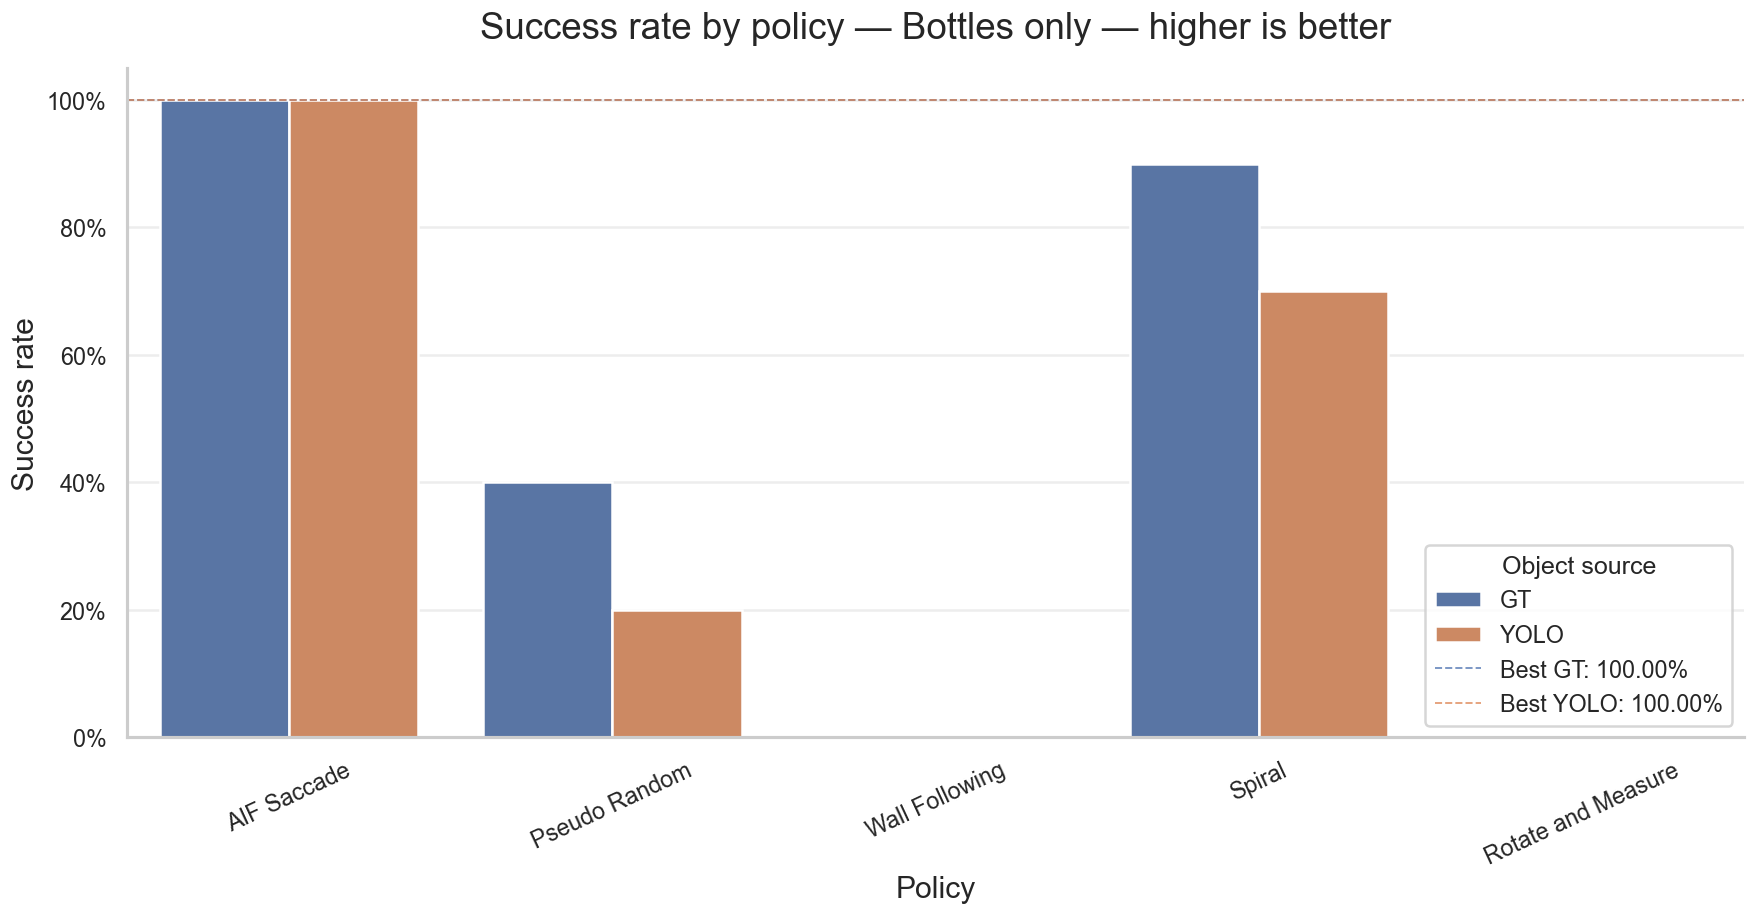

Saved figure: figures_eval_comparison/mixed__success.png


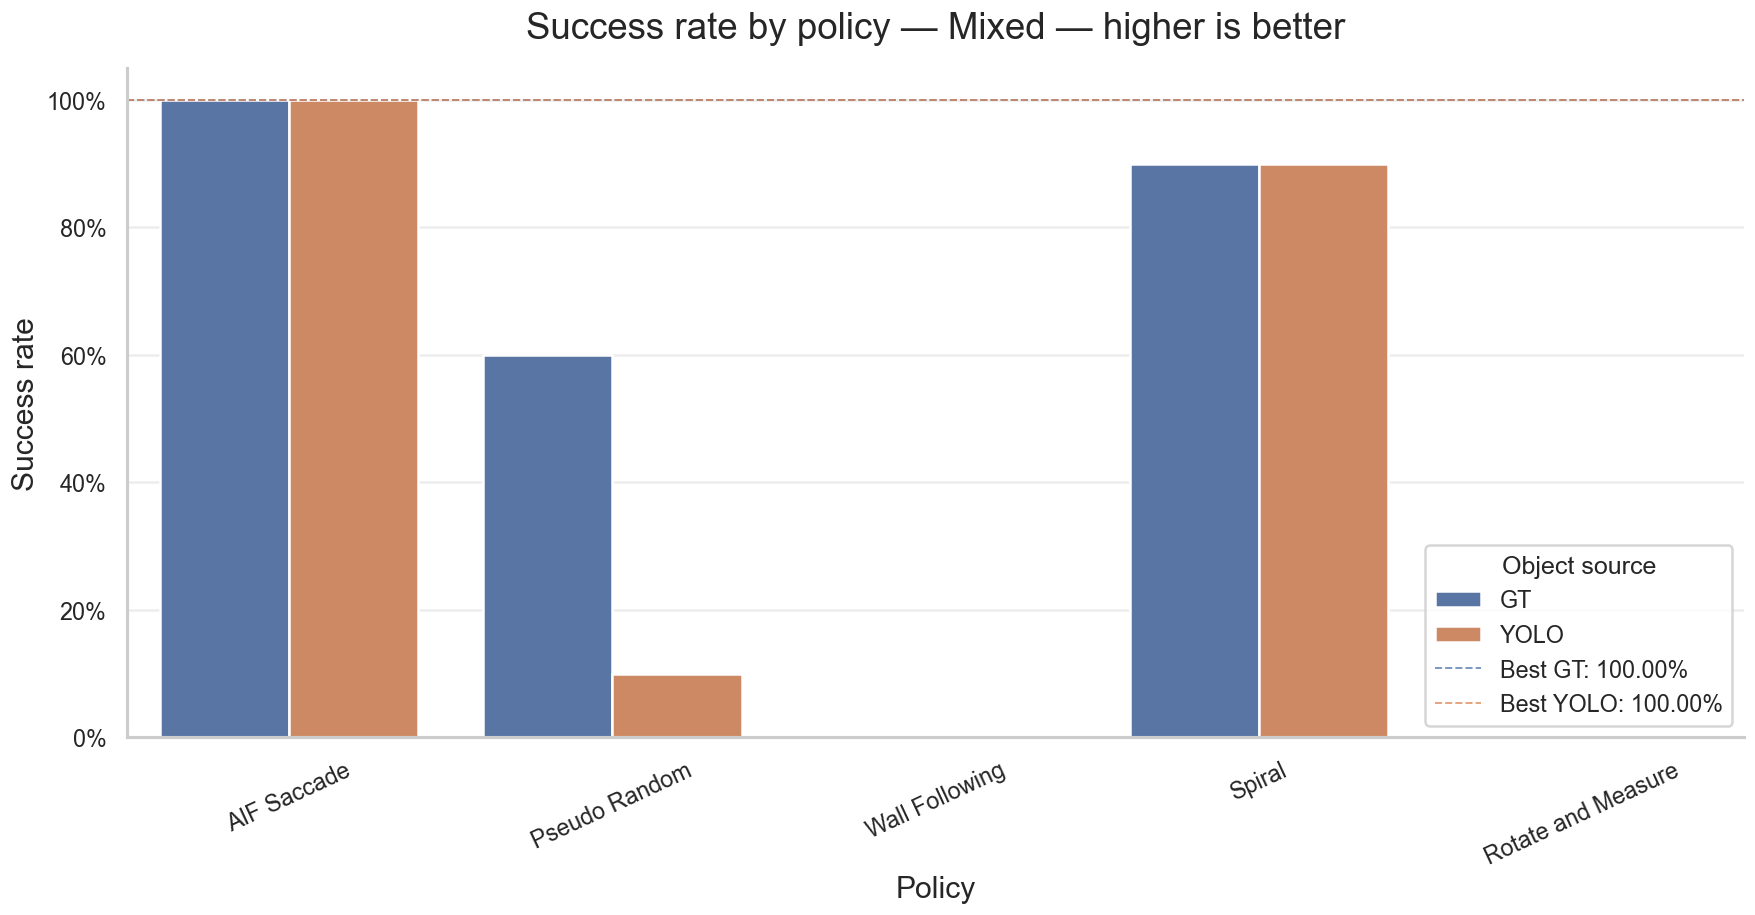

Saved figure: figures_eval_comparison/bottles_only__detected_objects_ratio.png


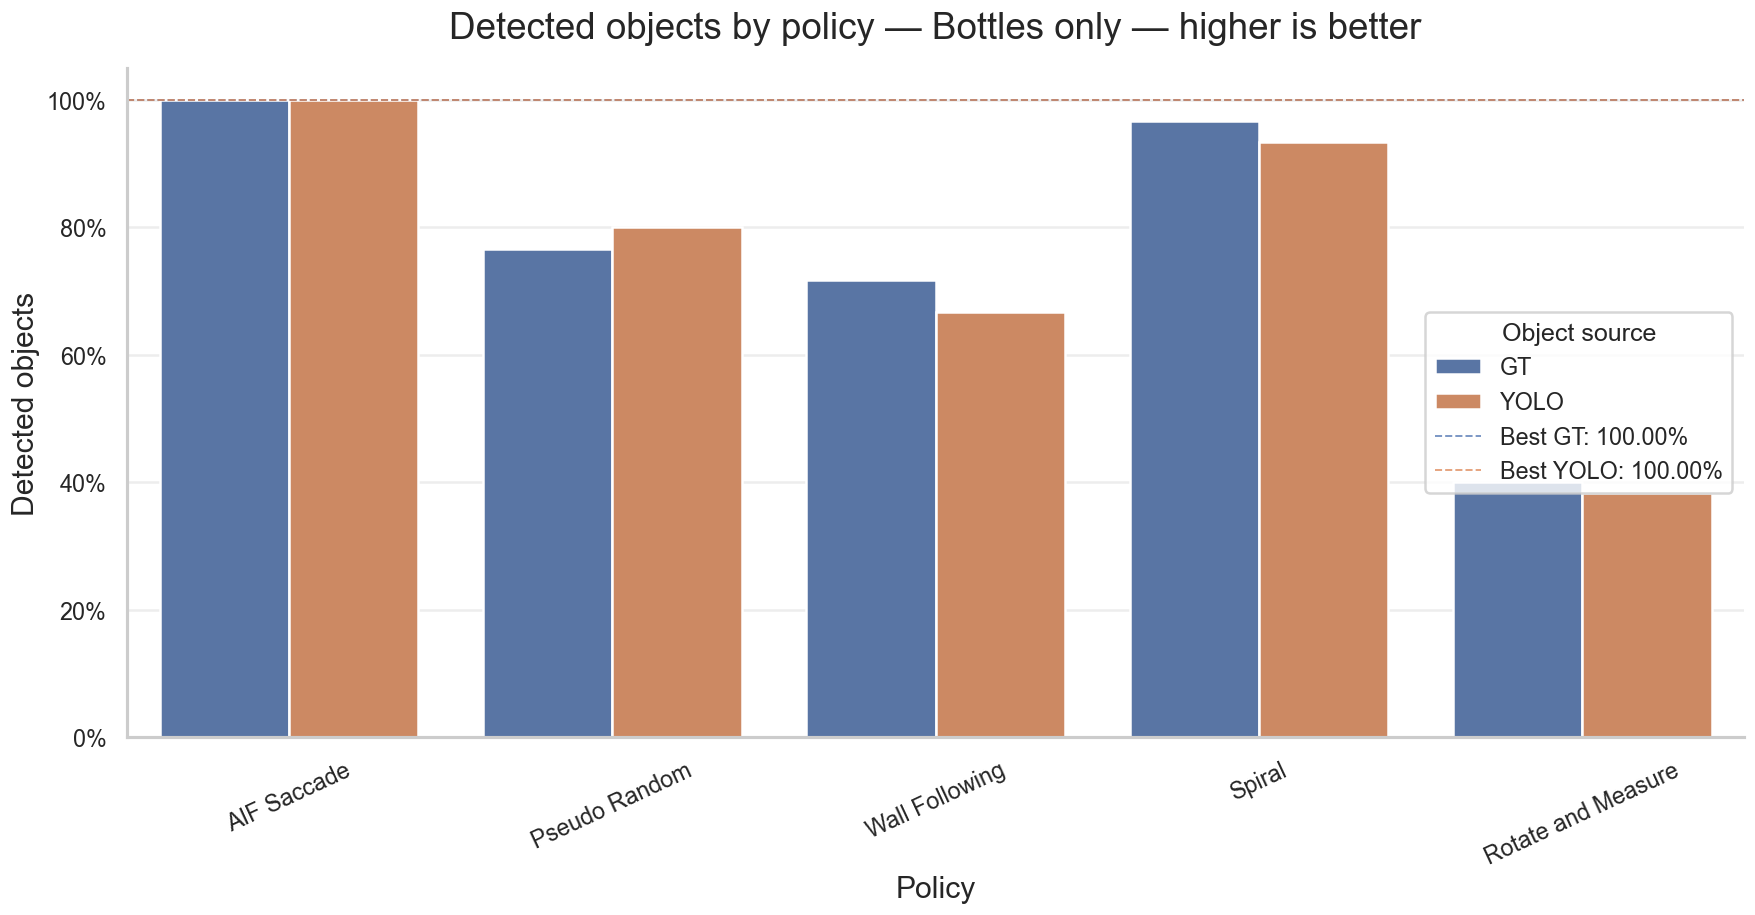

Saved figure: figures_eval_comparison/mixed__detected_objects_ratio.png


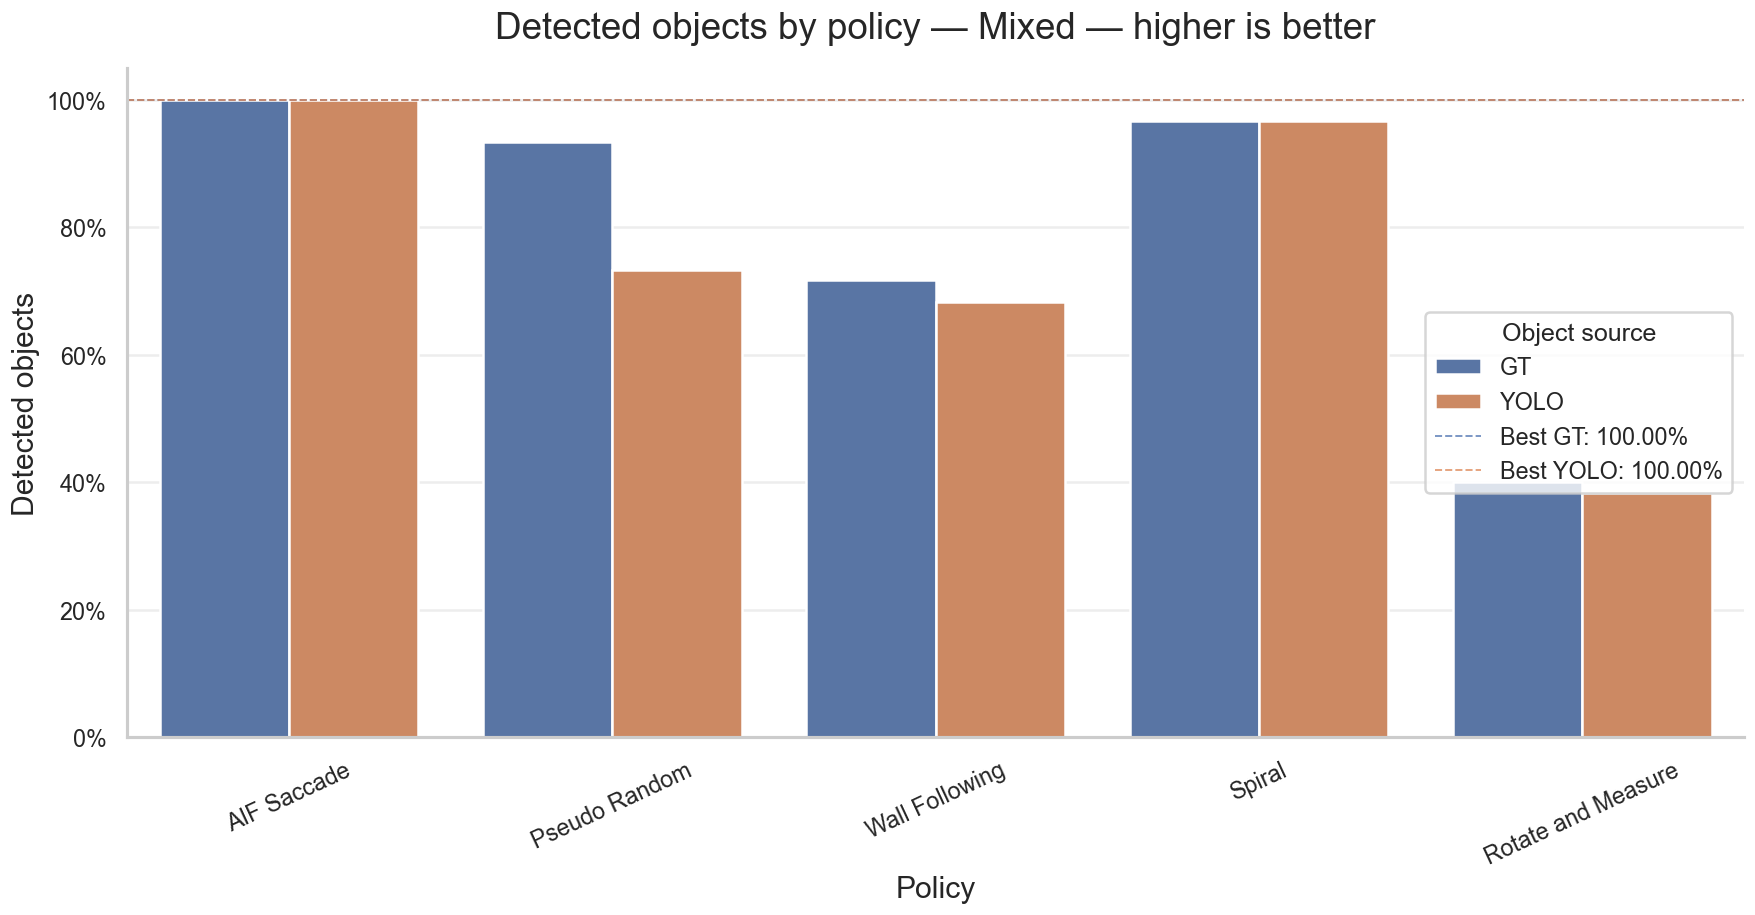

Saved figure: figures_eval_comparison/bottles_only__elapsed_s.png


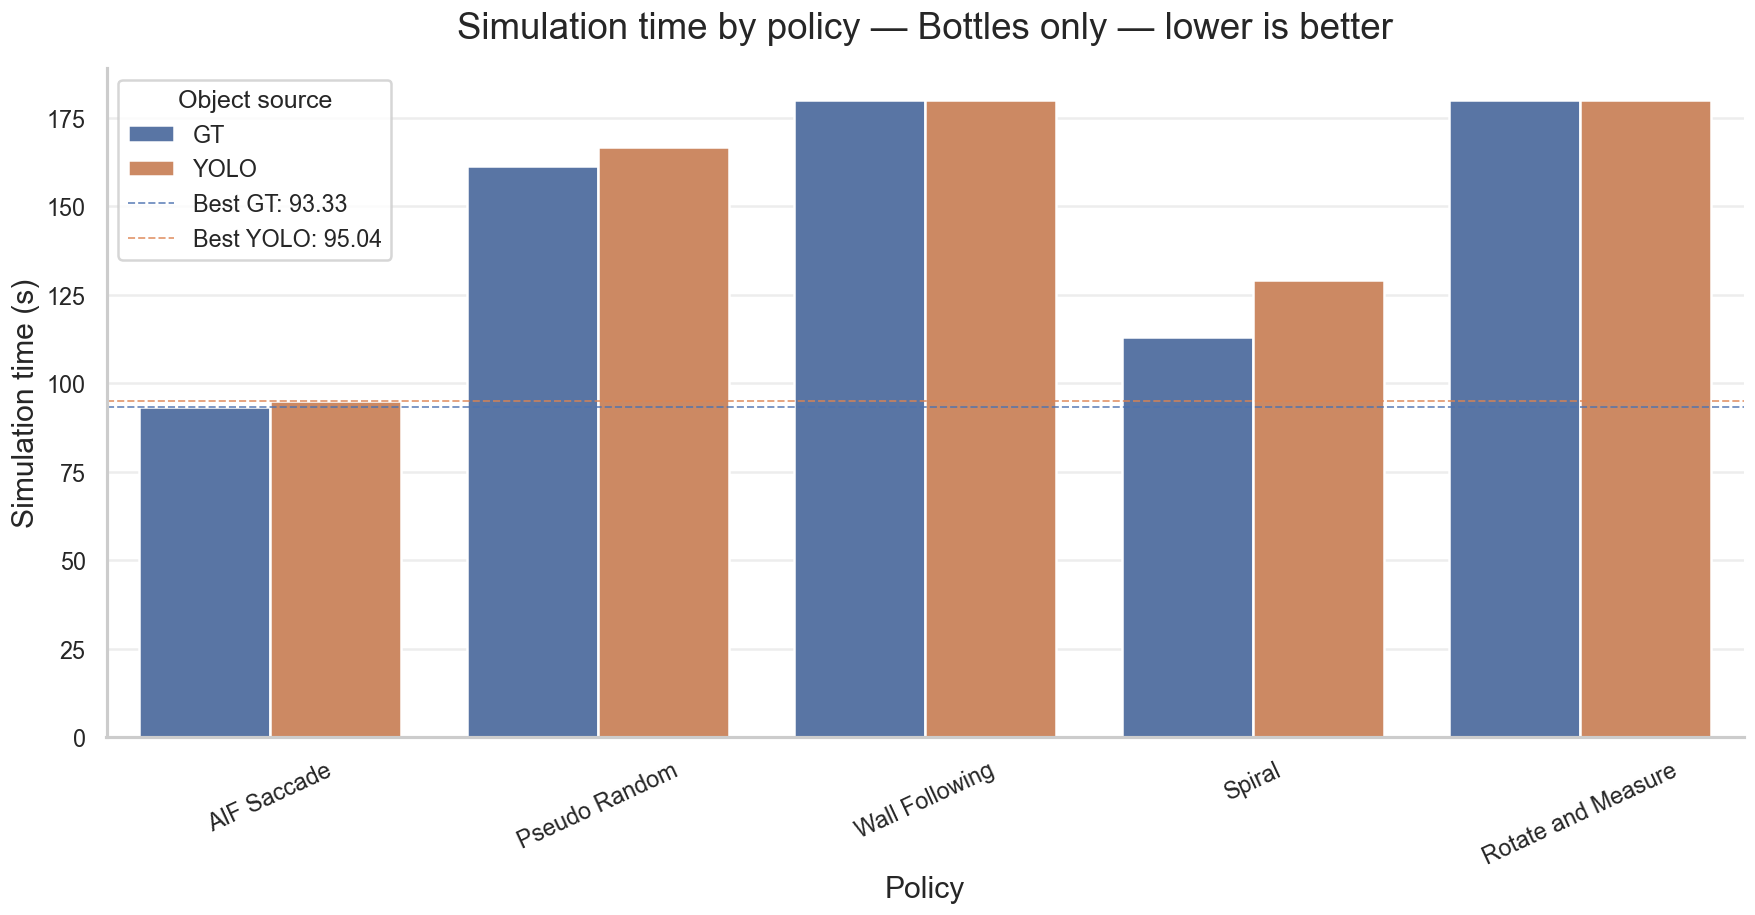

Saved figure: figures_eval_comparison/mixed__elapsed_s.png


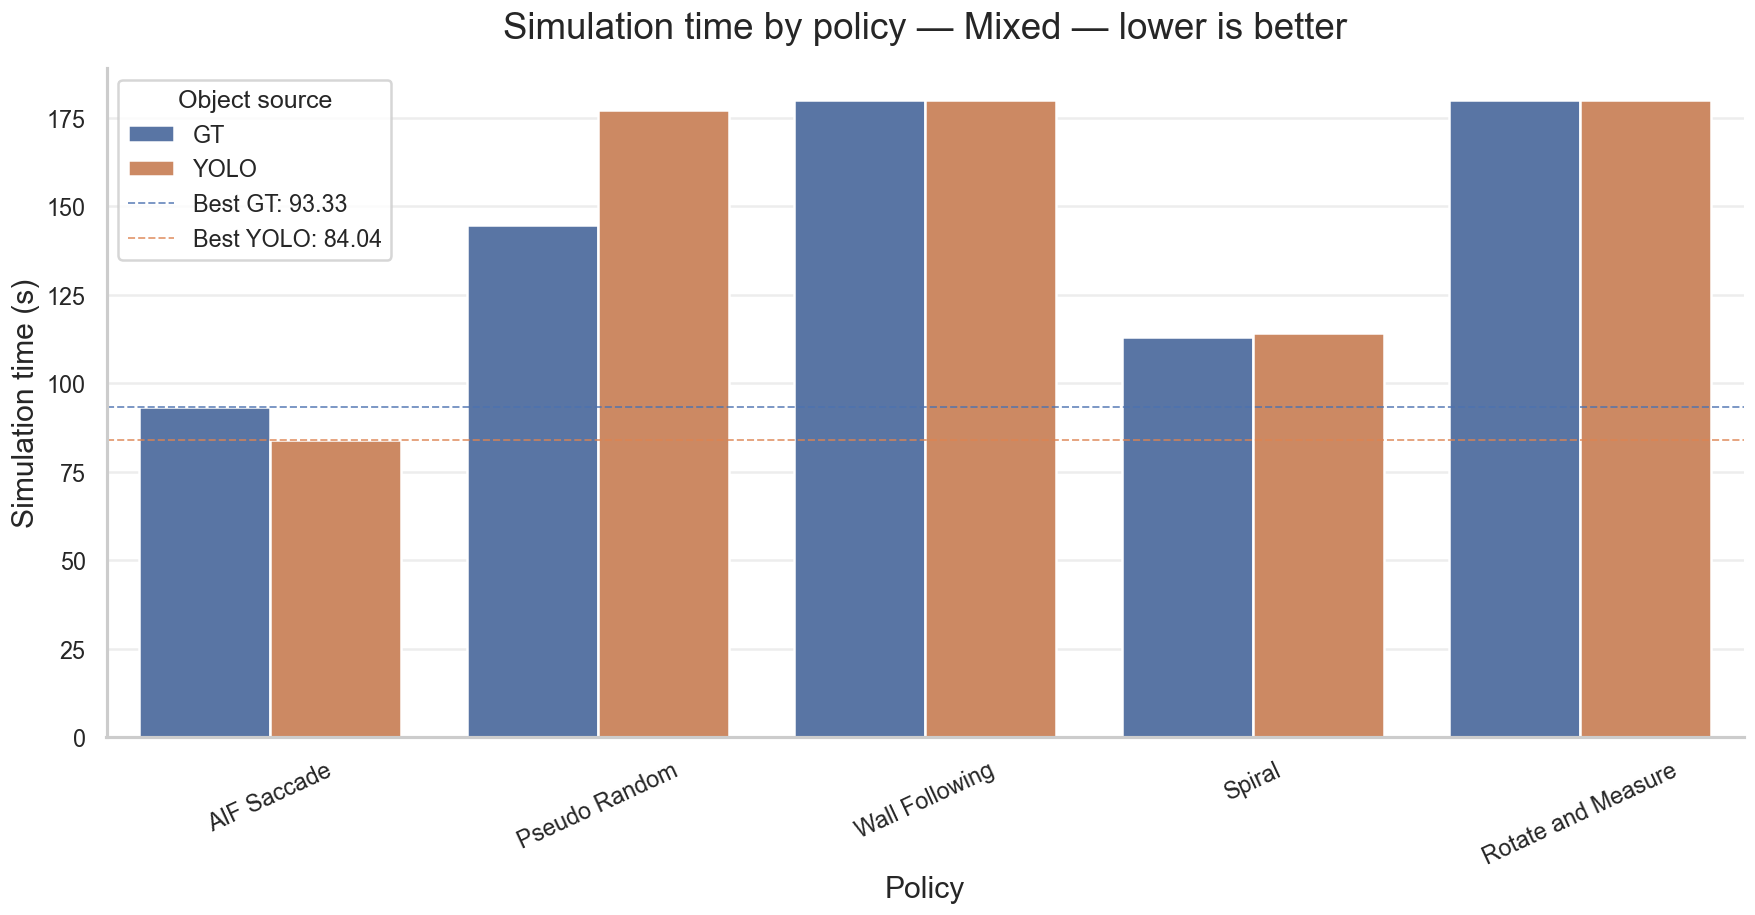

Saved figure: figures_eval_comparison/bottles_only__found_count.png


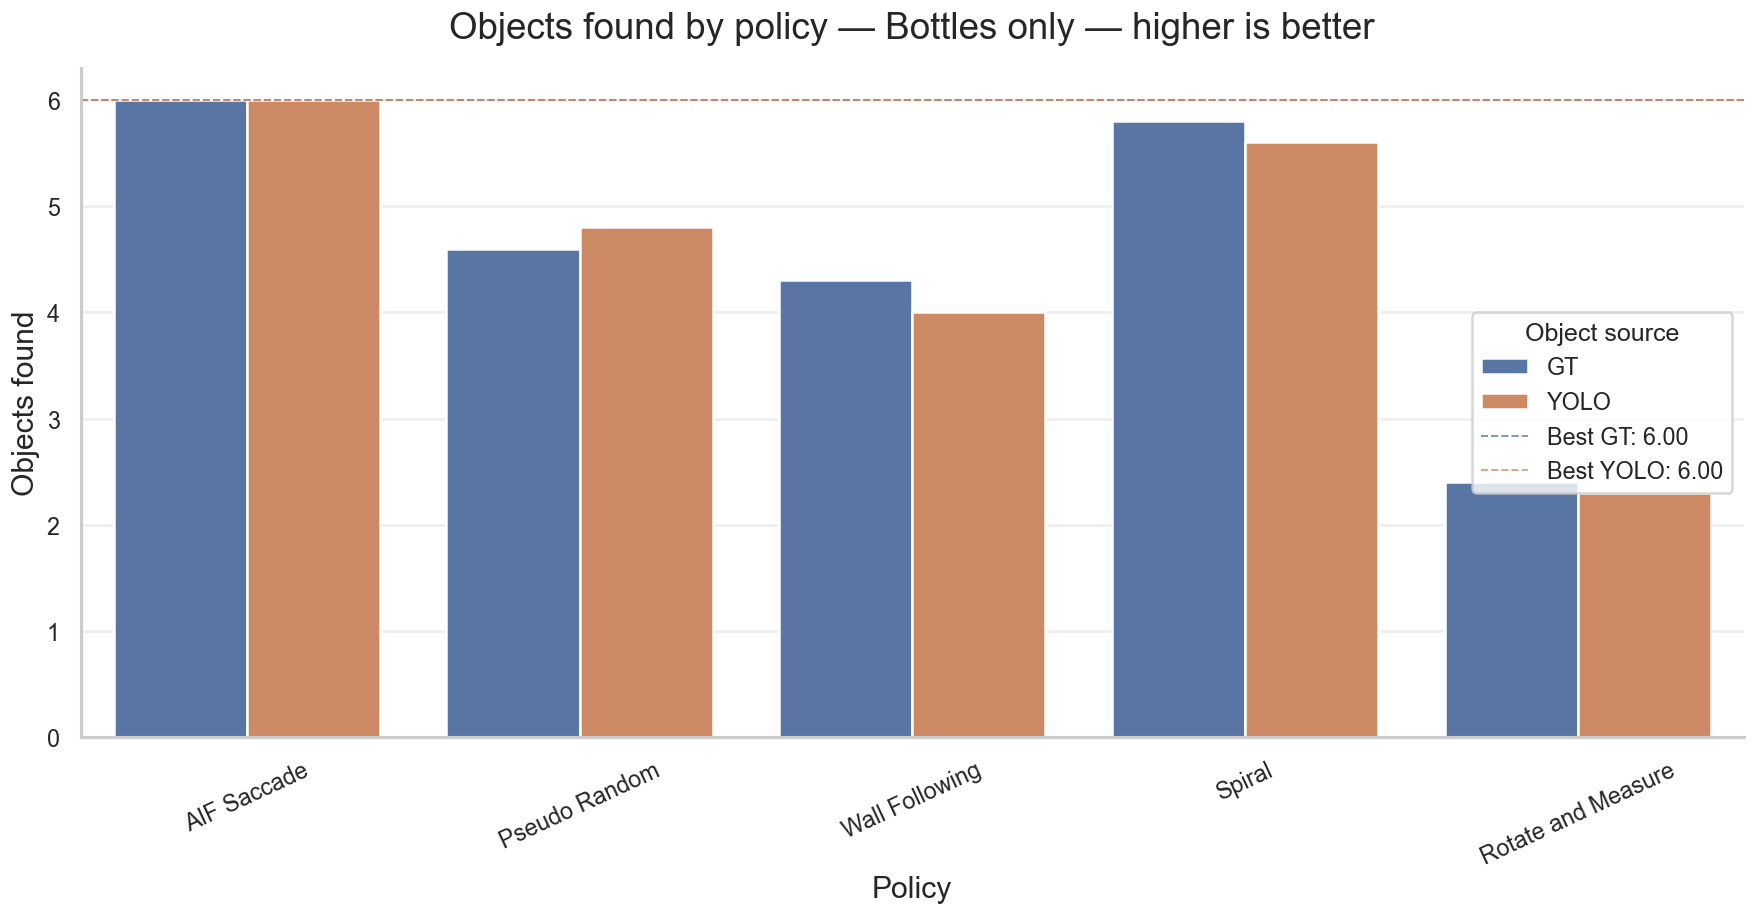

Saved figure: figures_eval_comparison/mixed__found_count.png


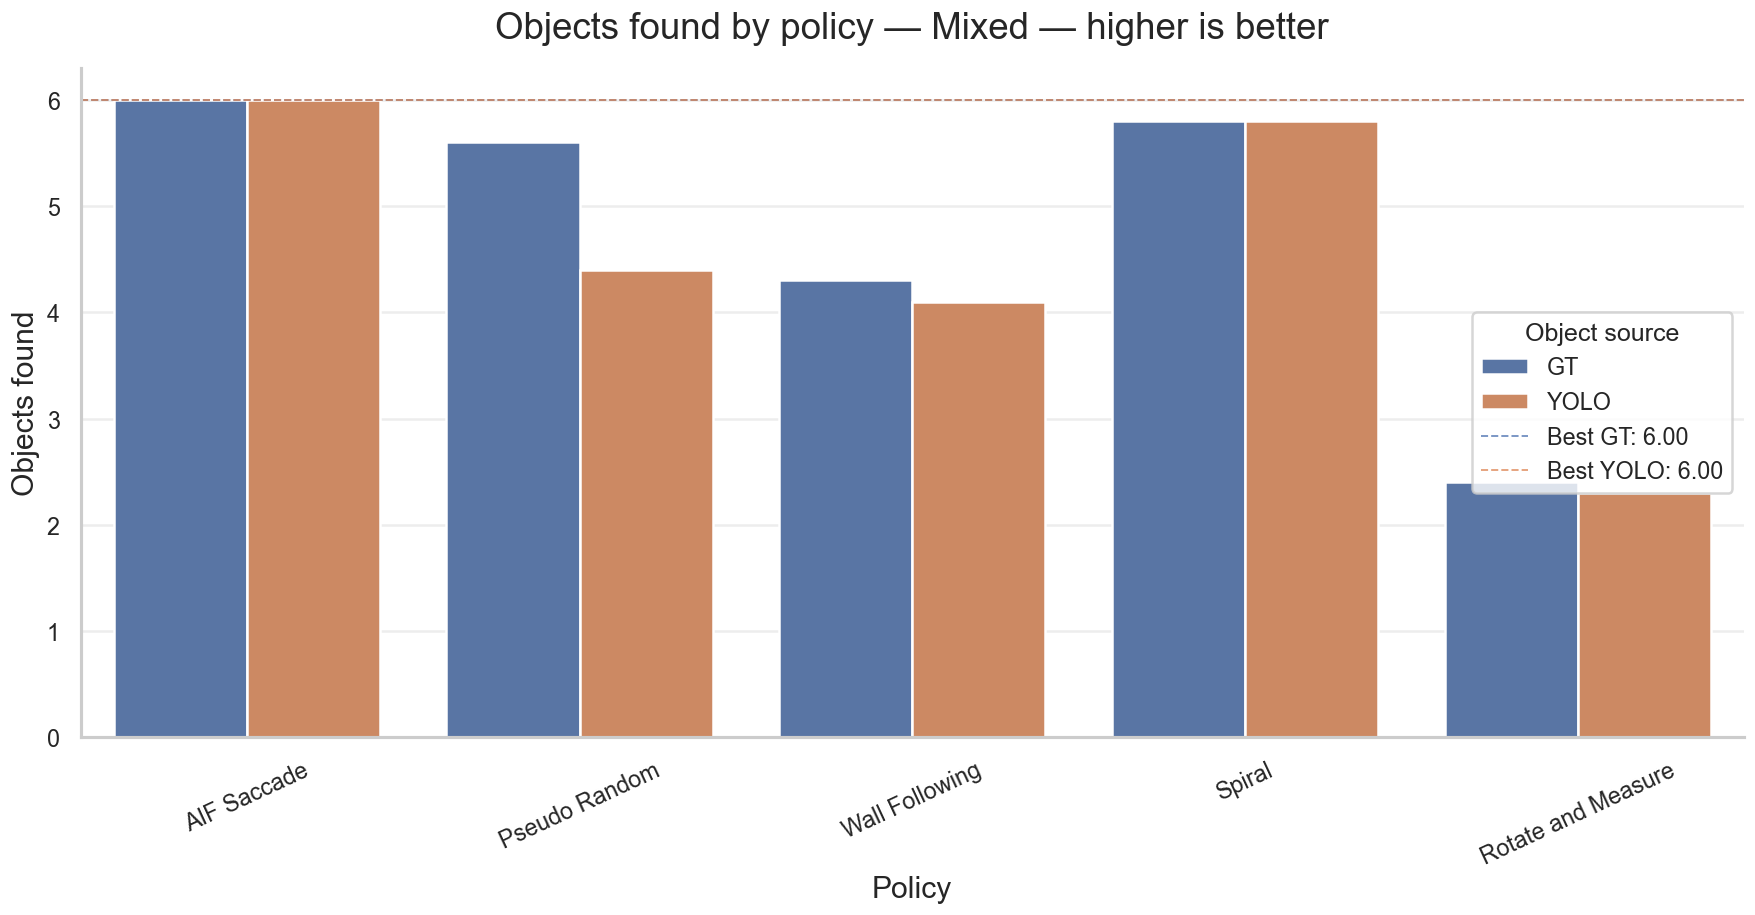

Saved figure: figures_eval_comparison/bottles_only__remaining_objects.png


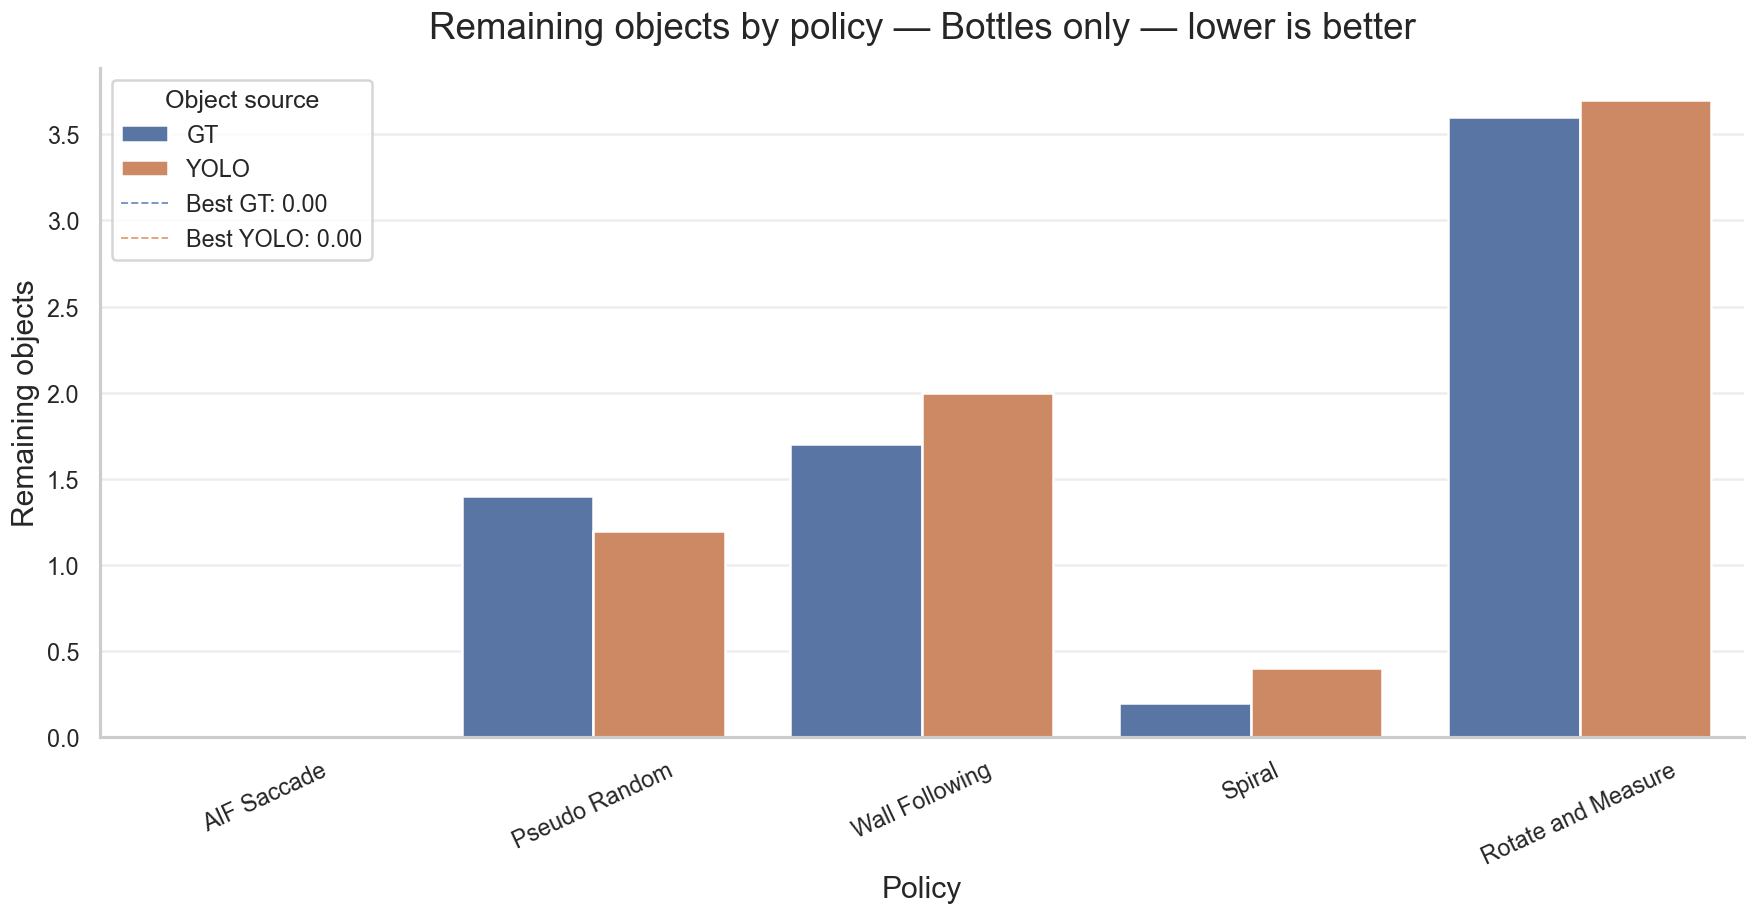

Saved figure: figures_eval_comparison/mixed__remaining_objects.png


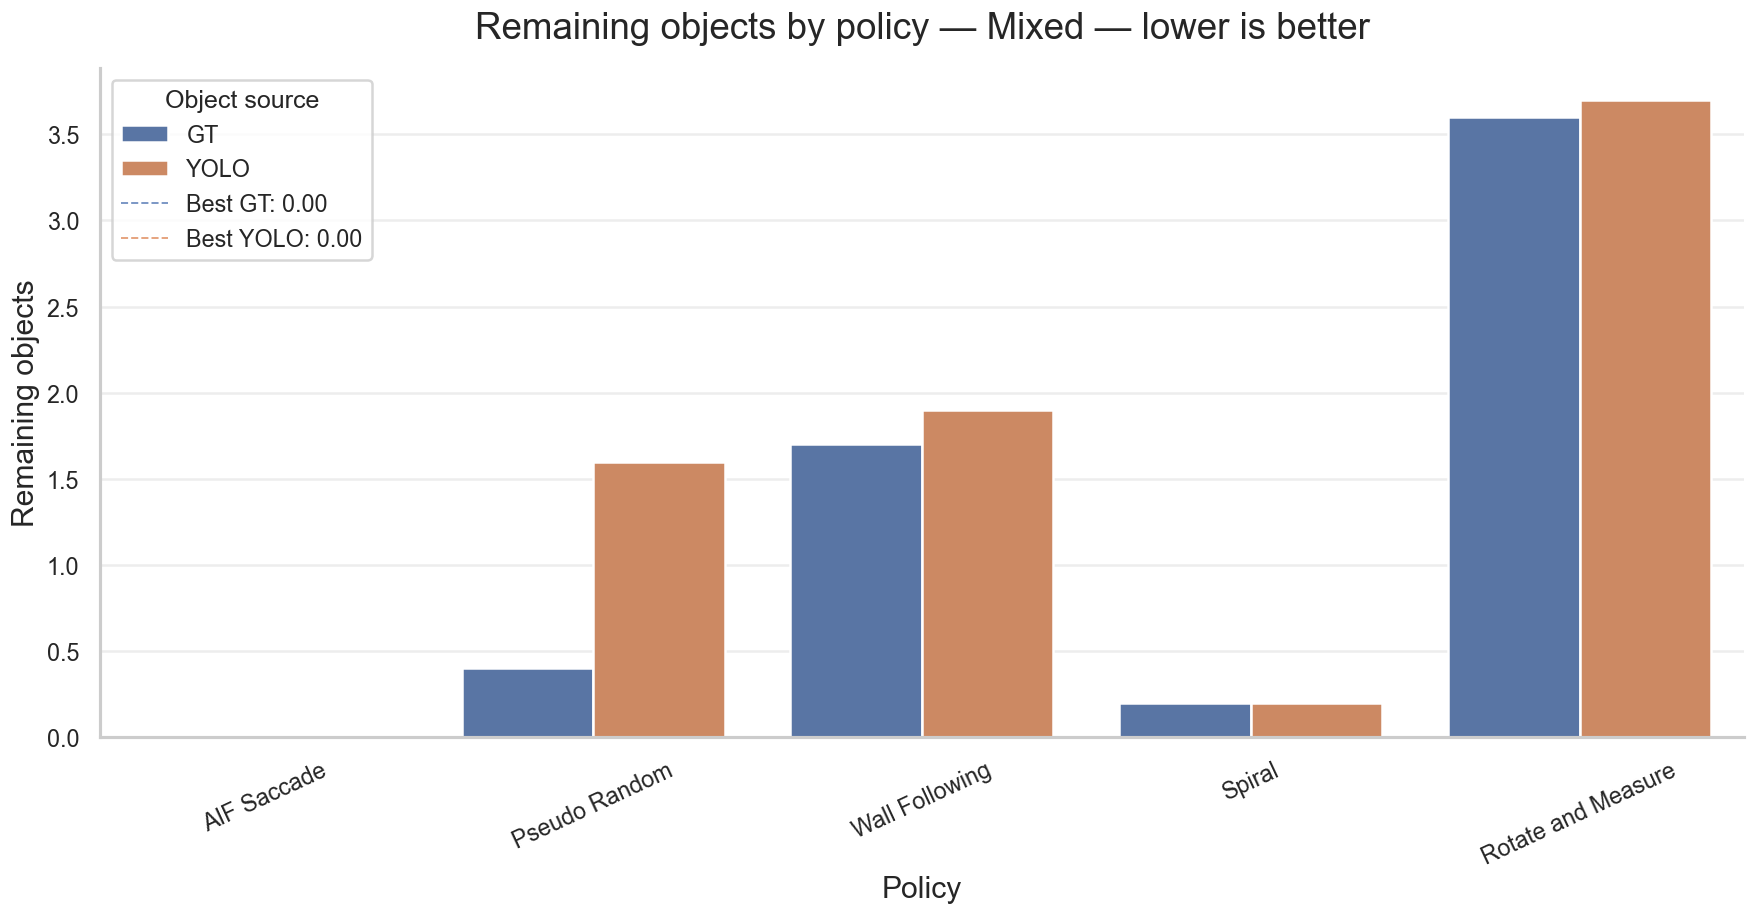

Saved figure: figures_eval_comparison/bottles_only__coverage_ratio.png


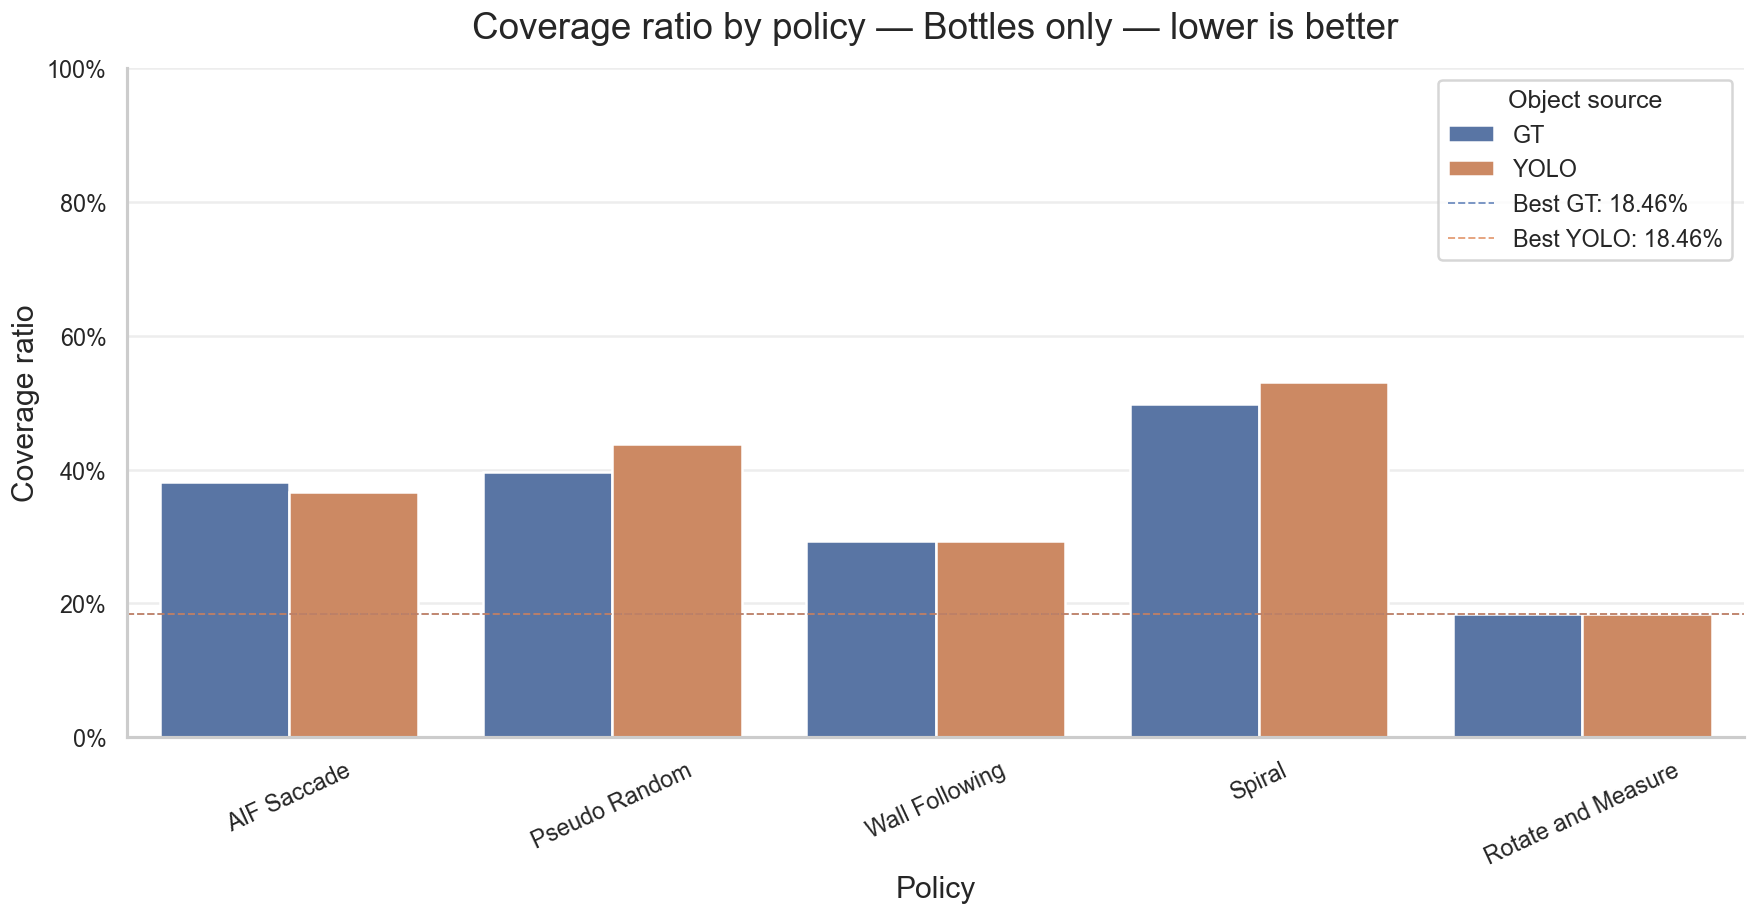

Saved figure: figures_eval_comparison/mixed__coverage_ratio.png


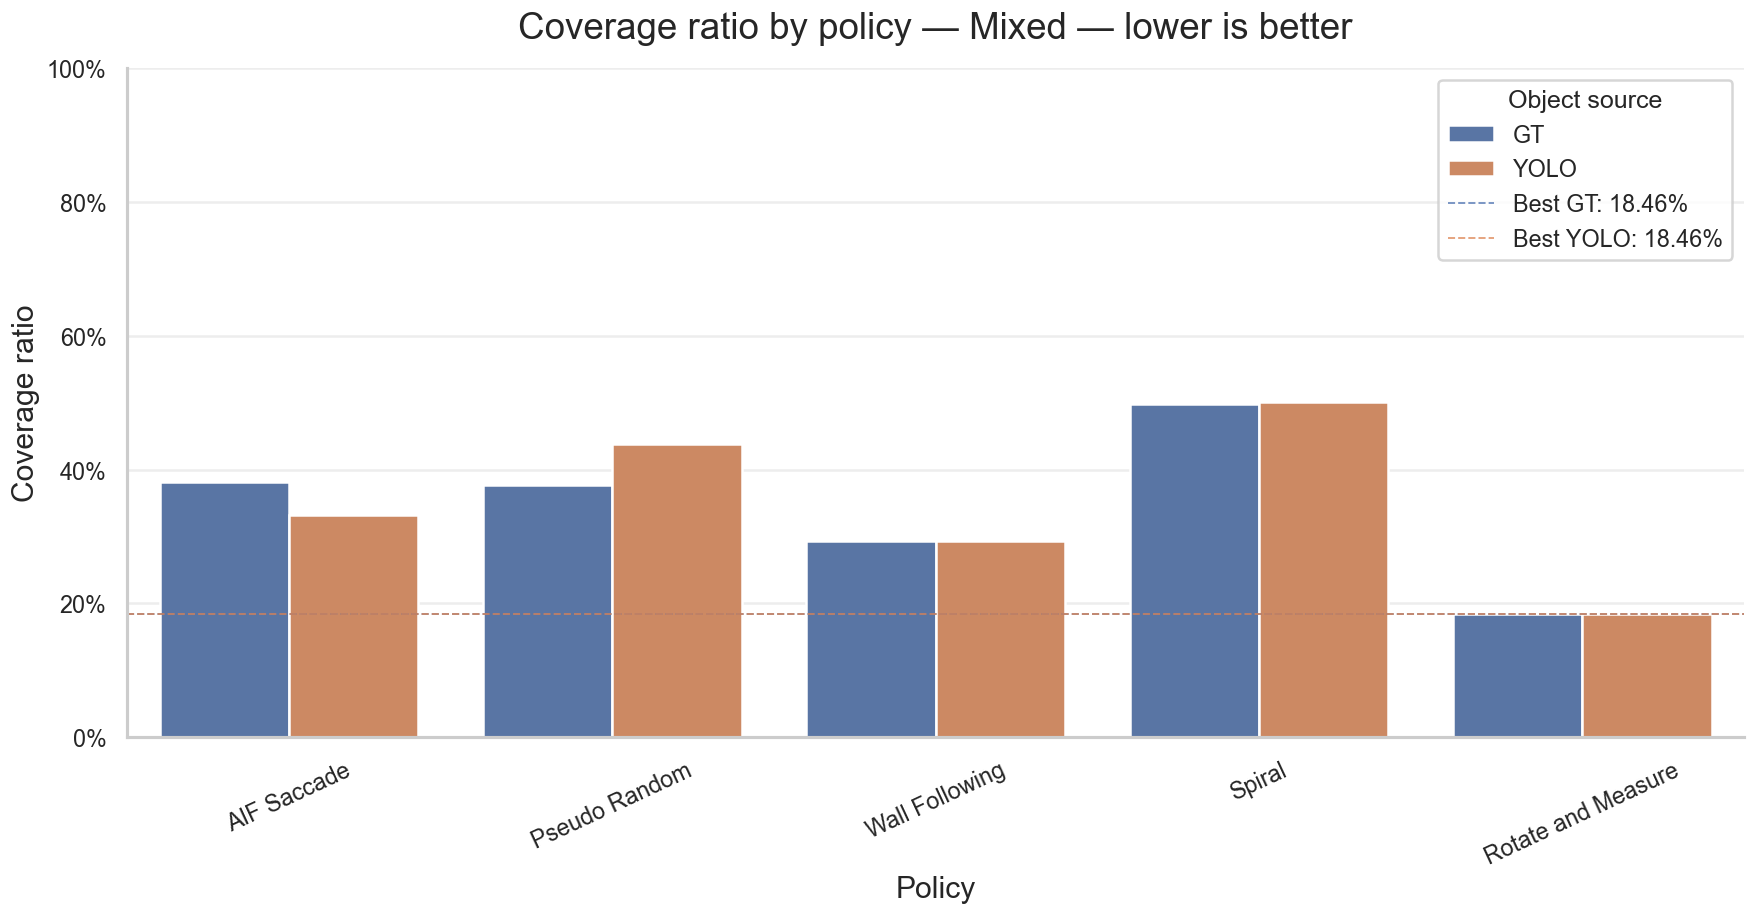

In [8]:
for metric in BASE_METRICS:
    if not metric_is_available(runs_df, metric):
        print(f"Skipping {metric}: not available.")
        continue

    for dataset in dataset_order:
        plot_metric_bar(metric, dataset)

Classification metrics found: ['overall_claim_precision', 'object_cell_class_accuracy', 'unique_claims_evaluated', 'correct_class_claims', 'wrong_class_claims', 'empty_cell_claims', 'duplicate_claims_ignored']
Skipping Overall claim precision for Bottles only: no GT / unlimited-YOLO values.
Saved figure: figures_eval_comparison/mixed__overall_claim_precision.png


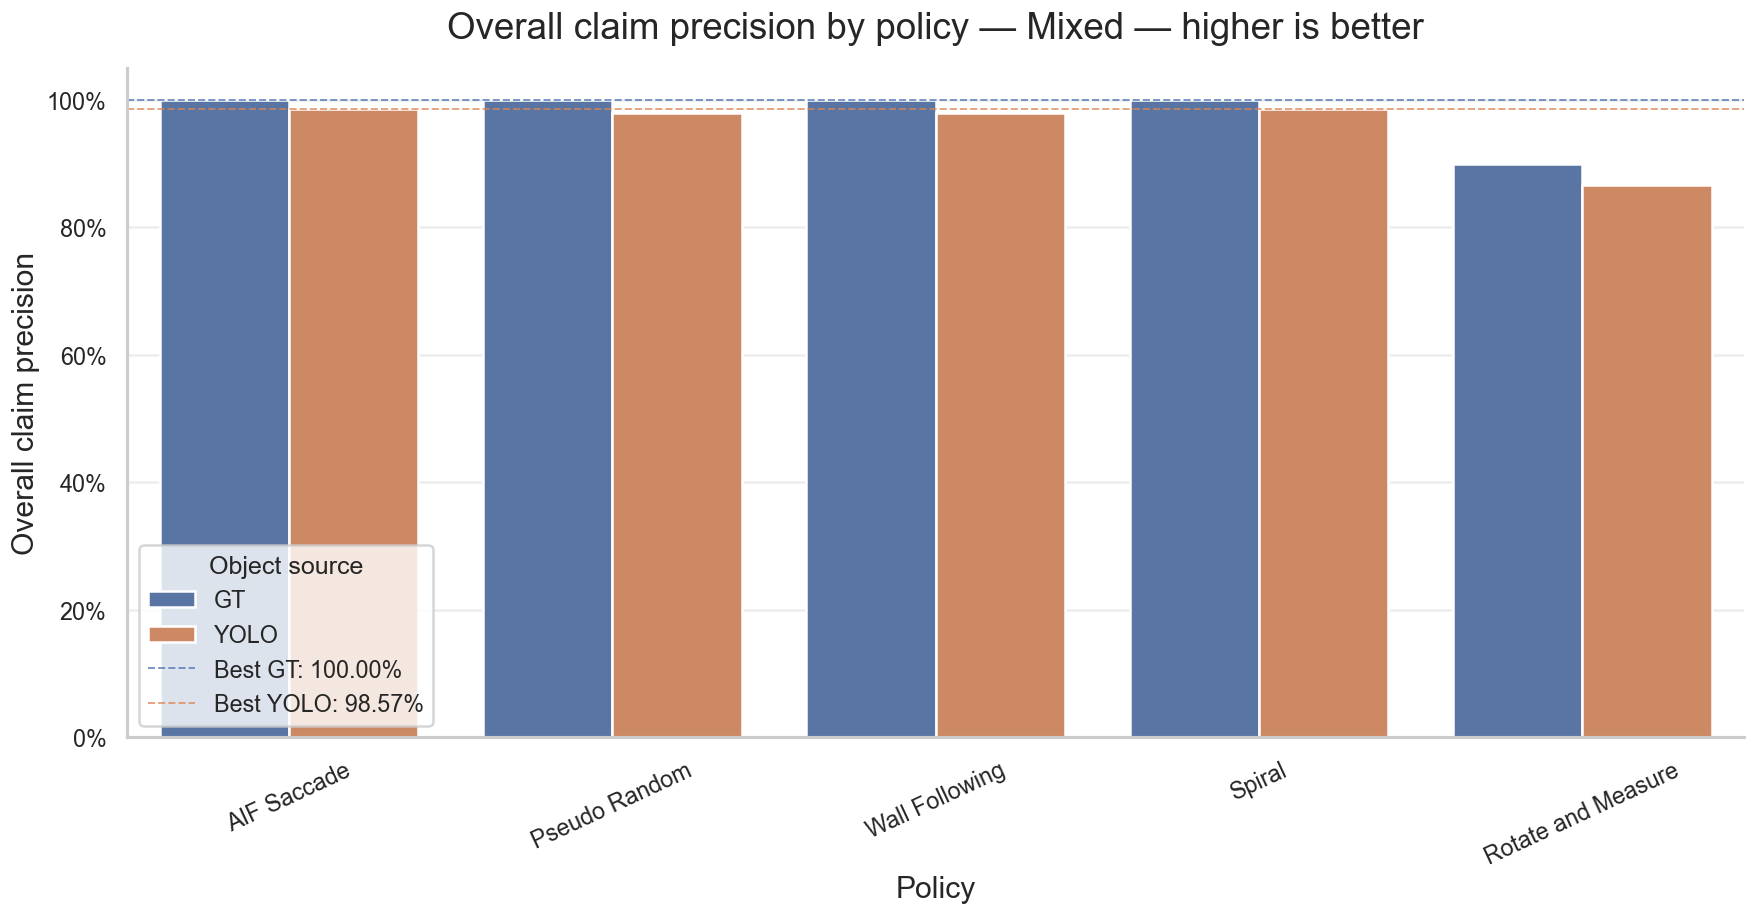

Skipping Object-cell class accuracy for Bottles only: no GT / unlimited-YOLO values.
Saved figure: figures_eval_comparison/mixed__object_cell_class_accuracy.png


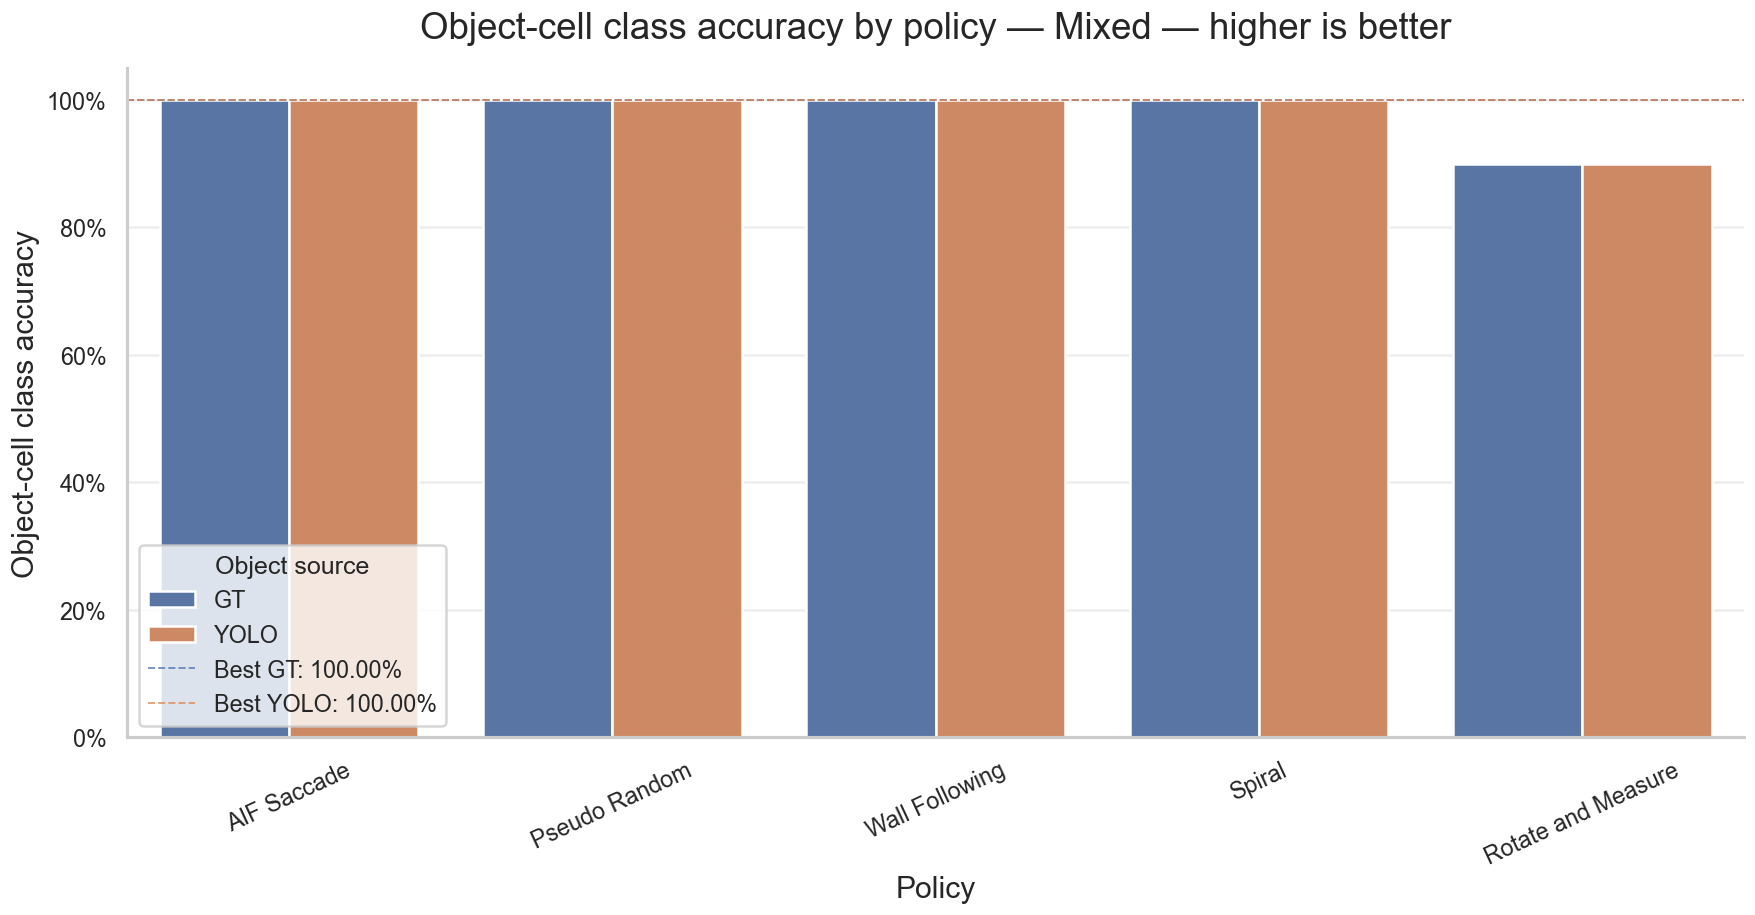

Skipping Unique claims evaluated for Bottles only: no GT / unlimited-YOLO values.
Saved figure: figures_eval_comparison/mixed__unique_claims_evaluated.png


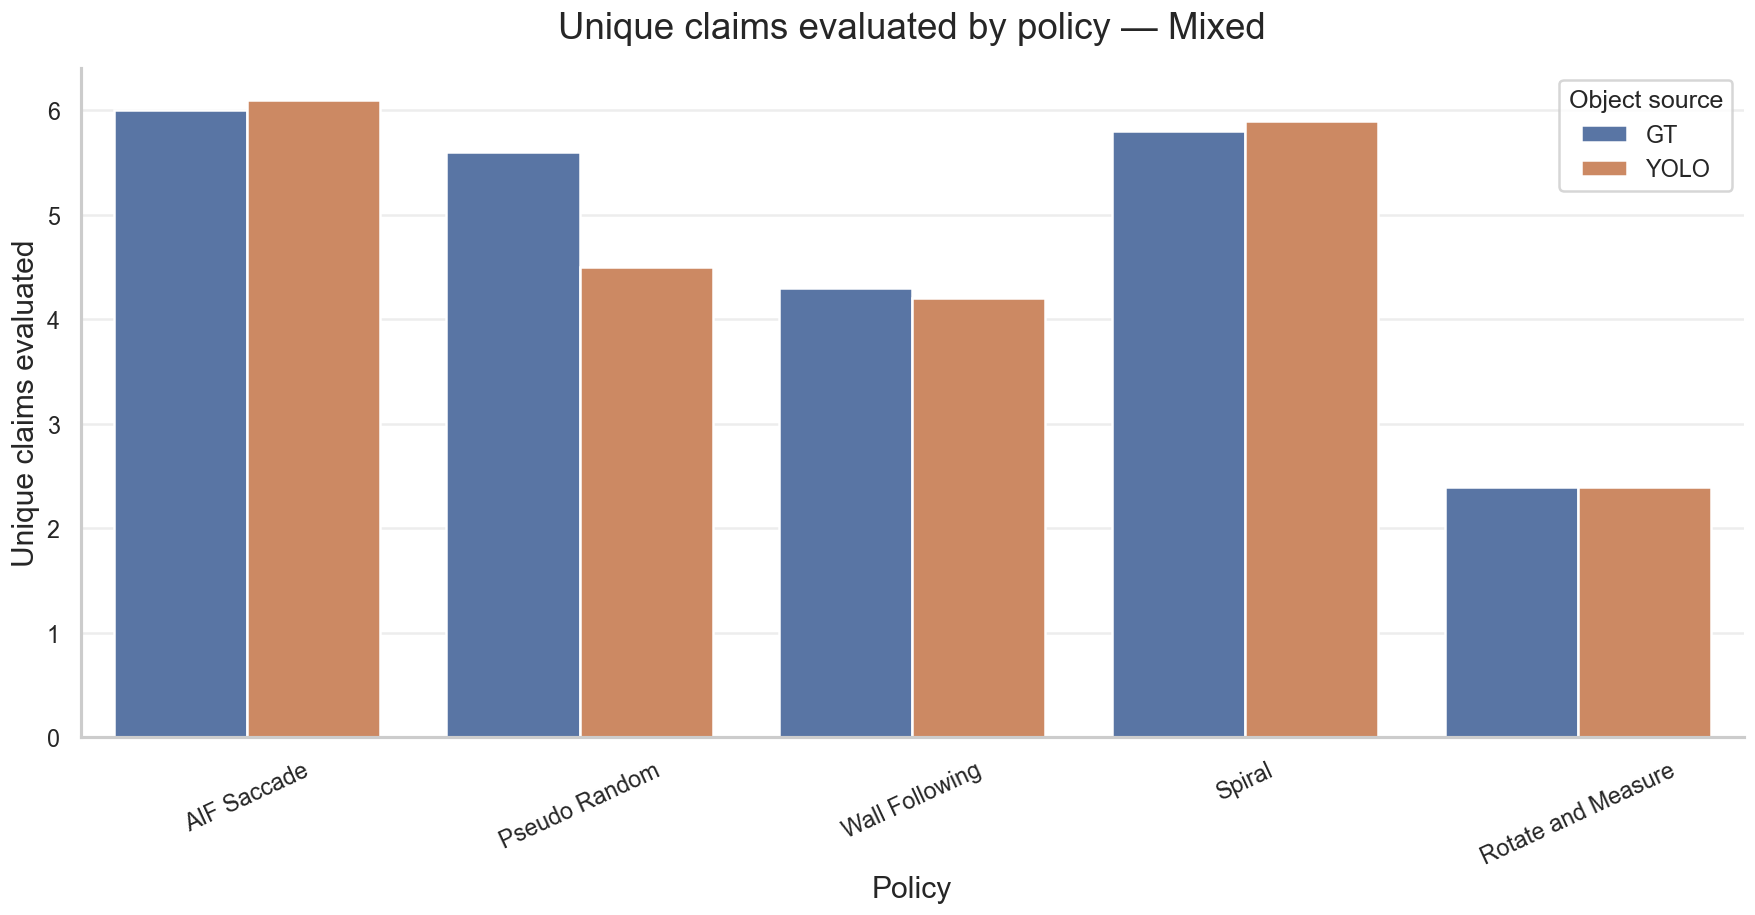

Skipping Correct class claims for Bottles only: no GT / unlimited-YOLO values.
Saved figure: figures_eval_comparison/mixed__correct_class_claims.png


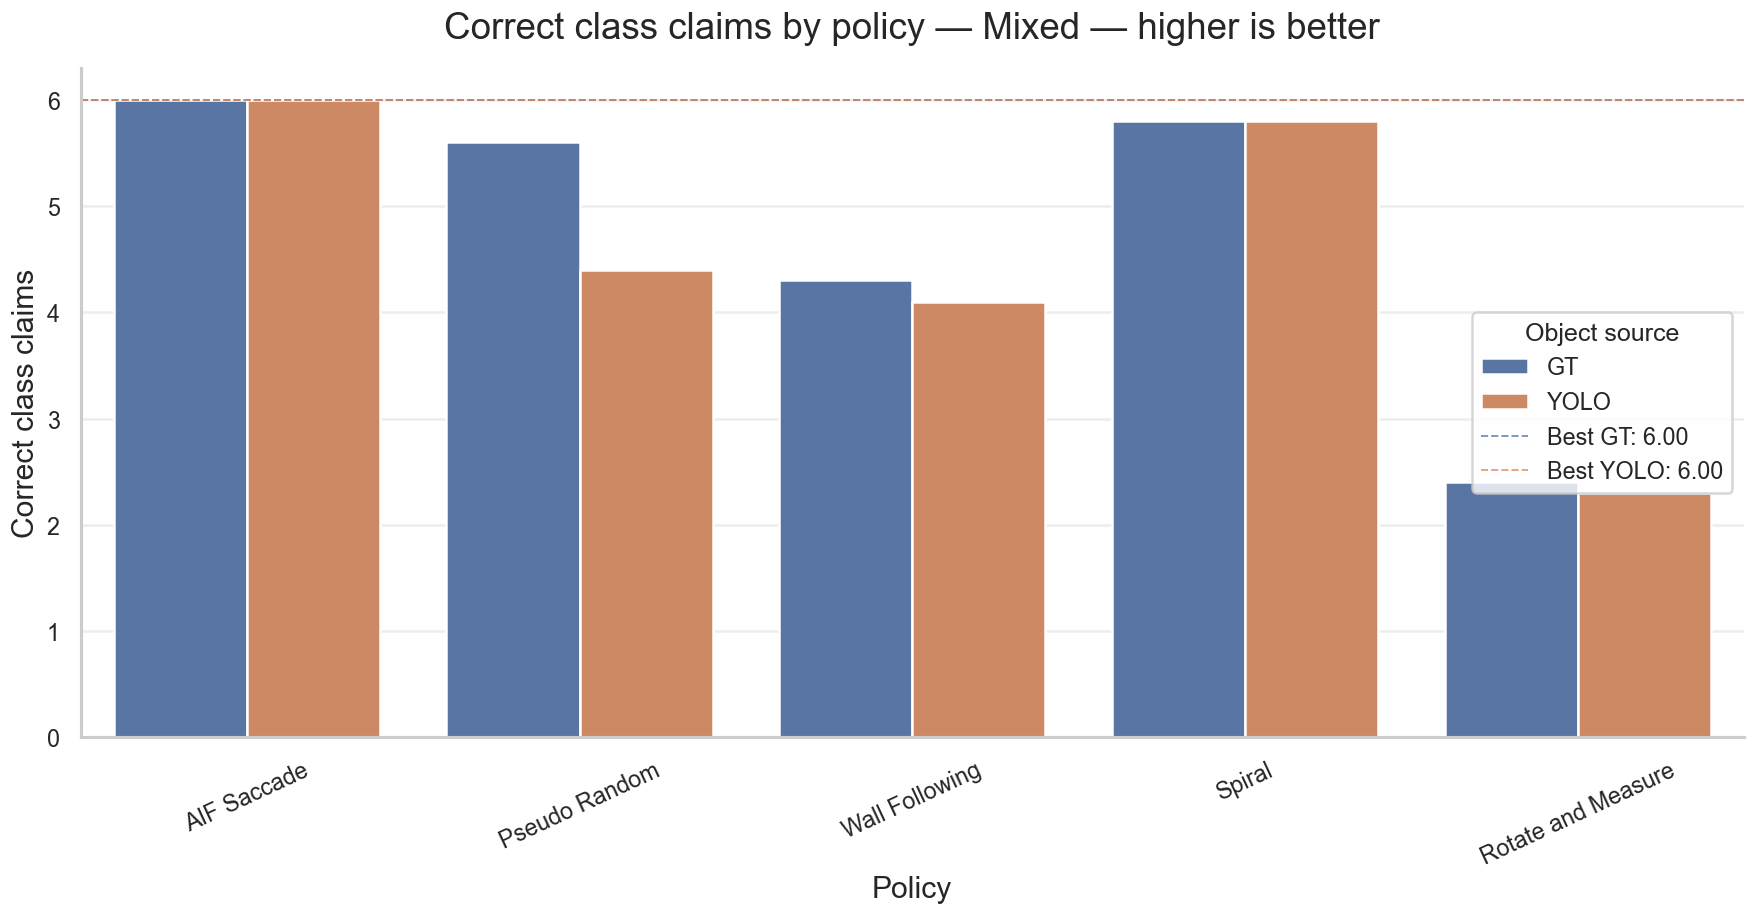

Skipping Wrong class claims for Bottles only: no GT / unlimited-YOLO values.
Saved figure: figures_eval_comparison/mixed__wrong_class_claims.png


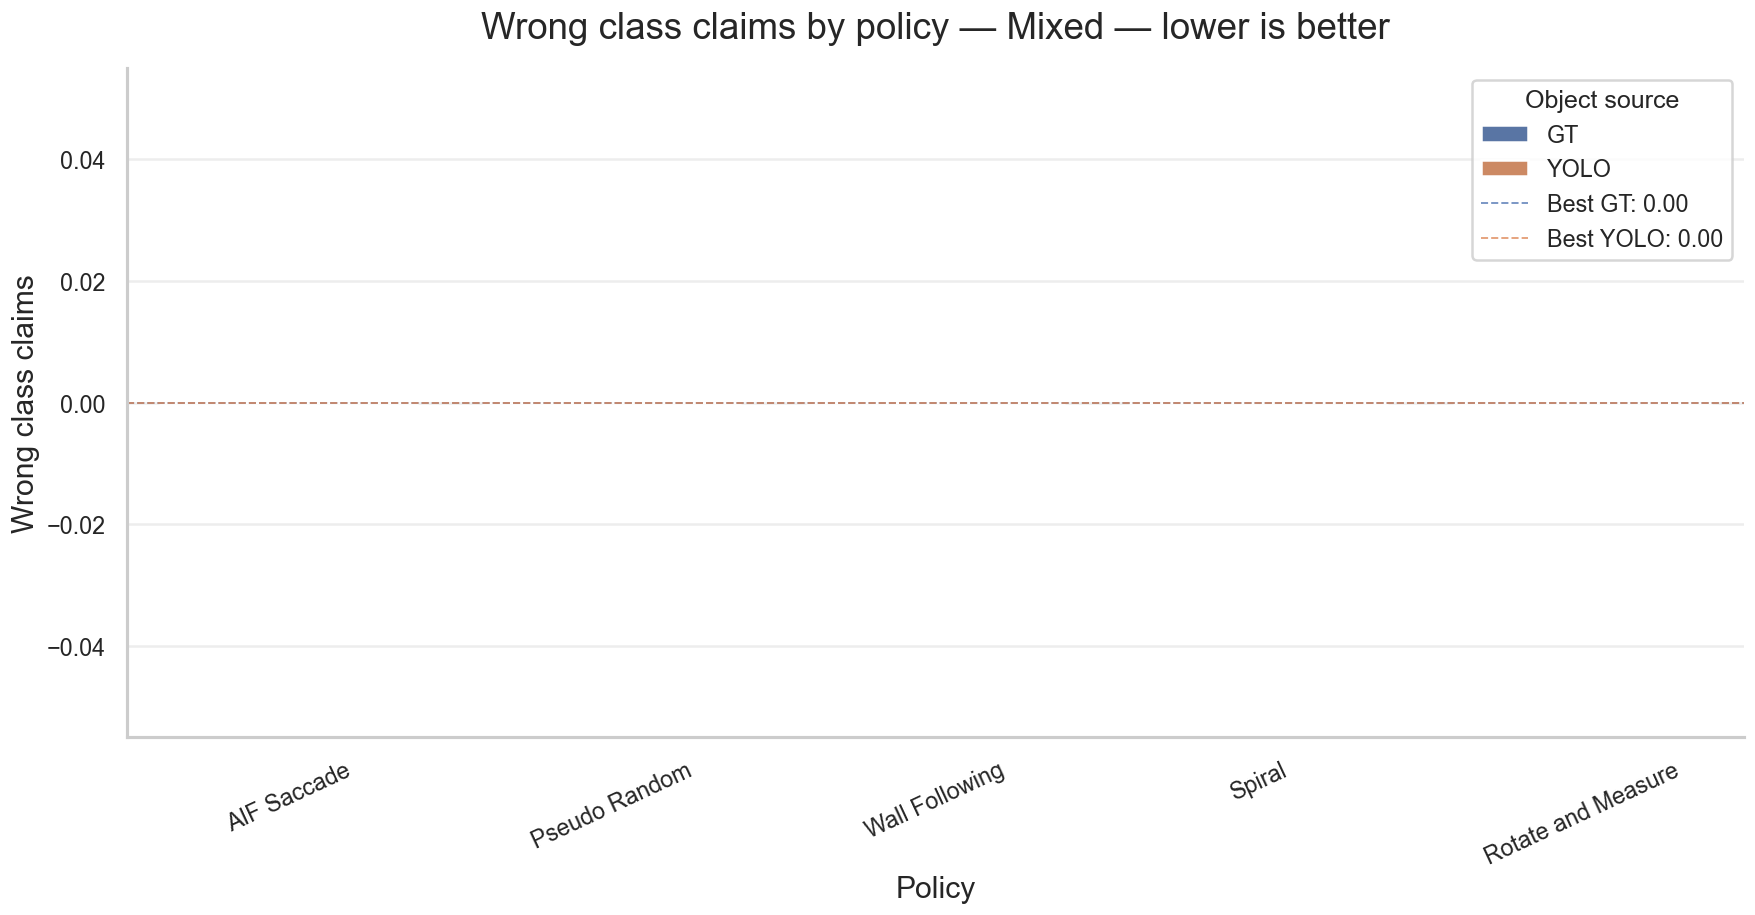

Skipping Empty-cell claims for Bottles only: no GT / unlimited-YOLO values.
Saved figure: figures_eval_comparison/mixed__empty_cell_claims.png


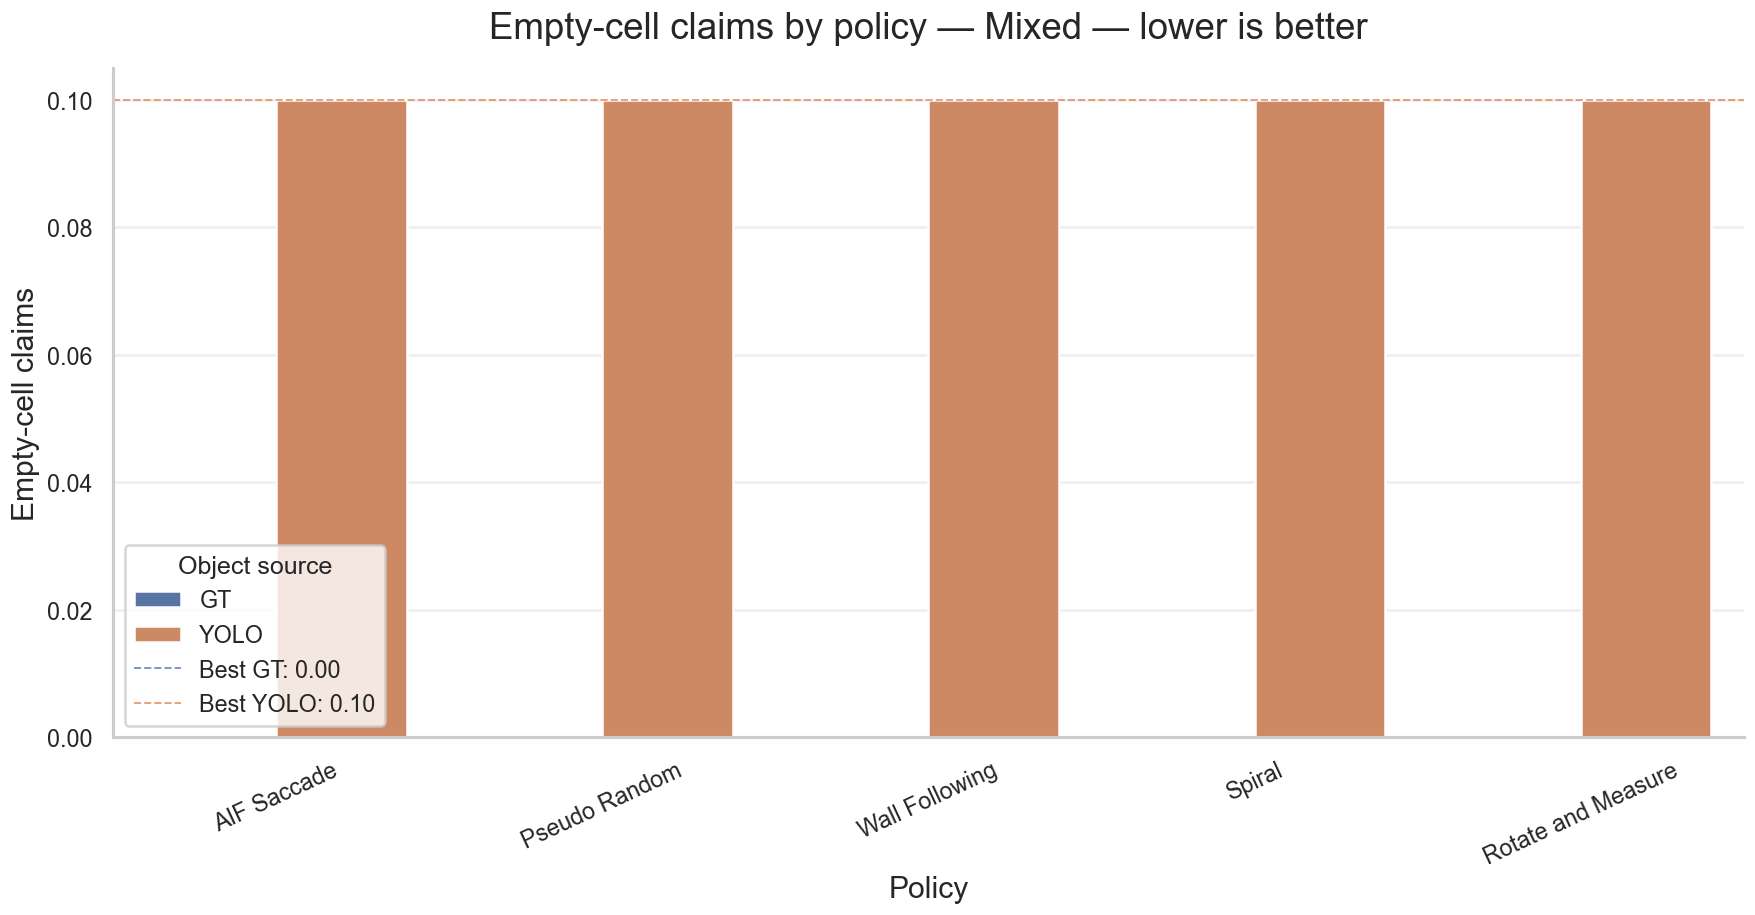

Skipping Duplicate claims ignored for Bottles only: no GT / unlimited-YOLO values.
Saved figure: figures_eval_comparison/mixed__duplicate_claims_ignored.png


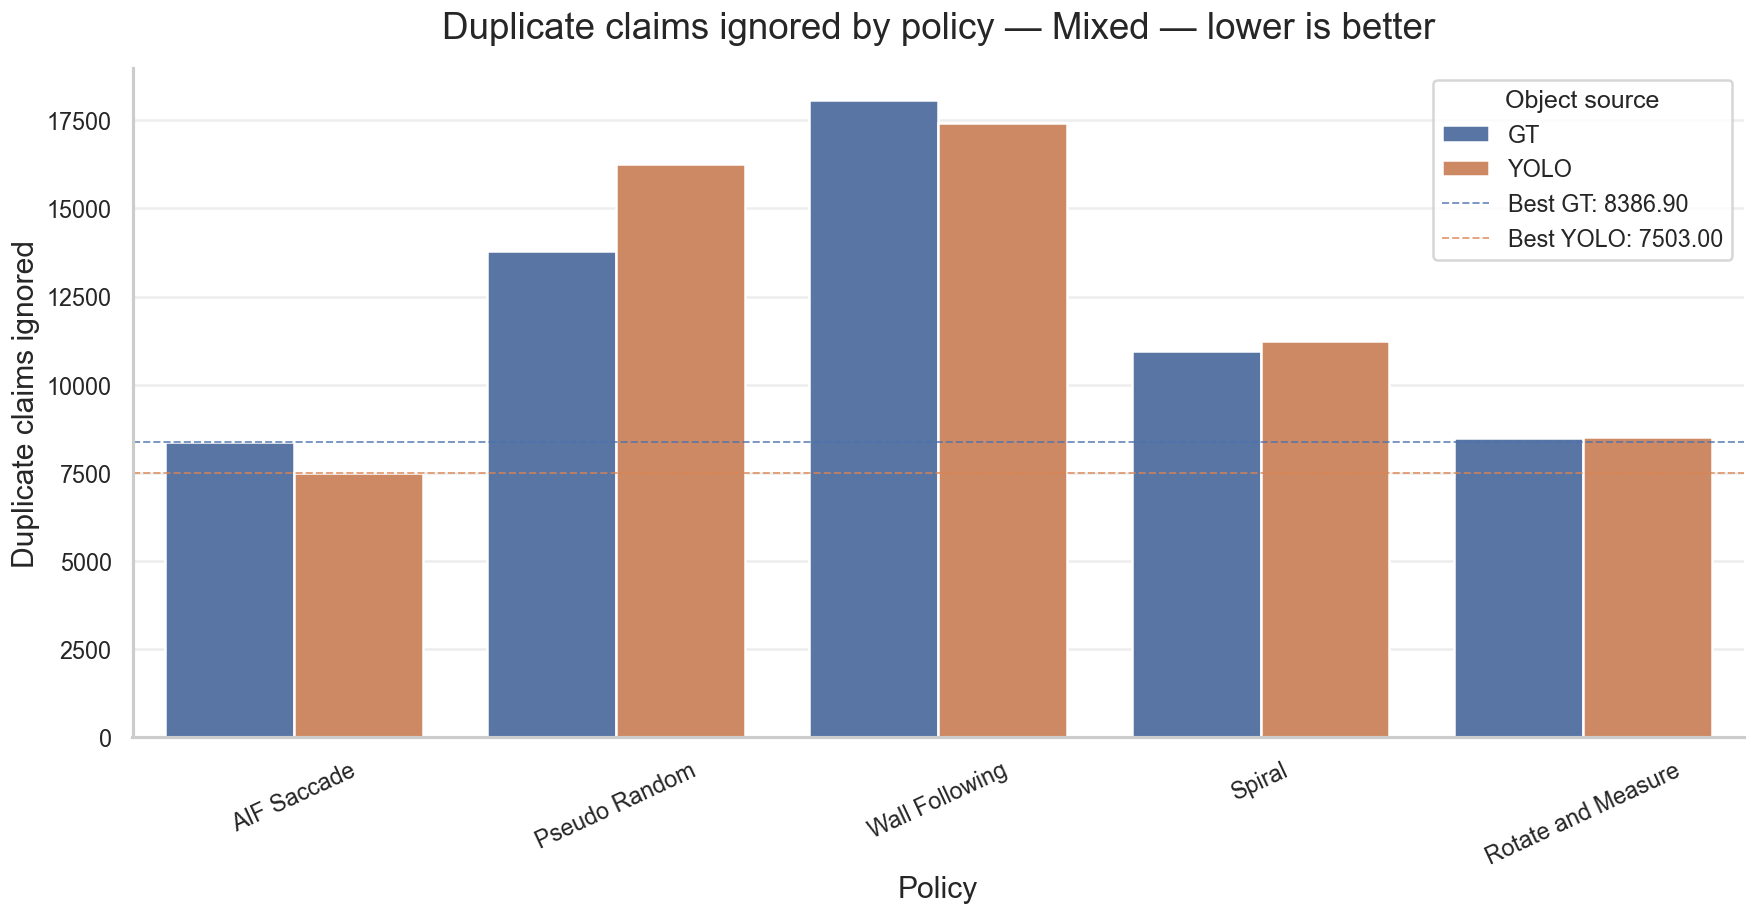

In [9]:
classification_available = [
    metric for metric in CLASSIFICATION_METRICS
    if metric_is_available(runs_df, metric)
]

if not classification_available:
    print("No classification metrics found. This is expected for bottles-only / GT-only reports.")
else:
    print("Classification metrics found:", classification_available)

    # Usually these are meaningful mainly for the Mixed dataset and YOLO detector,
    # but this loop will plot any dataset/condition where the metric exists.
    for metric in classification_available:
        for dataset in dataset_order:
            plot_metric_bar(metric, dataset)

## YOLO detector-limitation comparisons

Saved figure: figures_eval_comparison/bottles_only__success__yolo_conditions.png


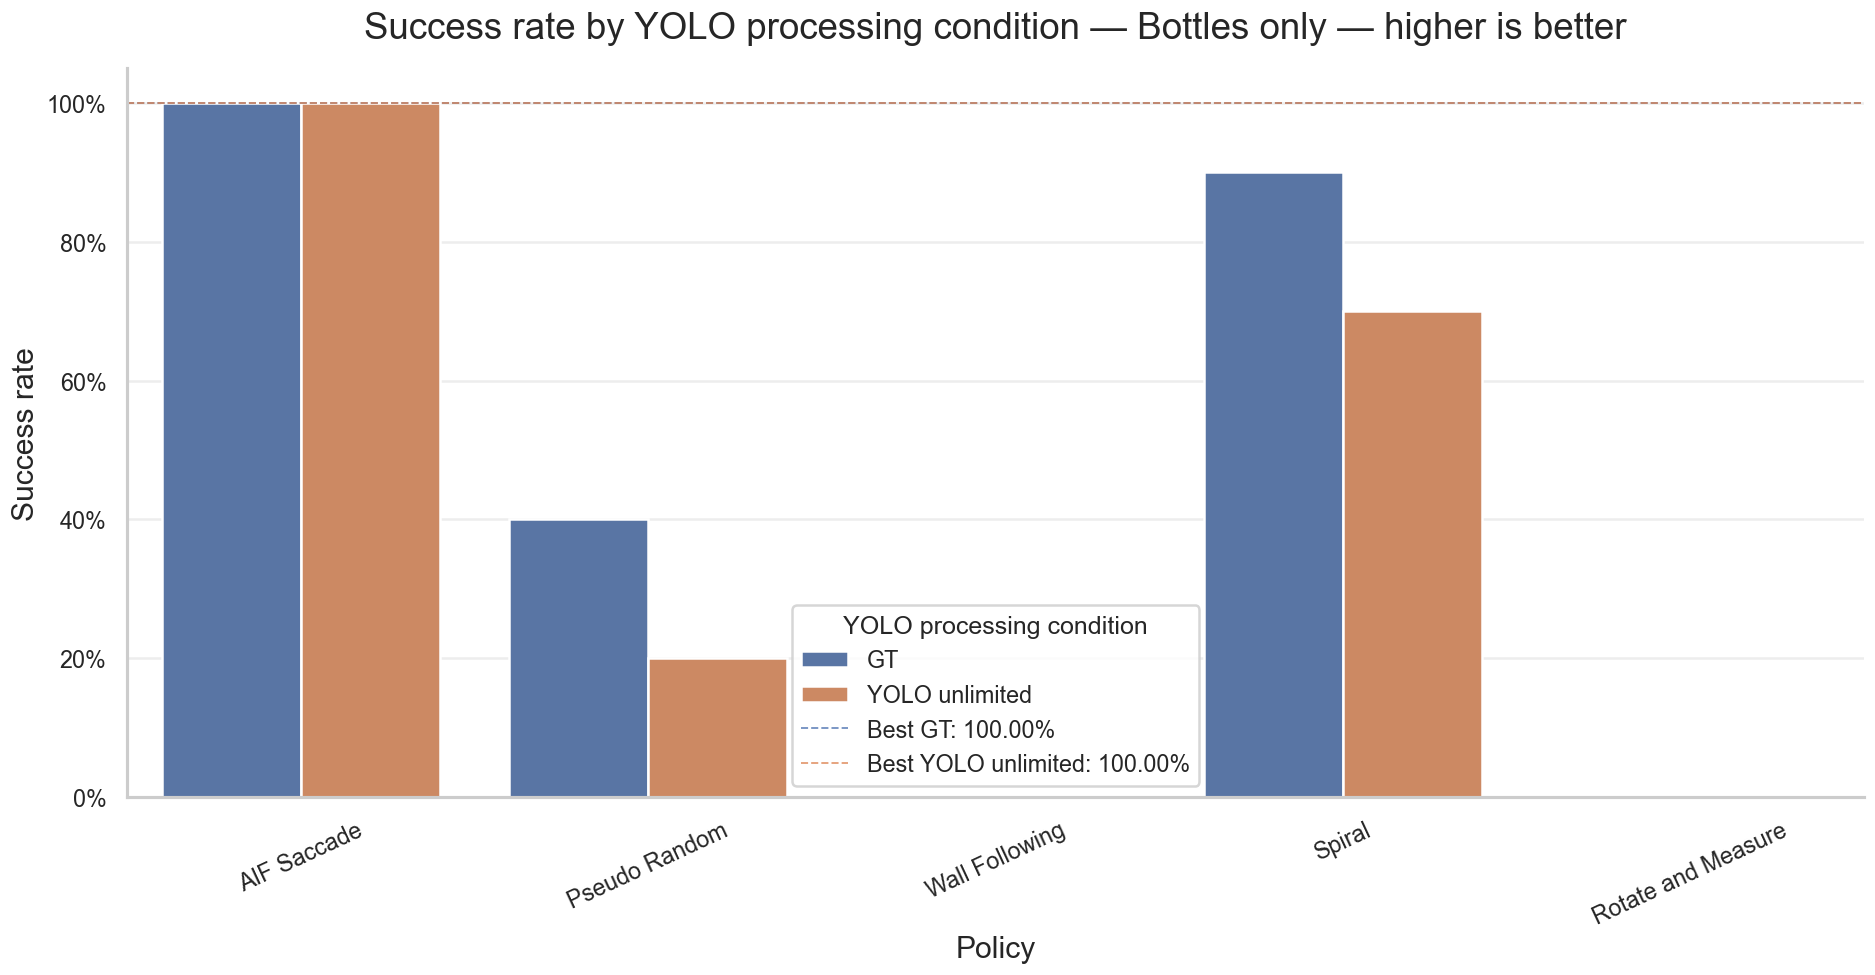

Saved figure: figures_eval_comparison/mixed__success__yolo_conditions.png


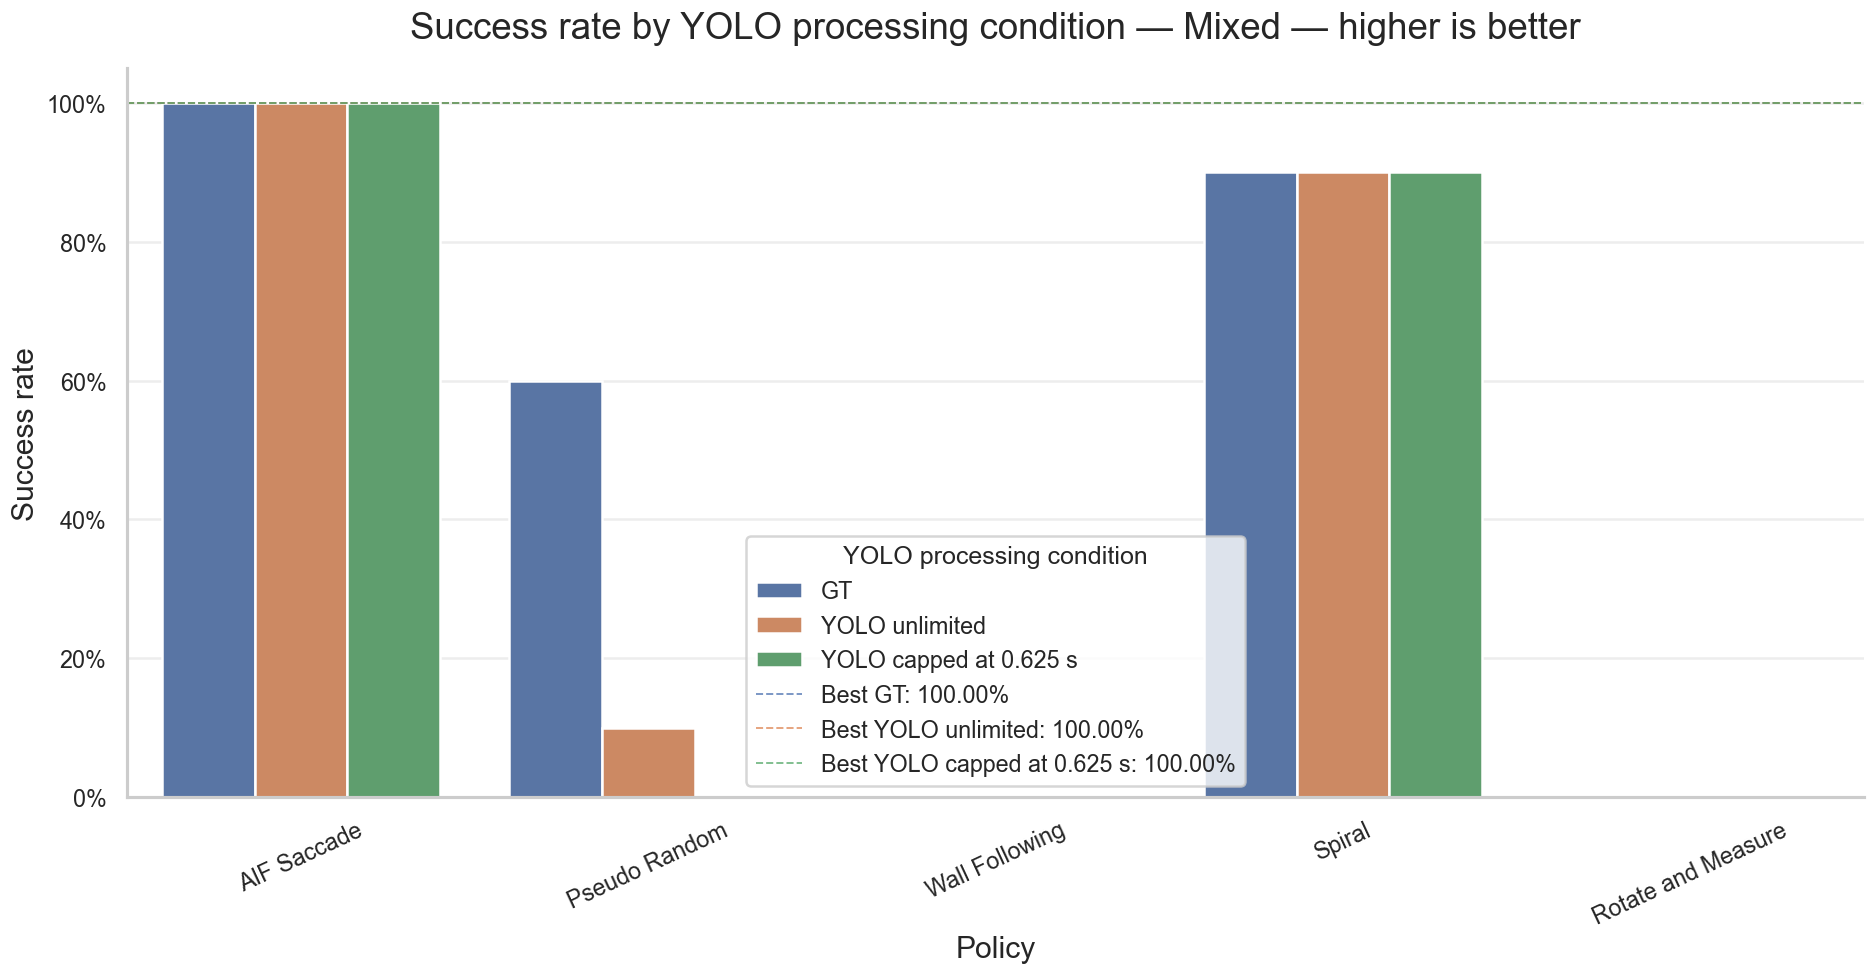

Saved figure: figures_eval_comparison/bottles_only__detected_objects_ratio__yolo_conditions.png


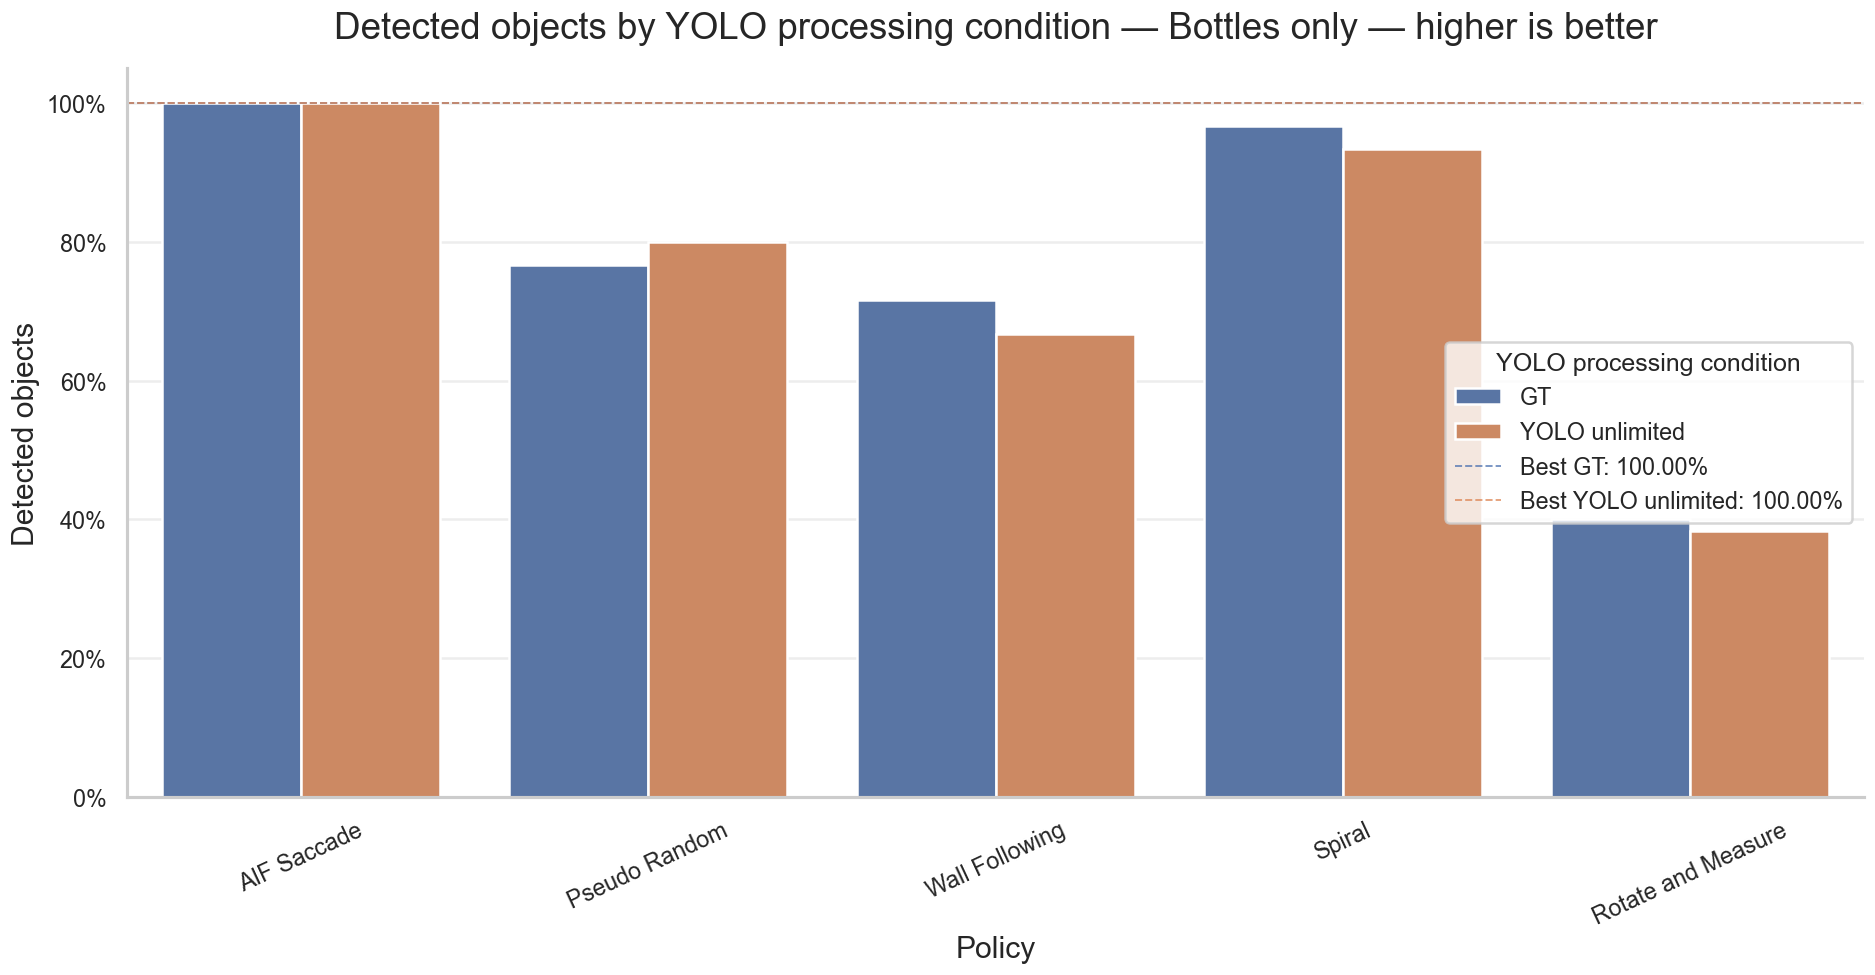

Saved figure: figures_eval_comparison/mixed__detected_objects_ratio__yolo_conditions.png


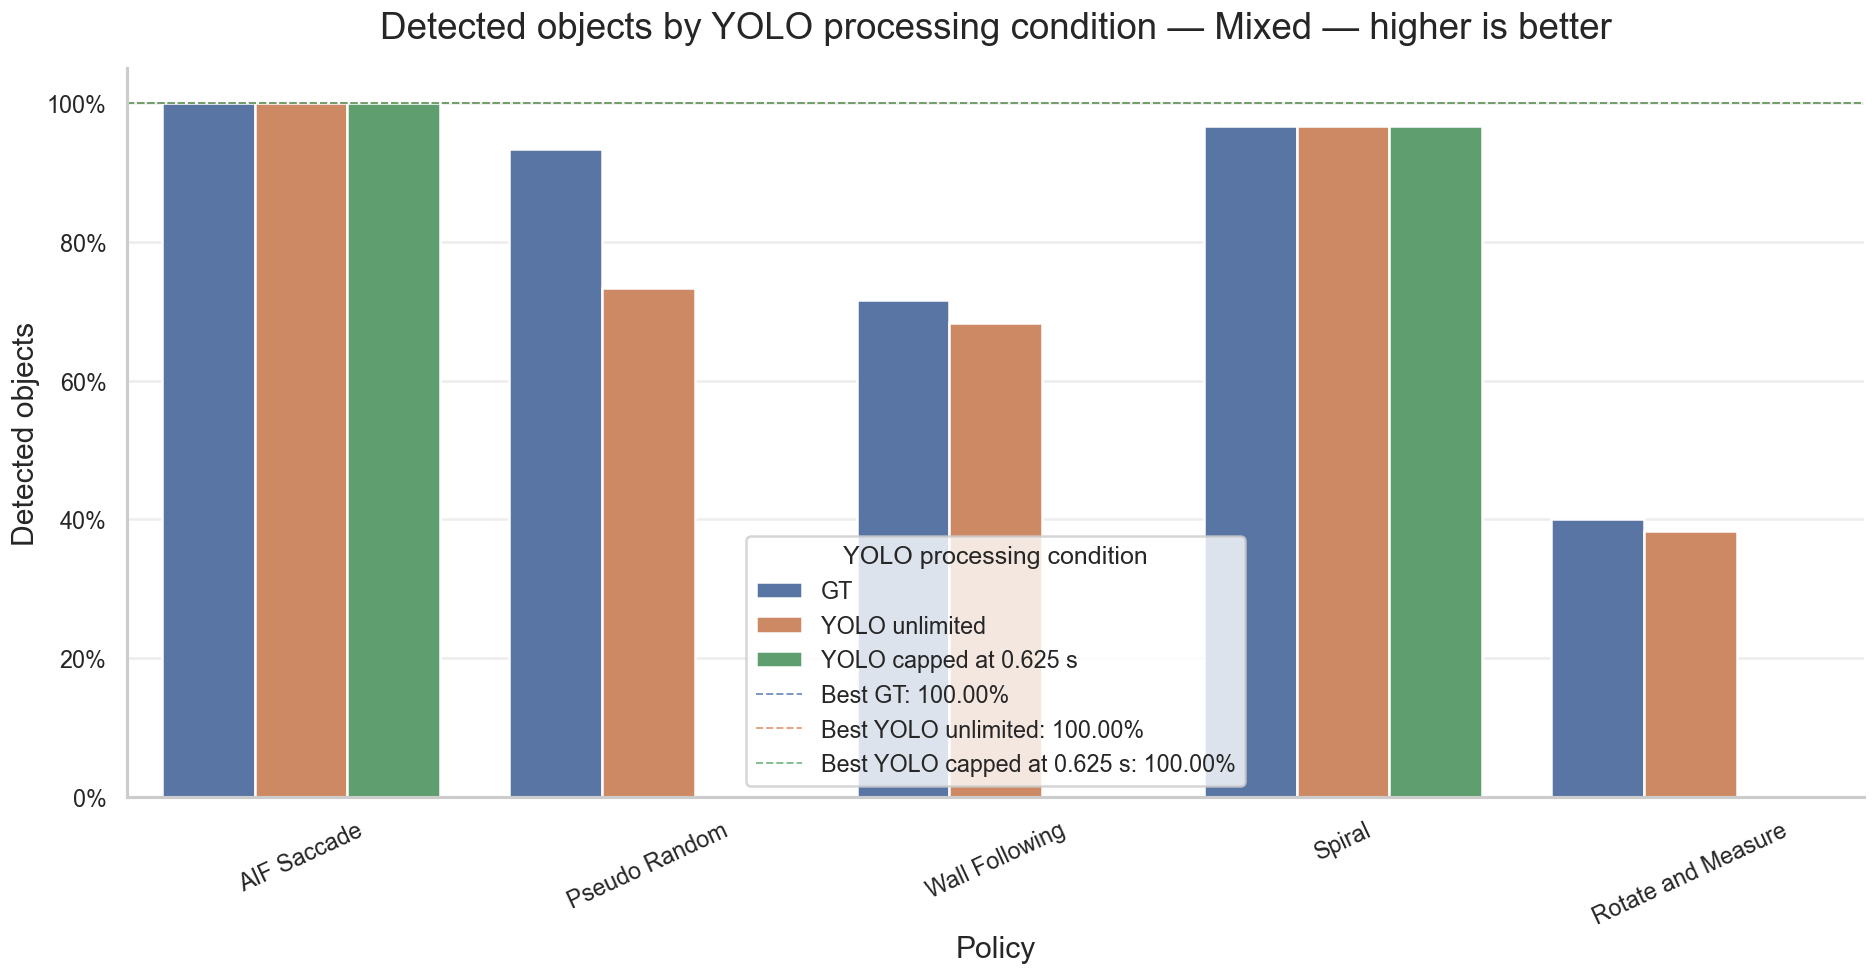

Saved figure: figures_eval_comparison/bottles_only__elapsed_s__yolo_conditions.png


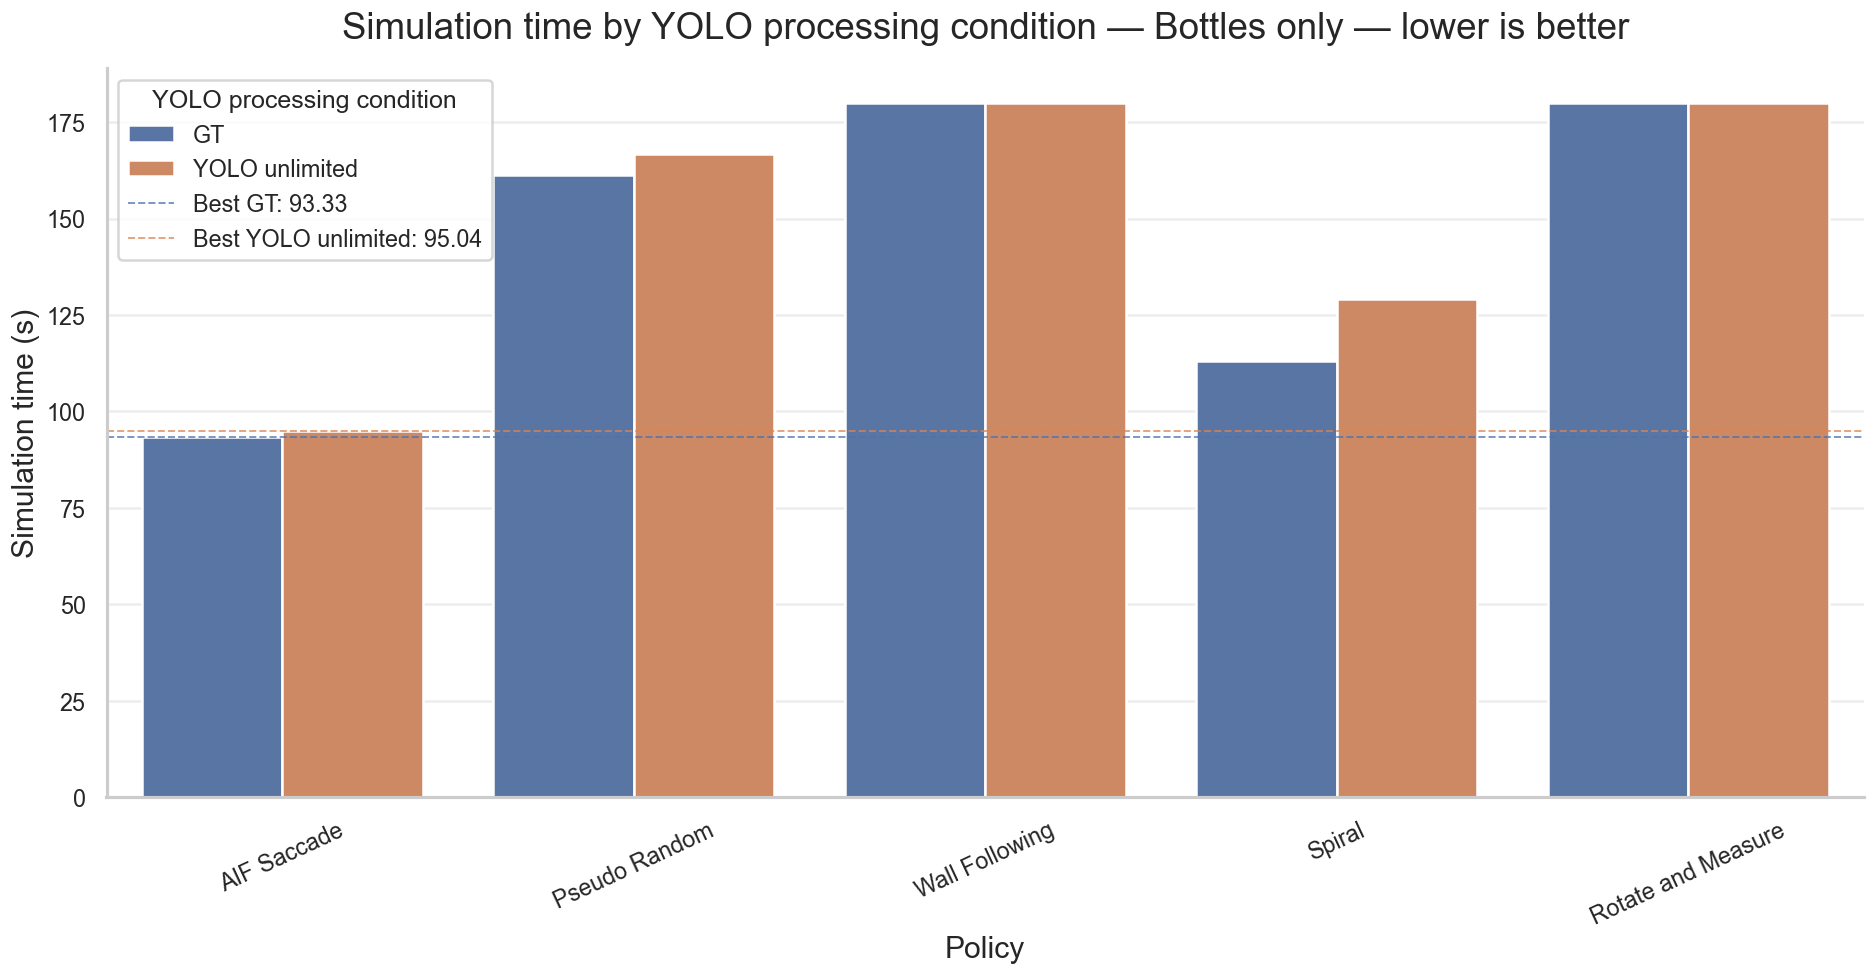

Saved figure: figures_eval_comparison/mixed__elapsed_s__yolo_conditions.png


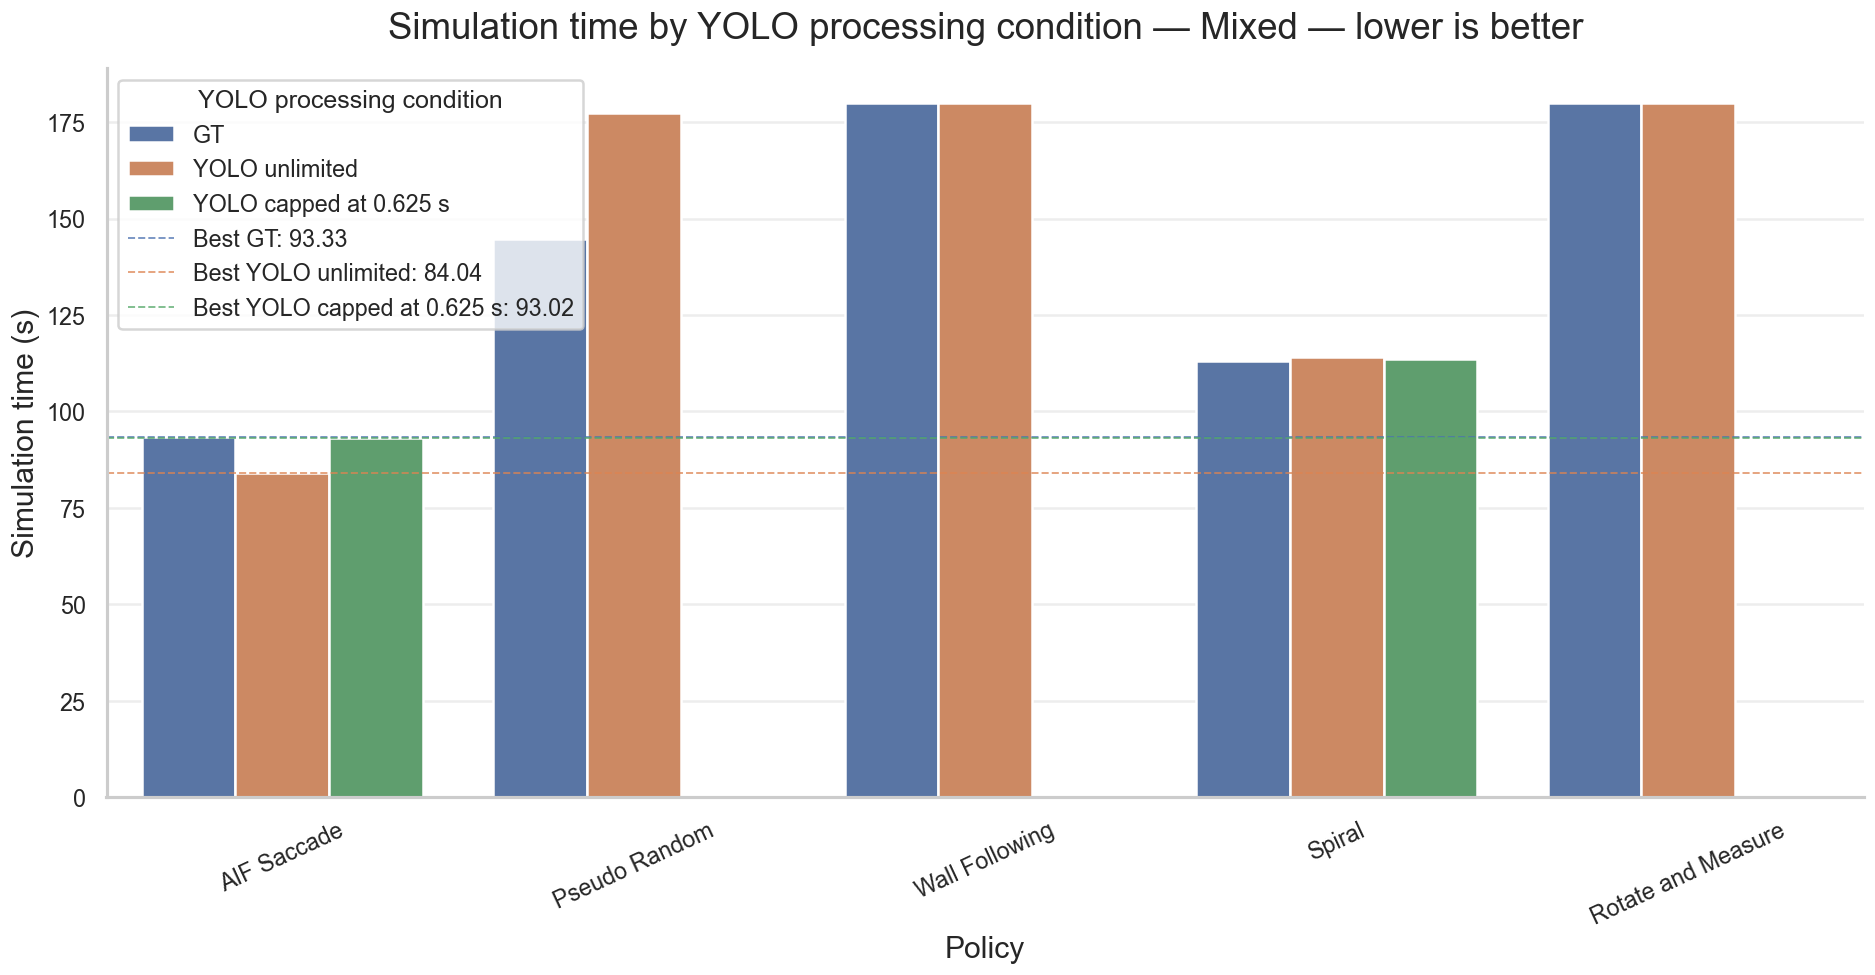

Saved figure: figures_eval_comparison/bottles_only__found_count__yolo_conditions.png


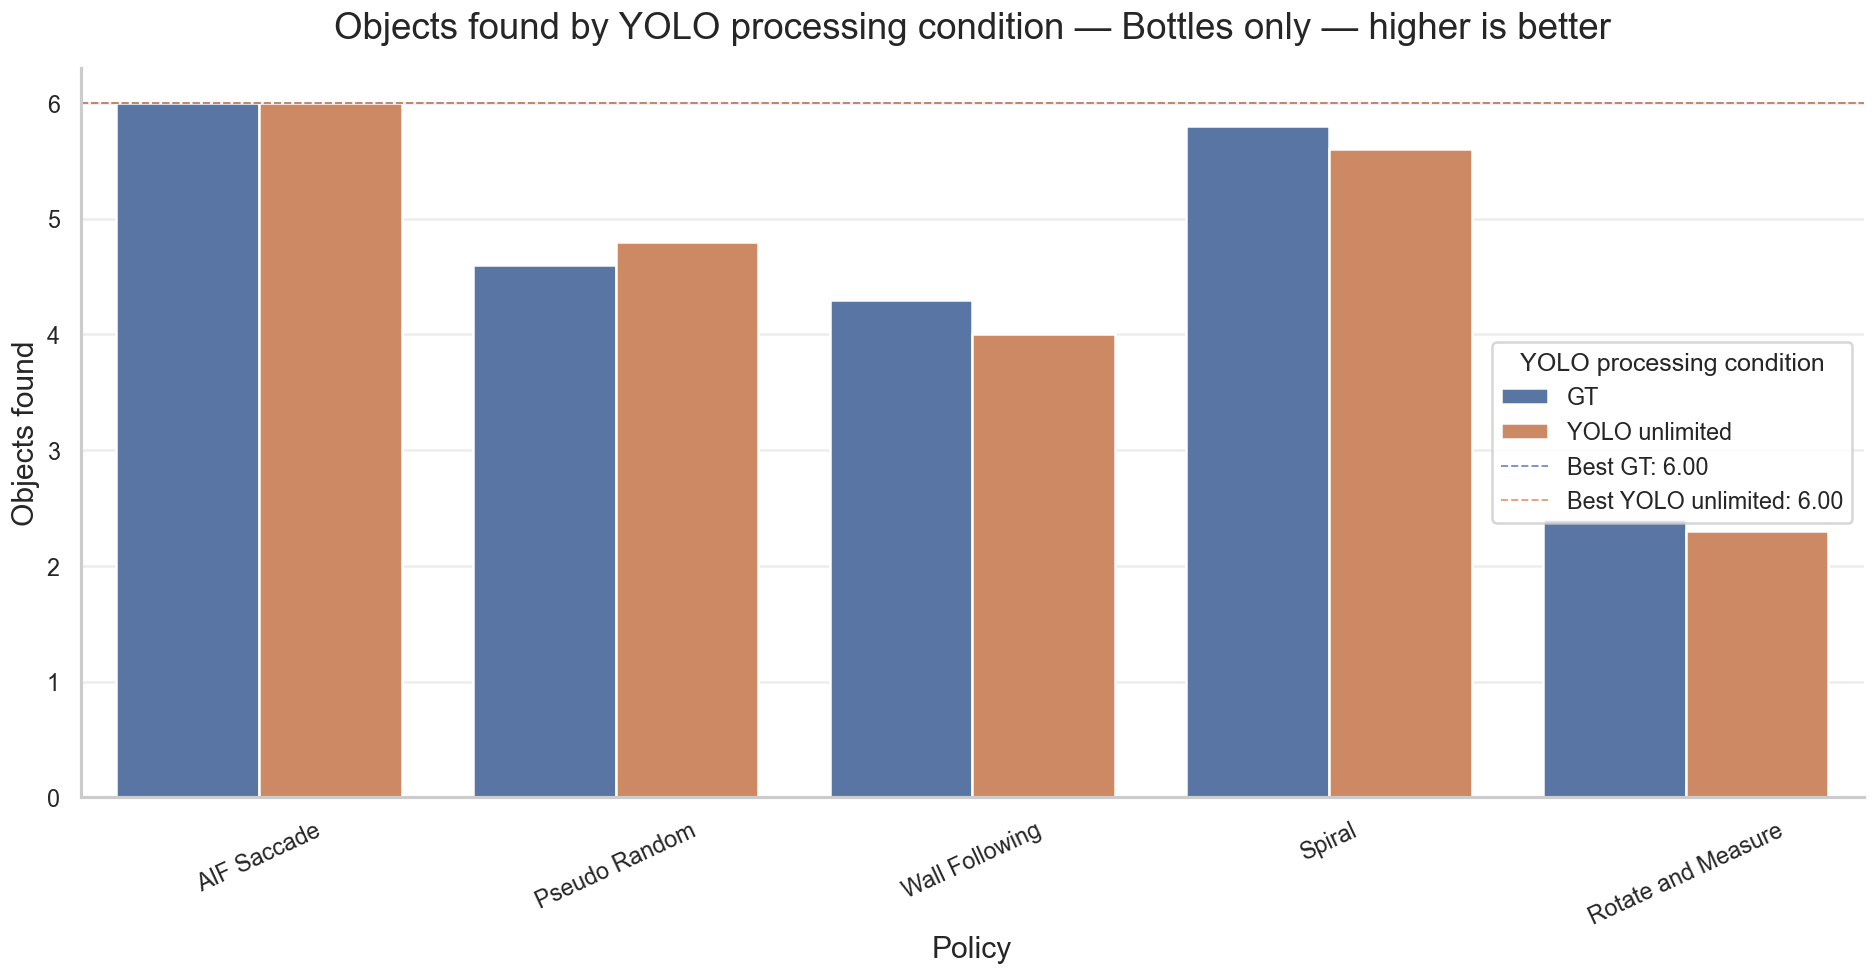

Saved figure: figures_eval_comparison/mixed__found_count__yolo_conditions.png


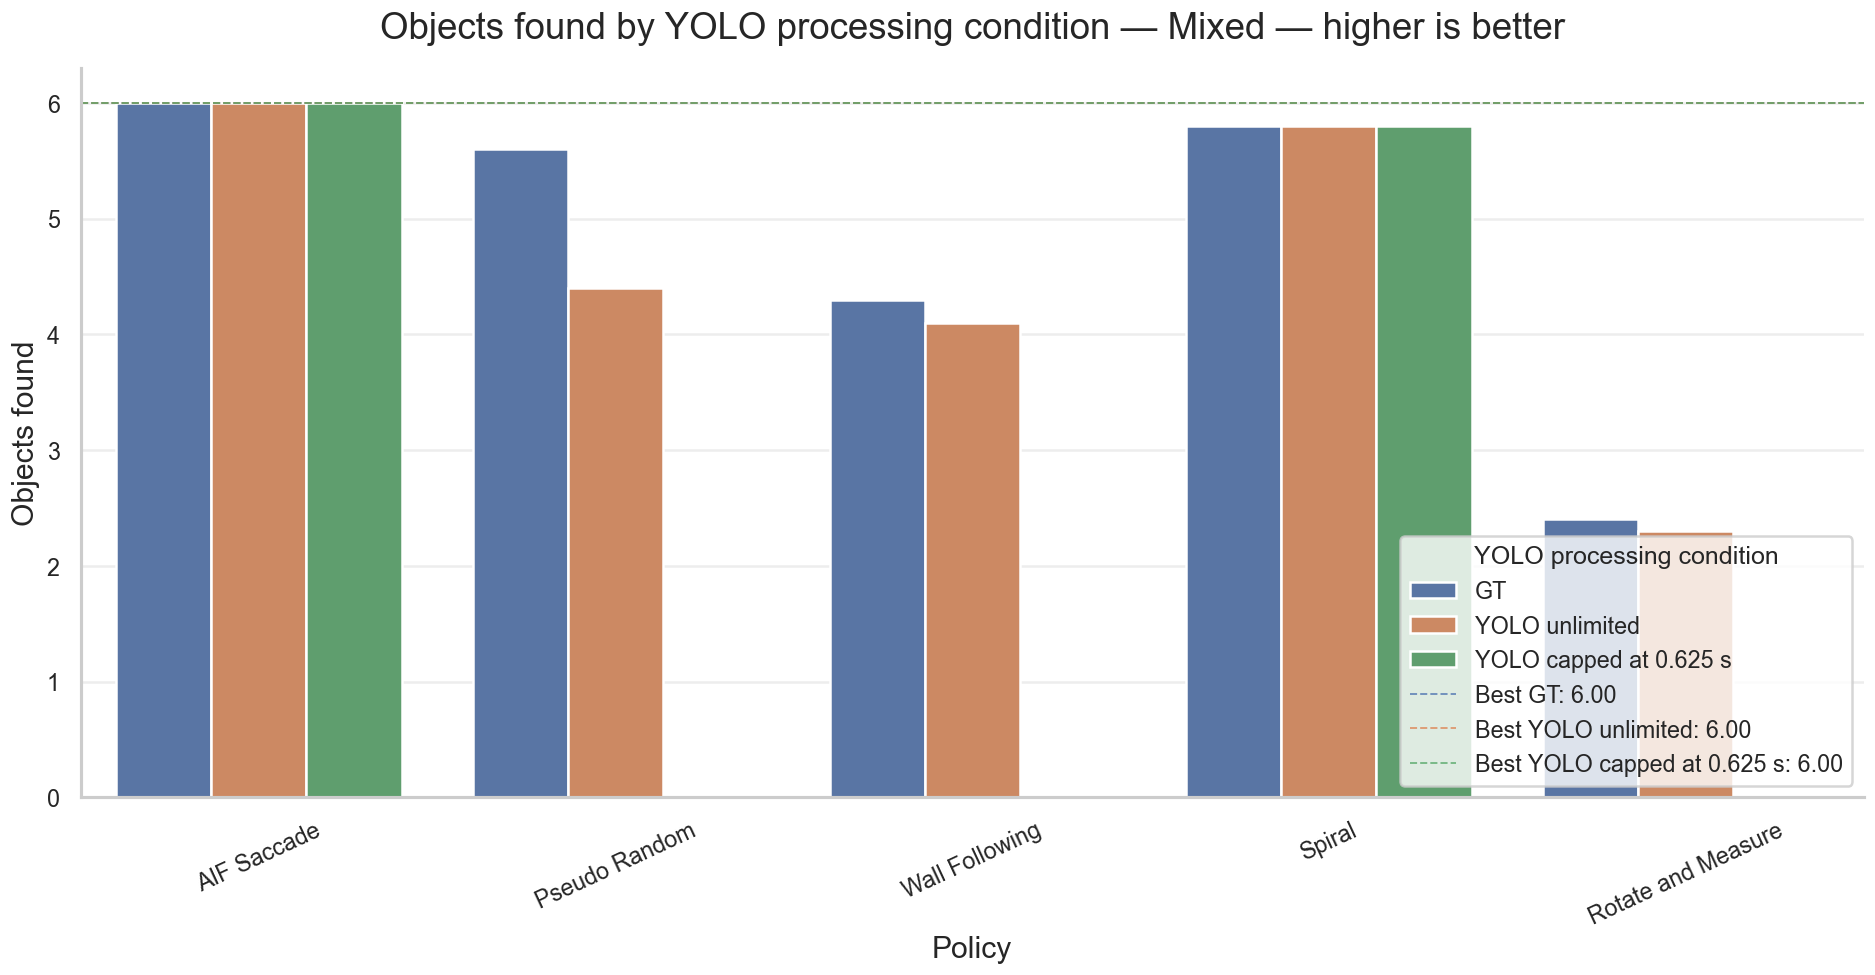

Saved figure: figures_eval_comparison/bottles_only__remaining_objects__yolo_conditions.png


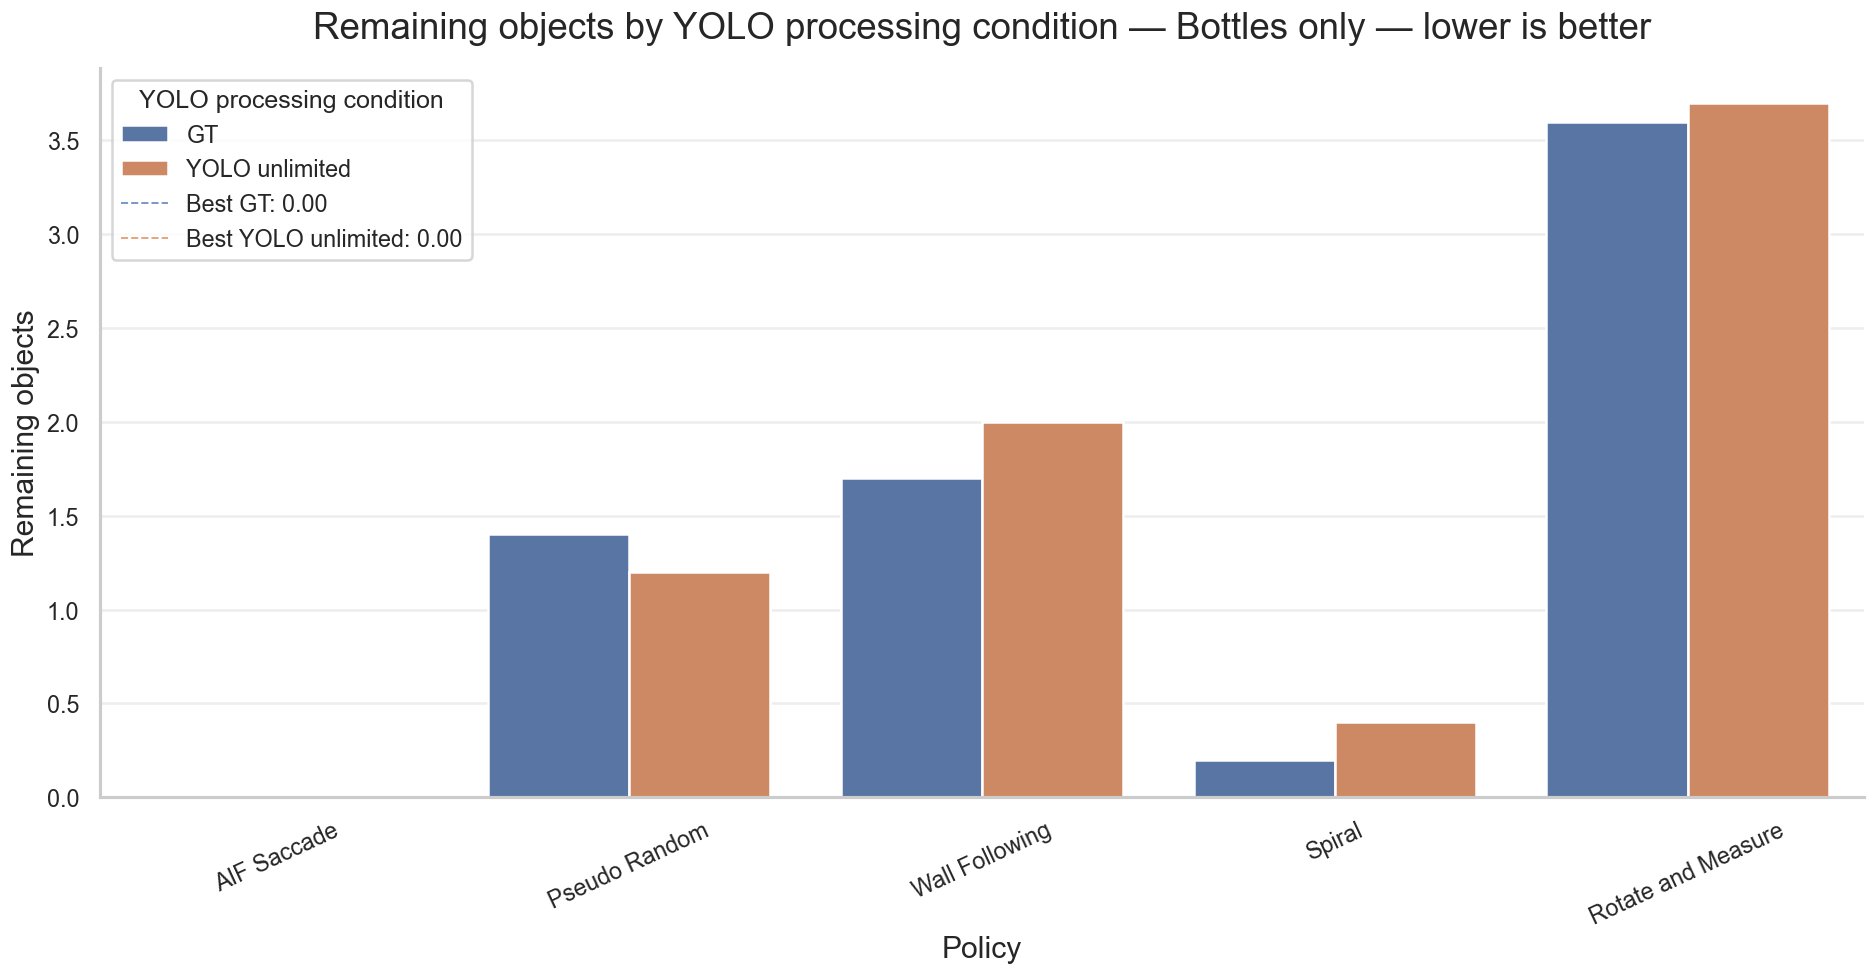

Saved figure: figures_eval_comparison/mixed__remaining_objects__yolo_conditions.png


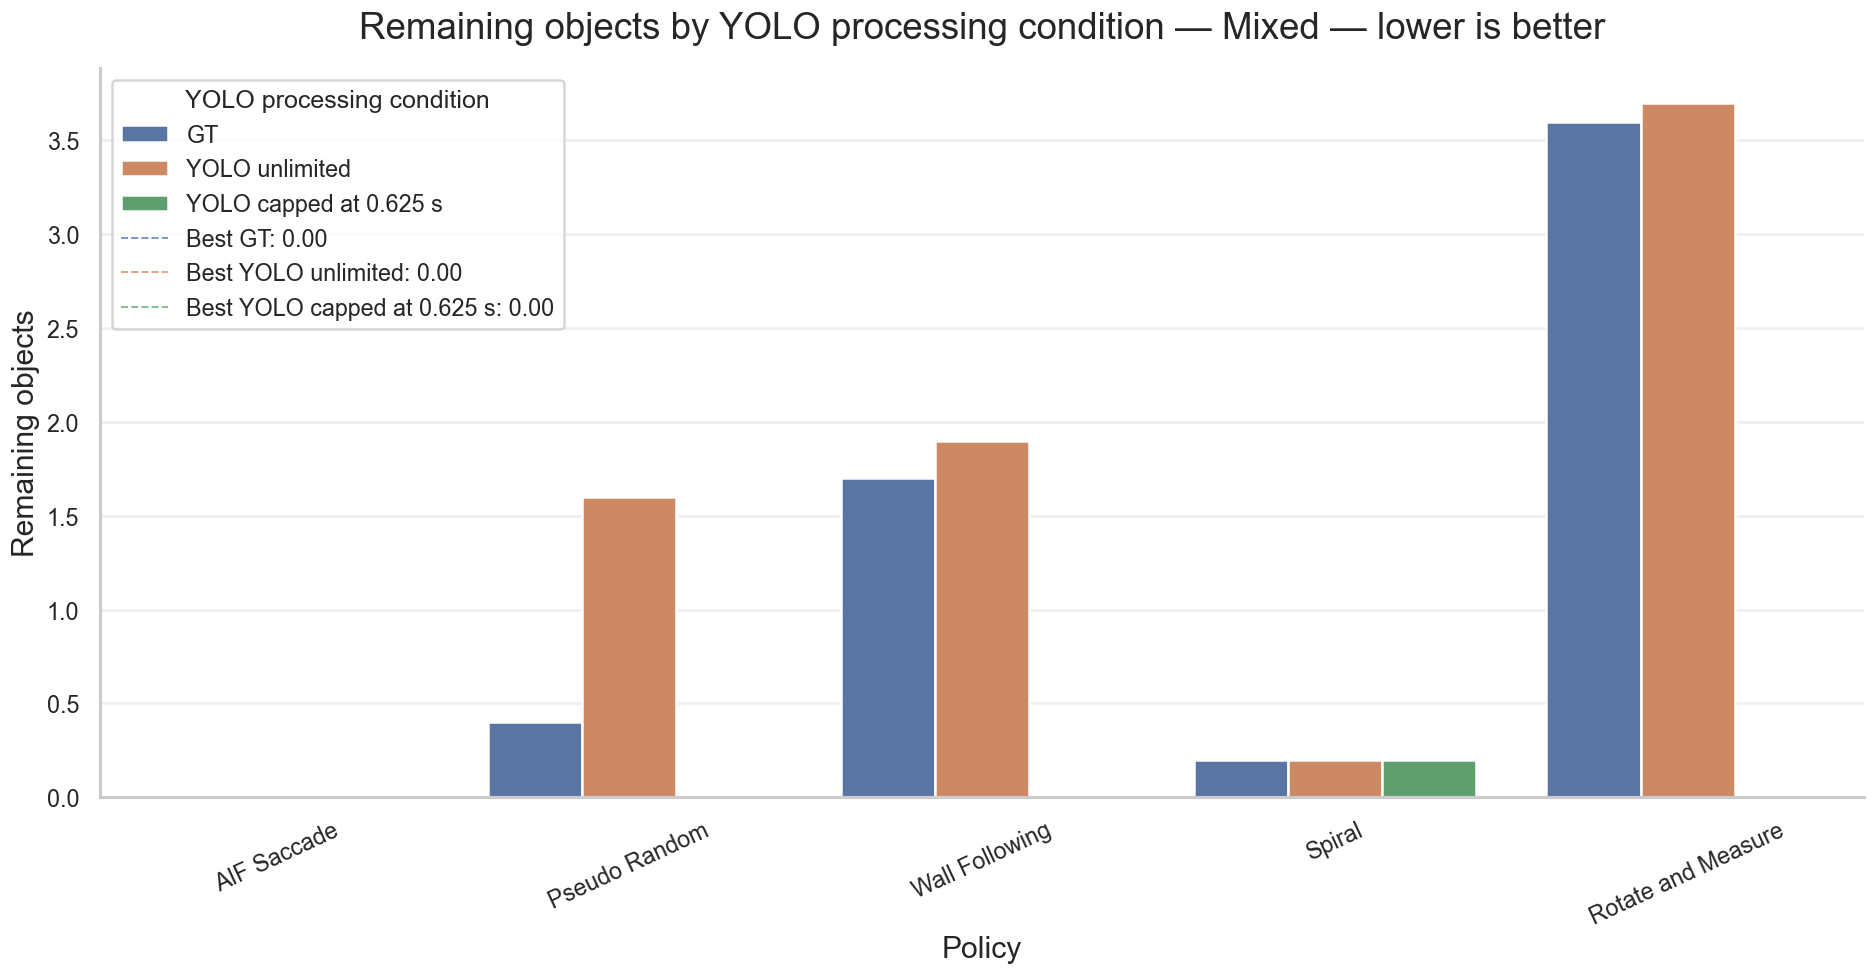

Saved figure: figures_eval_comparison/bottles_only__coverage_ratio__yolo_conditions.png


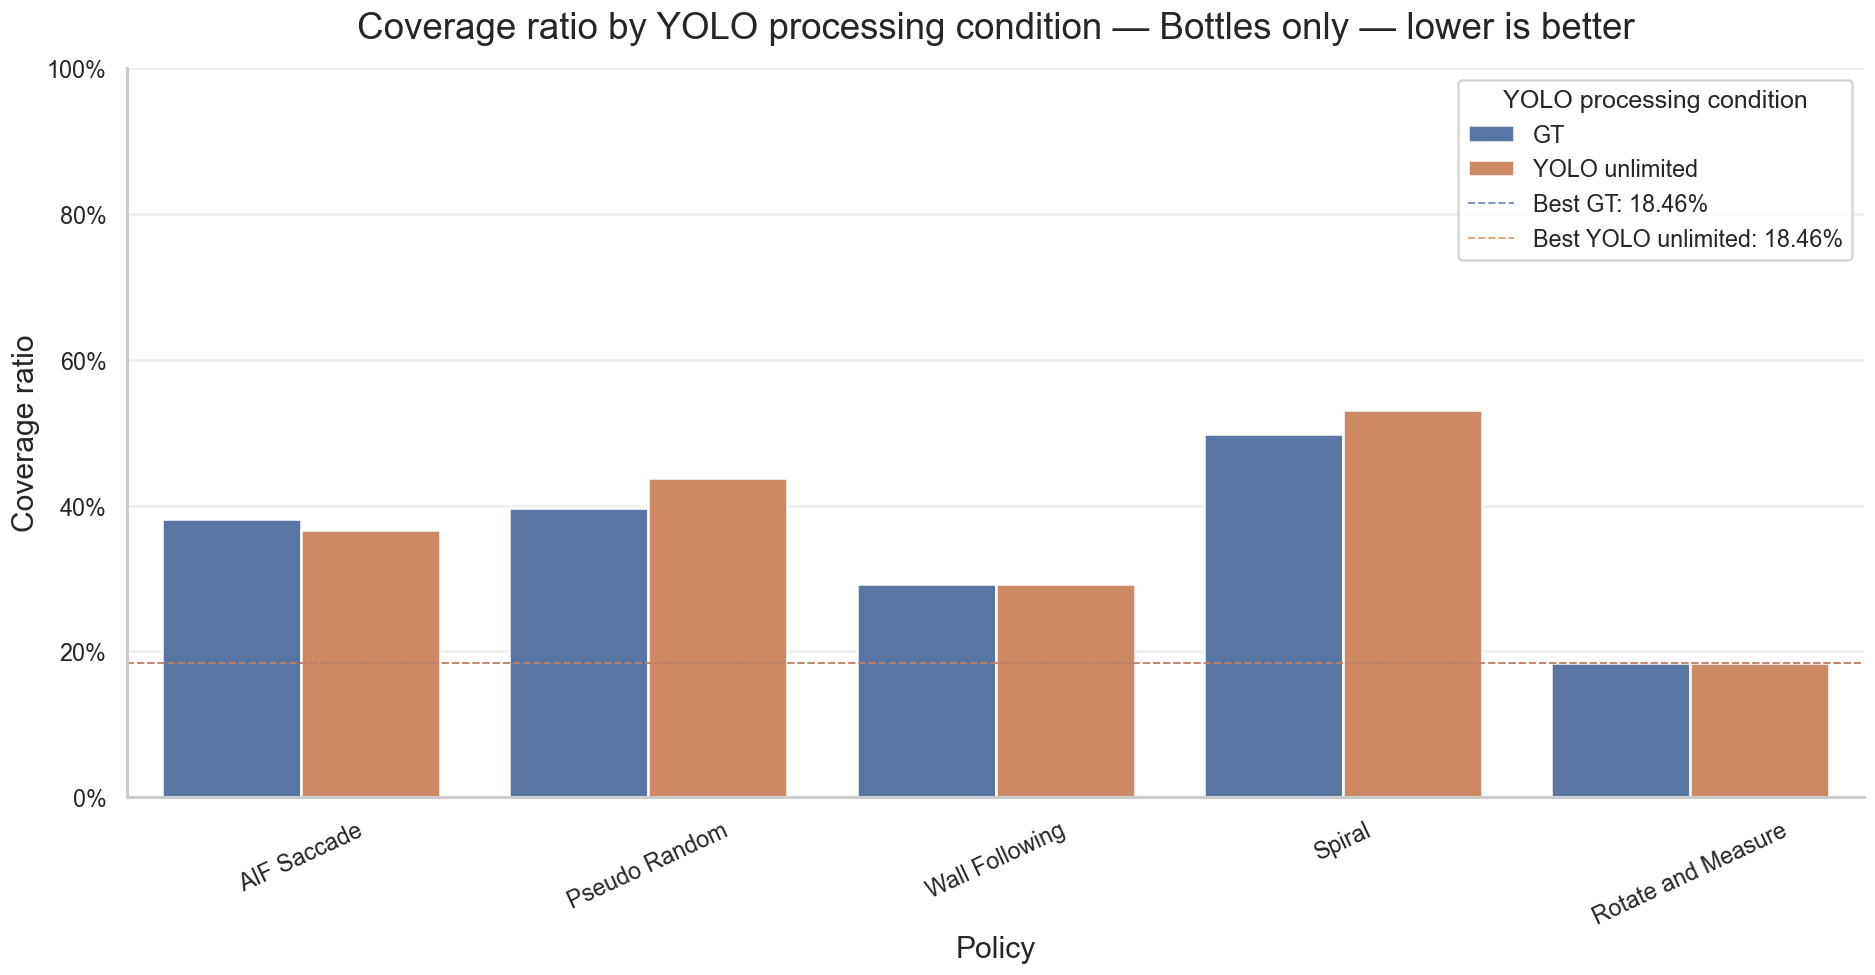

Saved figure: figures_eval_comparison/mixed__coverage_ratio__yolo_conditions.png


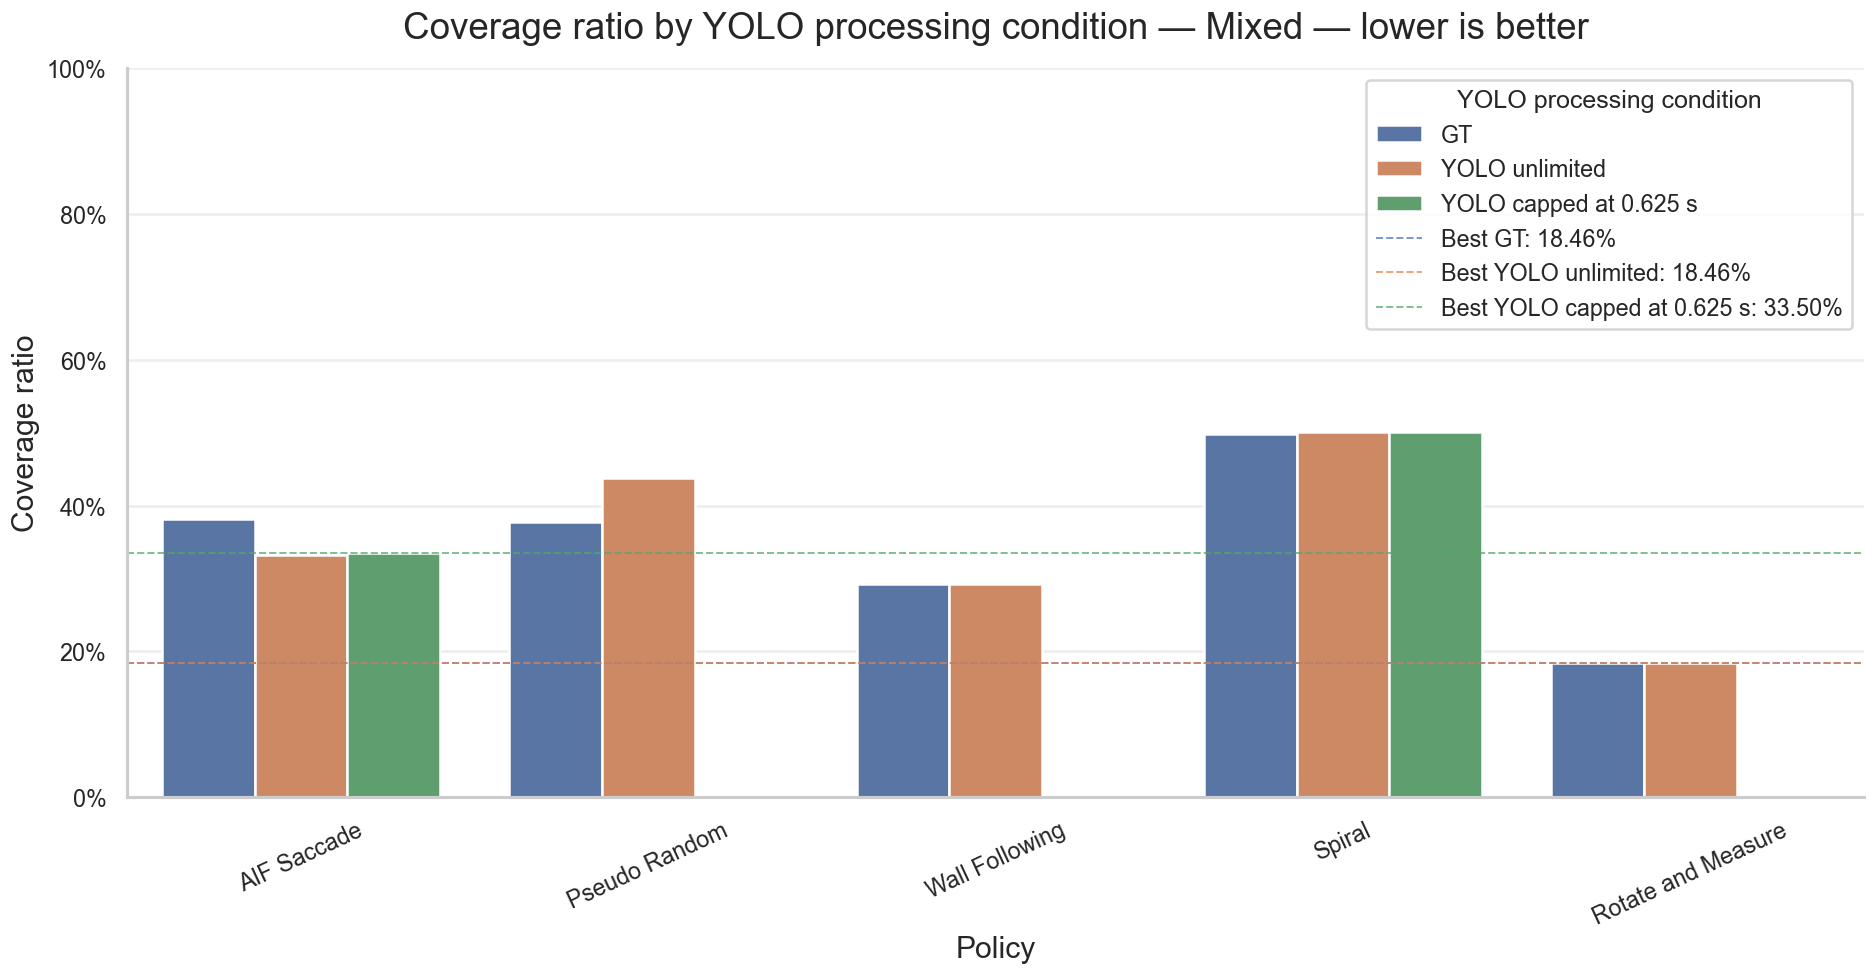

In [15]:
display(Markdown("## YOLO detector-limitation comparisons"))

for metric in BASE_METRICS:
    if not metric_is_available(runs_df, metric):
        print(f"Skipping {metric}: not available.")
        continue

    for dataset in dataset_order:
        plot_metric_bar_by_condition(metric, dataset, include_gt=True)

## YOLO detector-limitation comparisons — classification metrics

Skipping Overall claim precision for Bottles only: no YOLO condition values.
Saved figure: figures_eval_comparison/mixed__overall_claim_precision__yolo_conditions.png


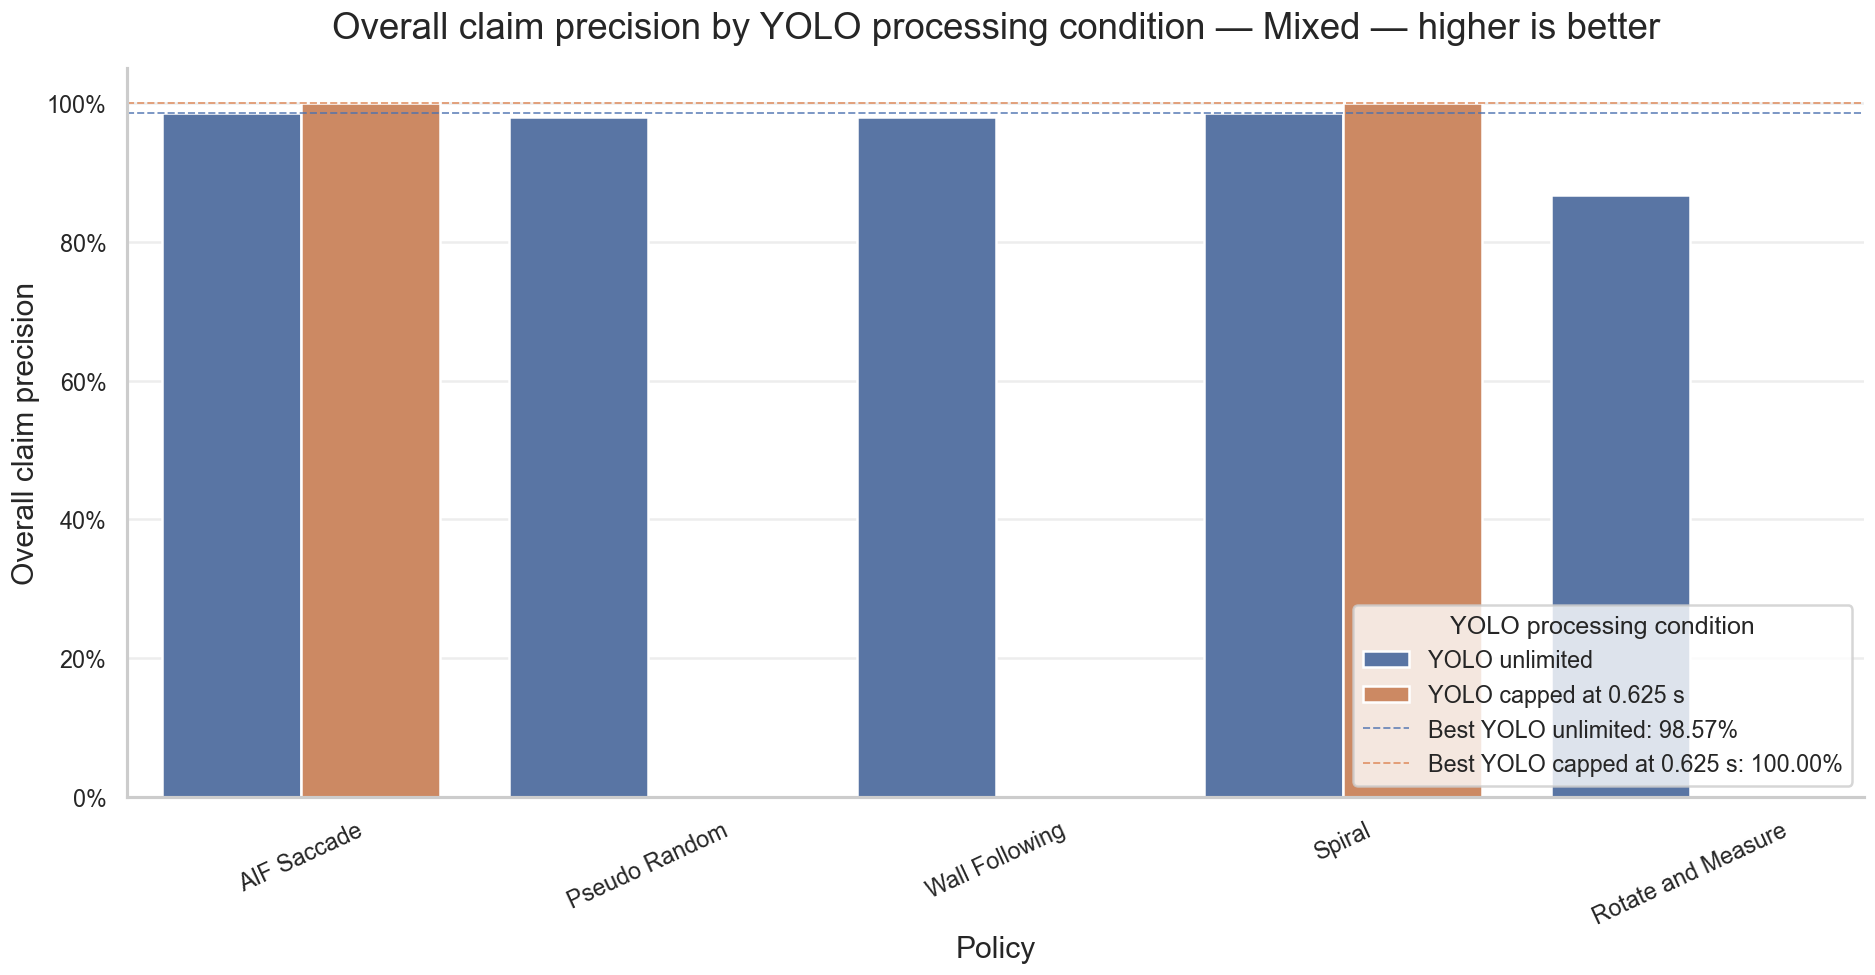

Skipping Object-cell class accuracy for Bottles only: no YOLO condition values.
Saved figure: figures_eval_comparison/mixed__object_cell_class_accuracy__yolo_conditions.png


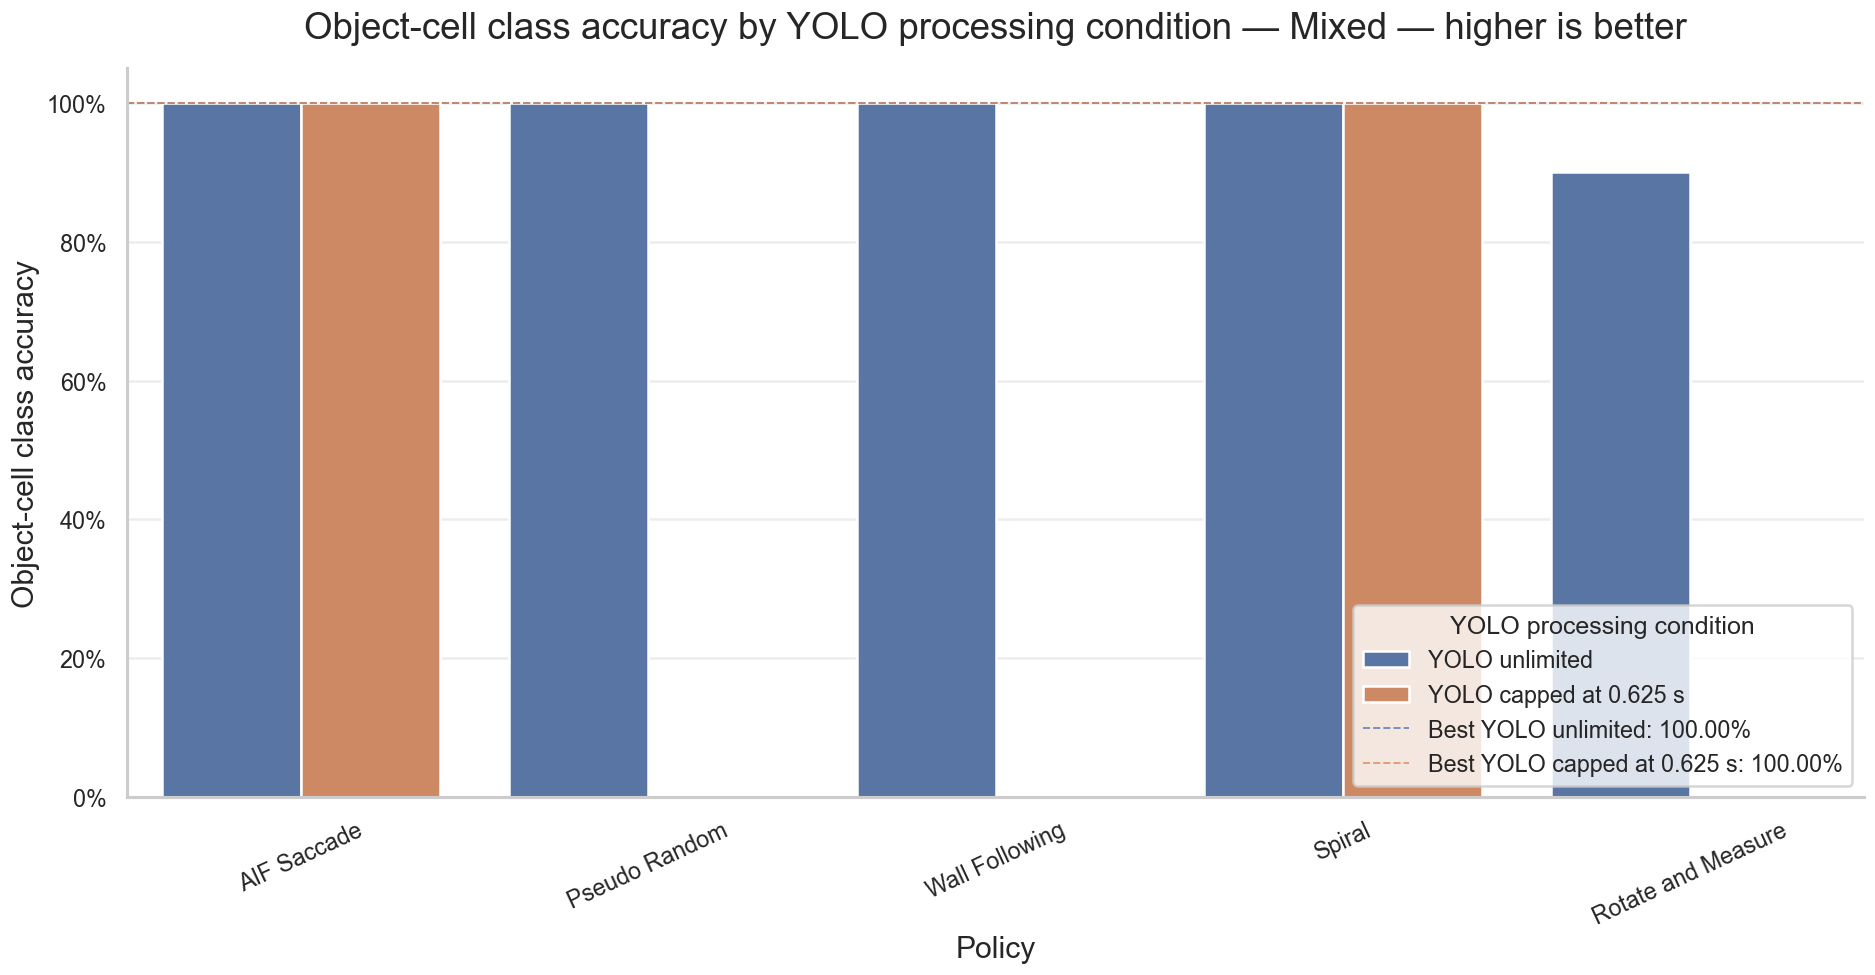

Skipping Unique claims evaluated for Bottles only: no YOLO condition values.
Saved figure: figures_eval_comparison/mixed__unique_claims_evaluated__yolo_conditions.png


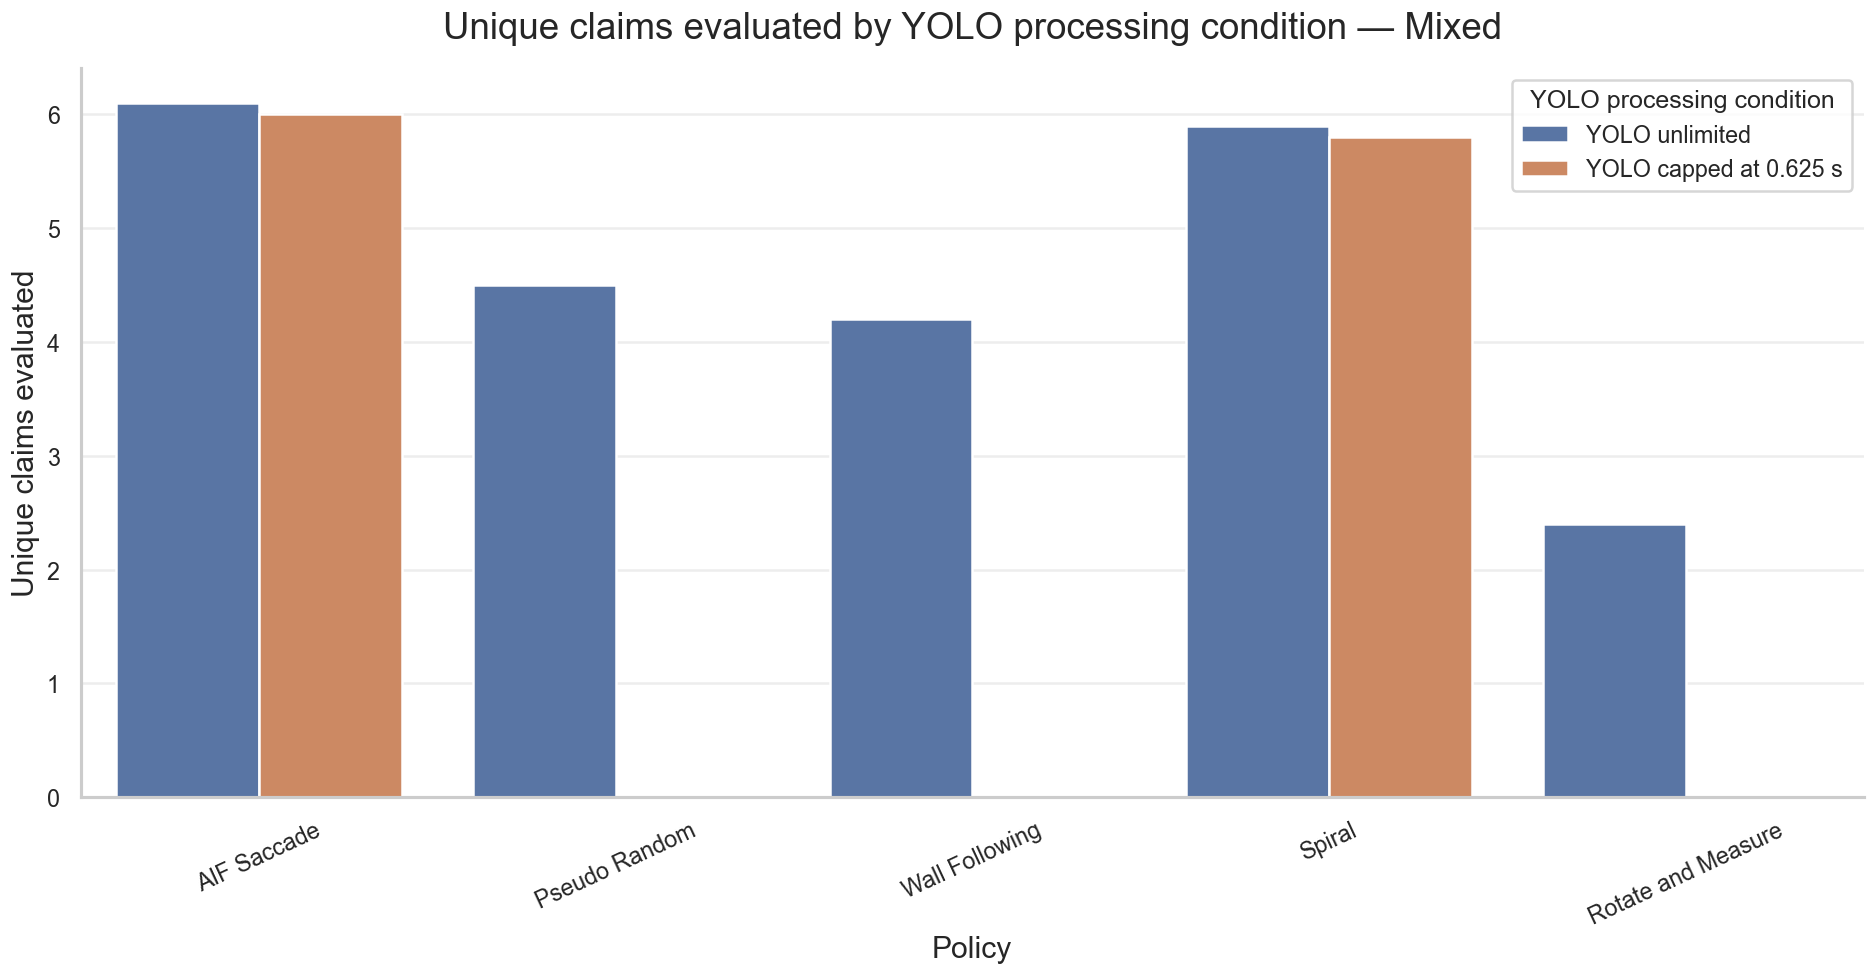

Skipping Correct class claims for Bottles only: no YOLO condition values.
Saved figure: figures_eval_comparison/mixed__correct_class_claims__yolo_conditions.png


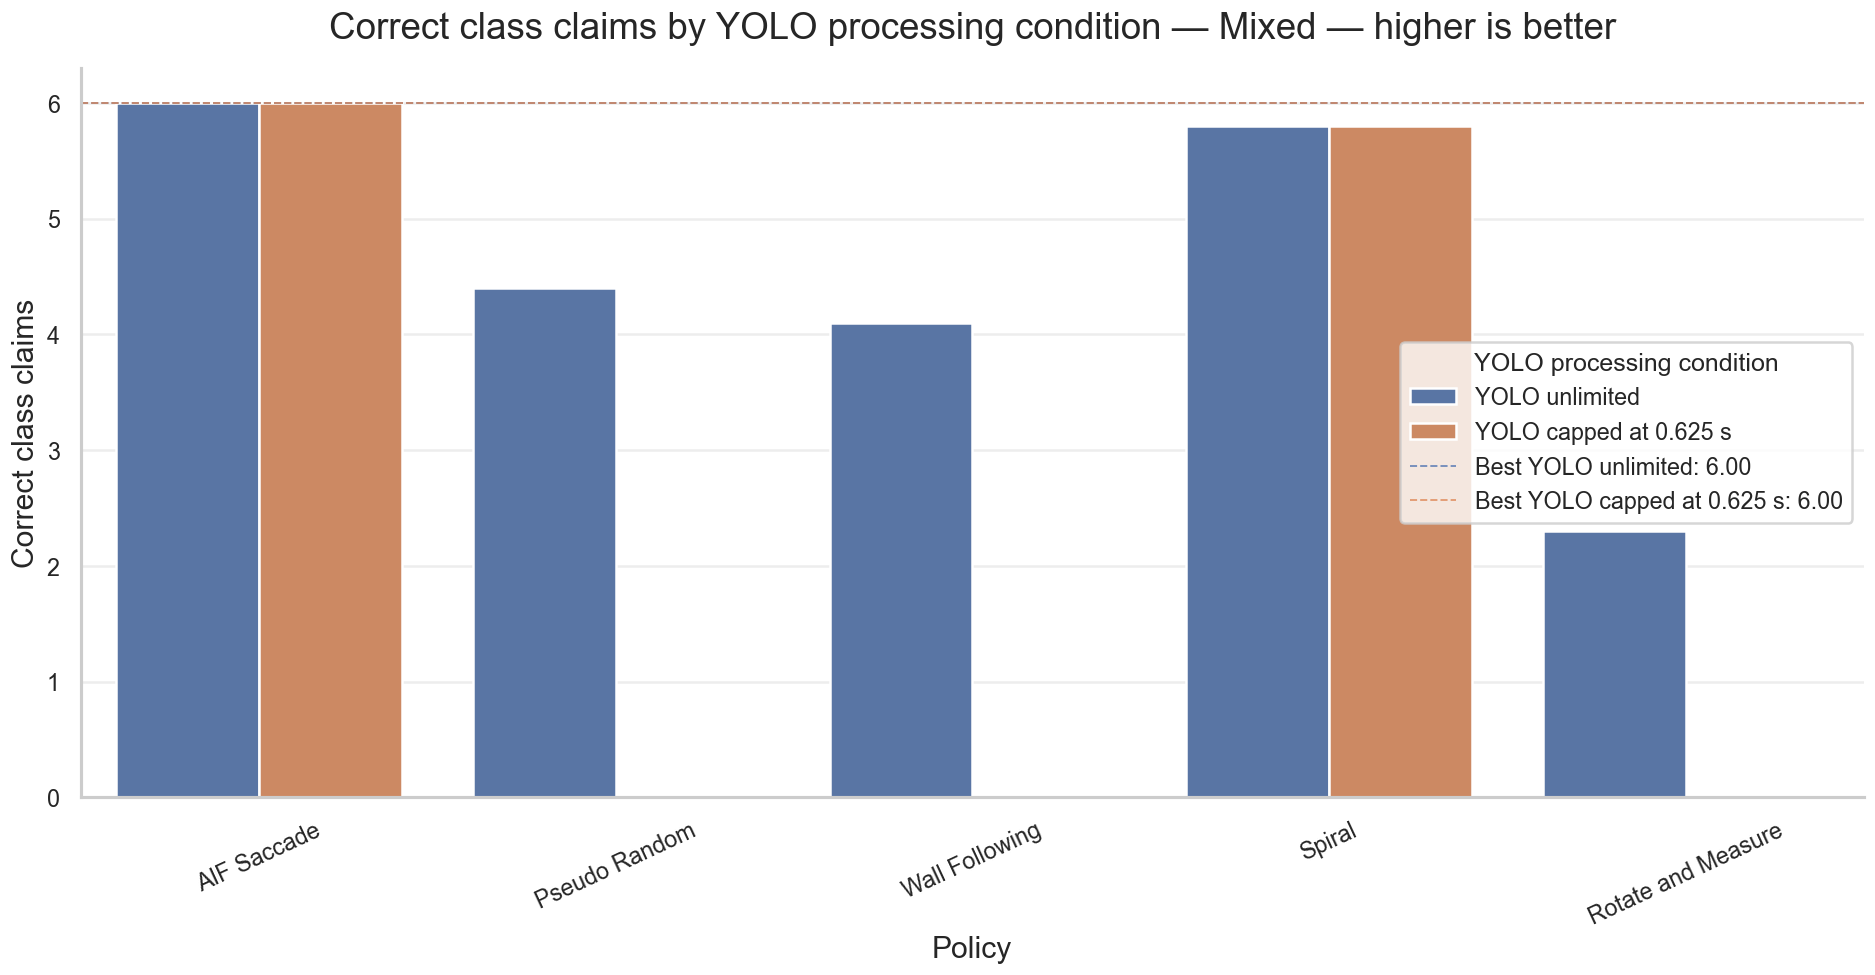

Skipping Wrong class claims for Bottles only: no YOLO condition values.
Saved figure: figures_eval_comparison/mixed__wrong_class_claims__yolo_conditions.png


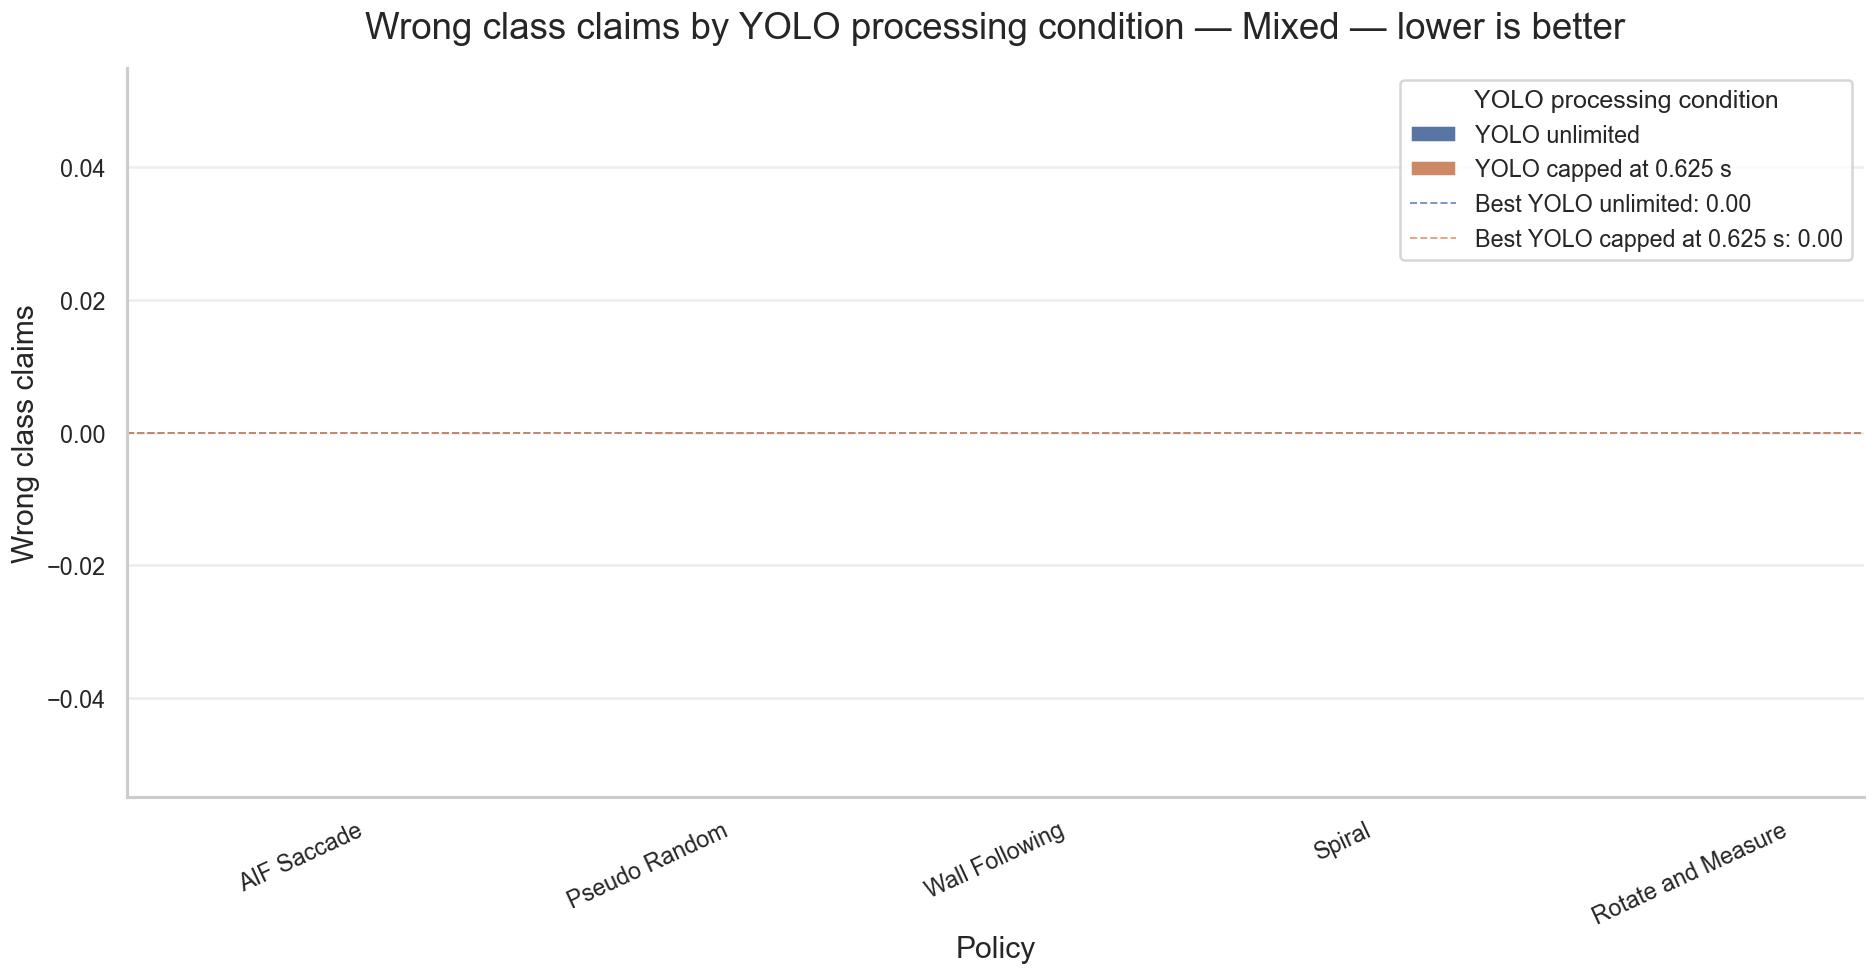

Skipping Empty-cell claims for Bottles only: no YOLO condition values.
Saved figure: figures_eval_comparison/mixed__empty_cell_claims__yolo_conditions.png


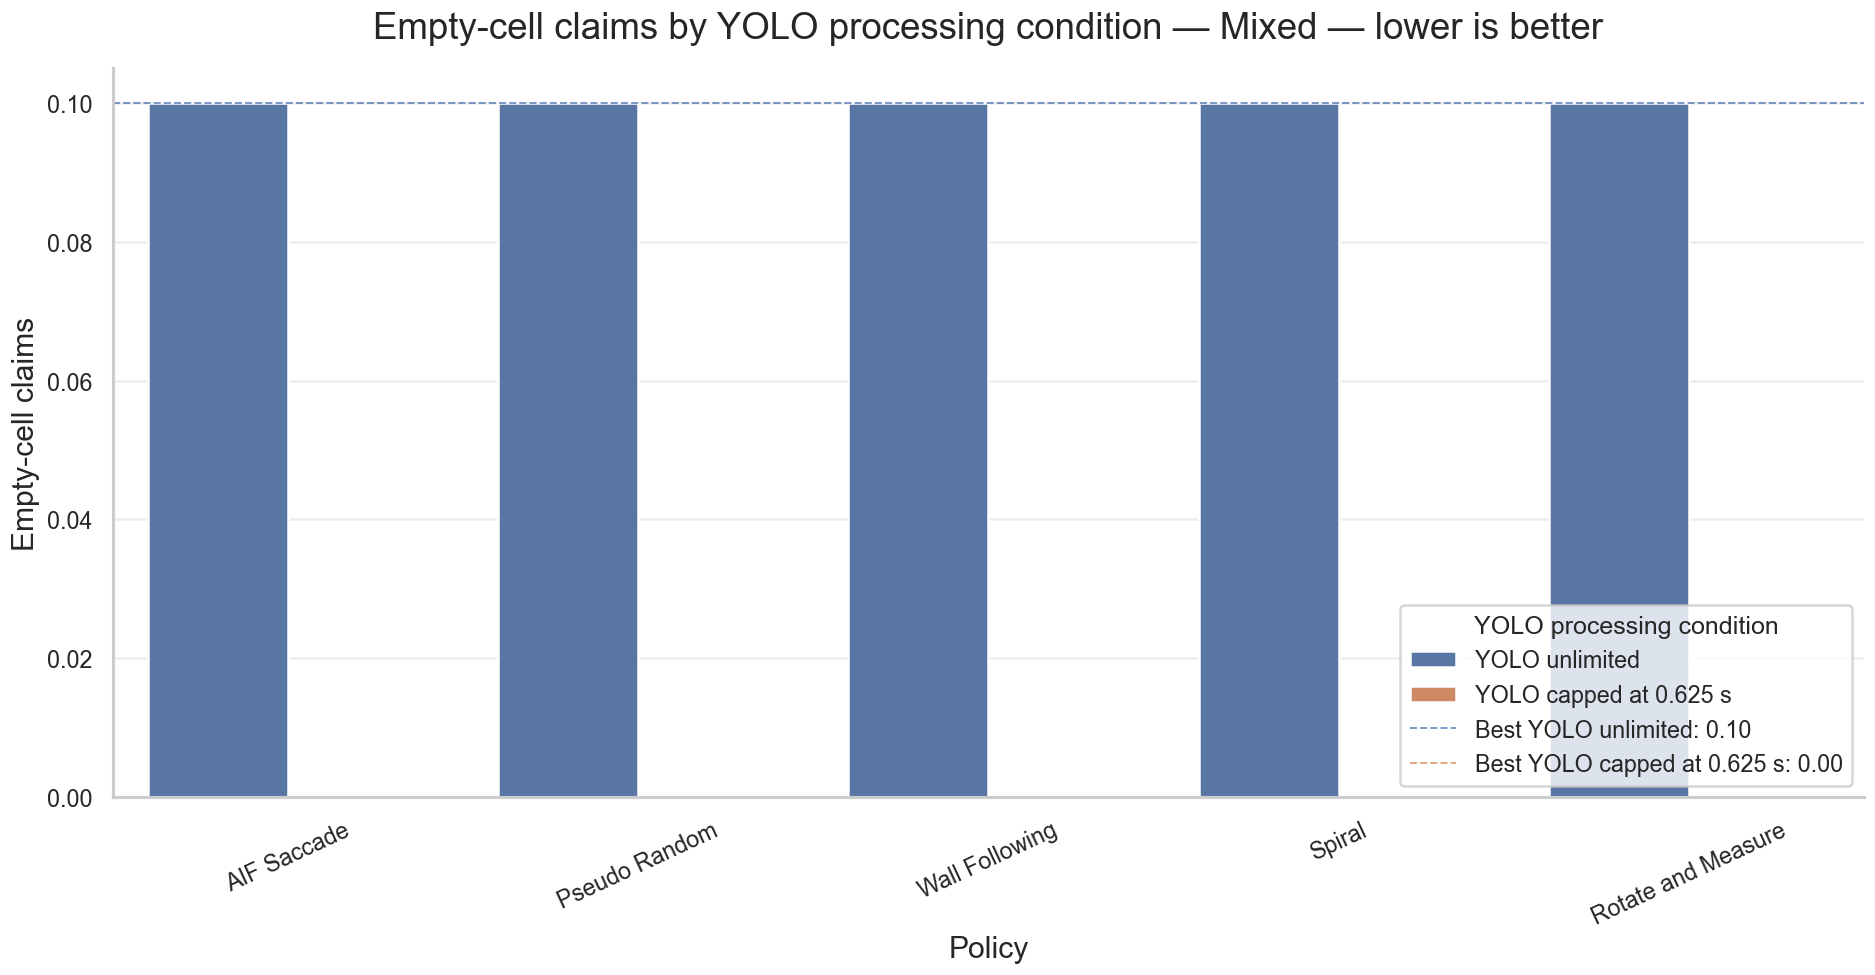

Skipping Duplicate claims ignored for Bottles only: no YOLO condition values.
Saved figure: figures_eval_comparison/mixed__duplicate_claims_ignored__yolo_conditions.png


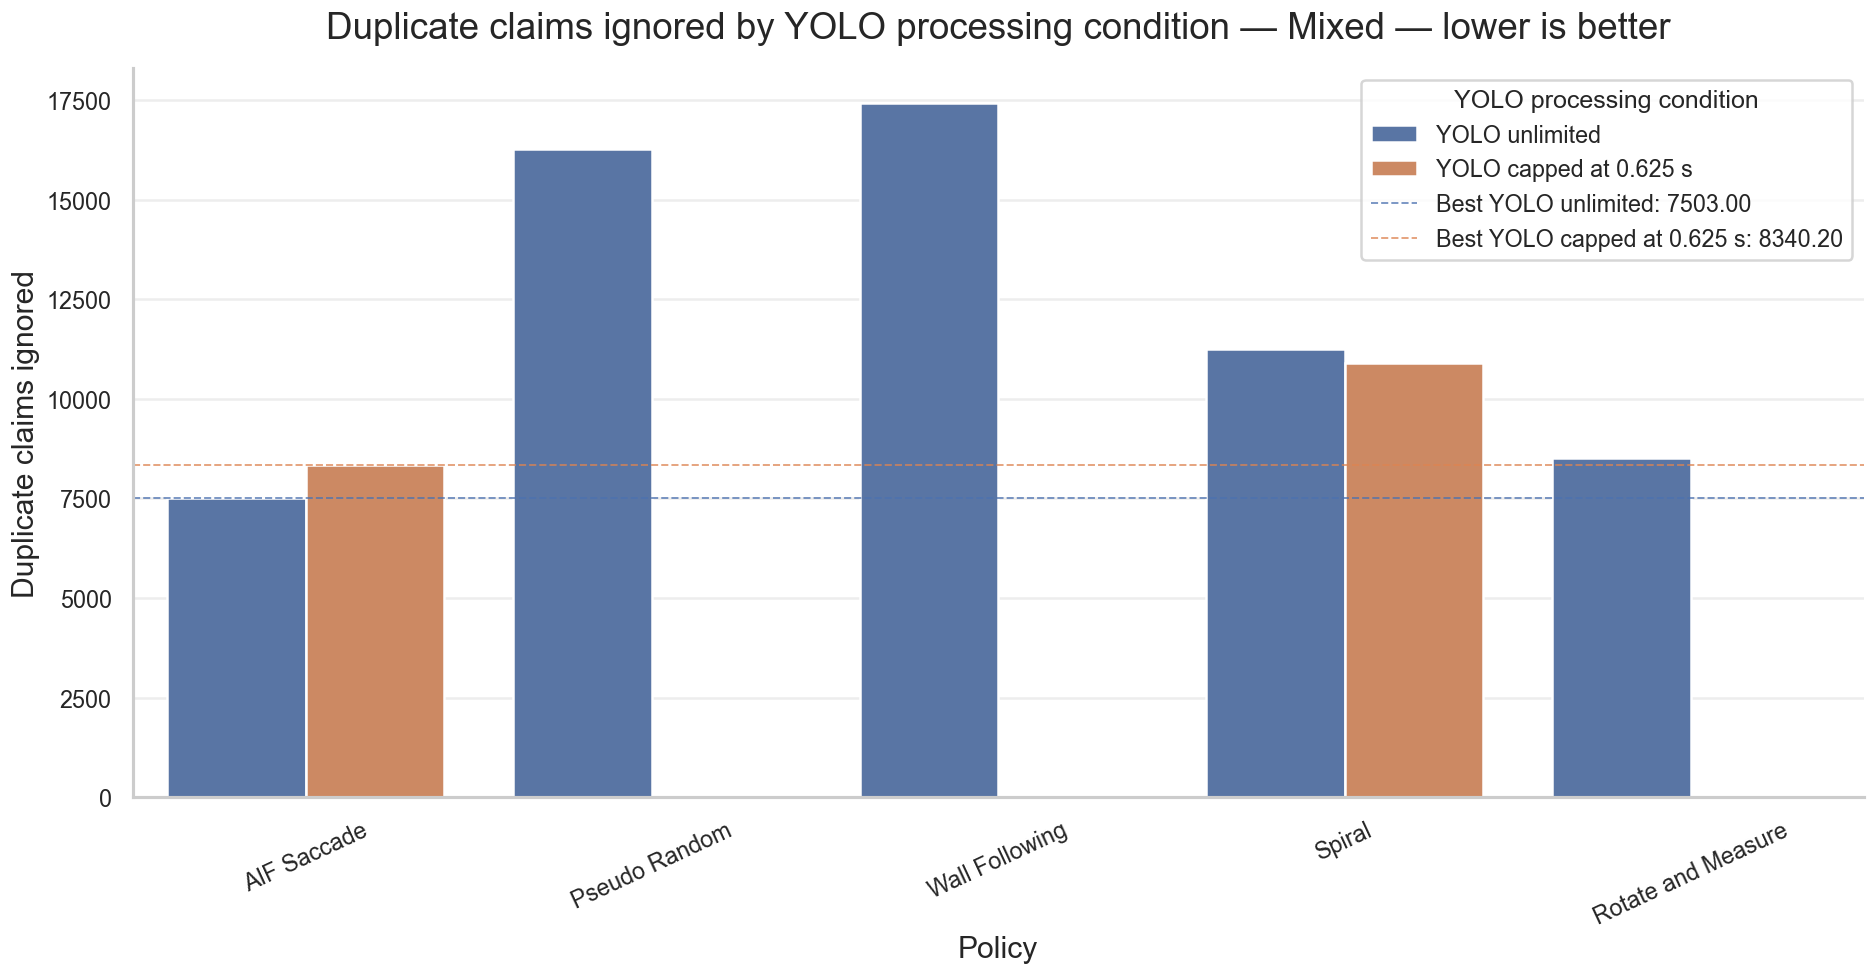

In [11]:
display(Markdown("## YOLO detector-limitation comparisons — classification metrics"))

classification_available = [
    metric for metric in CLASSIFICATION_METRICS
    if metric_is_available(runs_df, metric)
]

for metric in classification_available:
    for dataset in dataset_order:
        plot_metric_bar_by_condition(metric, dataset, include_gt=False)

In [12]:
def make_main_metric_table(metric):
    """
    Main GT vs unlimited-YOLO table.
    Capped YOLO conditions are excluded here.
    """
    meta = ALL_METRICS[metric]

    data = runs_df[
        runs_df["condition_type"].isin(["gt", "unlimited_yolo"])
        & runs_df[metric].notna()
    ].copy()

    table = (
        data
        .groupby(["dataset", "policy_label", "detector"], observed=True)[metric]
        .mean()
        .reset_index()
        .pivot_table(
            index=["dataset", "policy_label"],
            columns="detector",
            values=metric,
            observed=True,
        )
        .reset_index()
    )

    if "GT" in table.columns and "YOLO" in table.columns:
        table["YOLO_minus_GT"] = table["YOLO"] - table["GT"]

    if meta.get("kind") == "percentage":
        value_cols = [c for c in table.columns if c not in ["dataset", "policy_label"]]
        for c in value_cols:
            table[c] = table[c].map(lambda x: np.nan if pd.isna(x) else 100 * x)

    return table


def make_condition_metric_table(metric):
    """
    YOLO-condition table.
    Shows unlimited YOLO and throttled YOLO variants separately.
    """
    meta = ALL_METRICS[metric]

    data = runs_df[
        (runs_df["condition_type"] != "gt")
        & runs_df[metric].notna()
    ].copy()

    table = (
        data
        .groupby(["dataset", "policy_label", "condition_label"], observed=True)[metric]
        .mean()
        .reset_index()
        .pivot_table(
            index=["dataset", "policy_label"],
            columns="condition_label",
            values=metric,
            observed=True,
        )
        .reset_index()
    )

    if meta.get("kind") == "percentage":
        value_cols = [c for c in table.columns if c not in ["dataset", "policy_label"]]
        for c in value_cols:
            table[c] = table[c].map(lambda x: np.nan if pd.isna(x) else 100 * x)

    return table


for metric in available_metrics:
    display(Markdown(f"### {ALL_METRICS[metric]['label']} — GT vs unlimited YOLO"))
    display(make_main_metric_table(metric))

    display(Markdown(f"### {ALL_METRICS[metric]['label']} — YOLO detector limitations"))
    display(make_condition_metric_table(metric))

### Success rate — GT vs unlimited YOLO

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Bottles only,AIF Saccade,100.0,100.0,0.0
1,Bottles only,Pseudo Random,40.0,20.0,-20.0
2,Bottles only,Wall Following,0.0,0.0,0.0
3,Bottles only,Spiral,90.0,70.0,-20.0
4,Bottles only,Rotate and Measure,0.0,0.0,0.0
5,Mixed,AIF Saccade,100.0,100.0,0.0
6,Mixed,Pseudo Random,60.0,10.0,-50.0
7,Mixed,Wall Following,0.0,0.0,0.0
8,Mixed,Spiral,90.0,90.0,0.0
9,Mixed,Rotate and Measure,0.0,0.0,0.0


### Success rate — YOLO detector limitations

condition_label,dataset,policy_label,YOLO unlimited,YOLO capped at 0.625 s
0,Bottles only,AIF Saccade,100.0,NaN
1,Bottles only,Pseudo Random,20.0,NaN
2,Bottles only,Wall Following,0.0,NaN
3,Bottles only,Spiral,70.0,NaN
4,Bottles only,Rotate and Measure,0.0,NaN
5,Mixed,AIF Saccade,100.0,100.0
6,Mixed,Pseudo Random,10.0,NaN
7,Mixed,Wall Following,0.0,NaN
8,Mixed,Spiral,90.0,90.0
9,Mixed,Rotate and Measure,0.0,NaN


### Detected objects — GT vs unlimited YOLO

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Bottles only,AIF Saccade,100.000000,100.000000,0.000000
1,Bottles only,Pseudo Random,76.666667,80.000000,3.333333
2,Bottles only,Wall Following,71.666667,66.666667,-5.000000
3,Bottles only,Spiral,96.666667,93.333333,-3.333333
4,Bottles only,Rotate and Measure,40.000000,38.333333,-1.666667
5,Mixed,AIF Saccade,100.000000,100.000000,0.000000
6,Mixed,Pseudo Random,93.333333,73.333333,-20.000000
7,Mixed,Wall Following,71.666667,68.333333,-3.333333
8,Mixed,Spiral,96.666667,96.666667,0.000000
9,Mixed,Rotate and Measure,40.000000,38.333333,-1.666667


... (42 outputs left out)

### Duplicate claims ignored — GT vs unlimited YOLO

detector,dataset,policy_label,GT,YOLO,YOLO_minus_GT
0,Mixed,AIF Saccade,8386.9,7503.0,-883.9
1,Mixed,Pseudo Random,13780.0,16257.7,2477.7
2,Mixed,Wall Following,18076.7,17430.0,-646.7
3,Mixed,Spiral,10942.3,11244.2,301.9
4,Mixed,Rotate and Measure,8496.8,8519.7,22.9


### Duplicate claims ignored — YOLO detector limitations

condition_label,dataset,policy_label,YOLO unlimited,YOLO capped at 0.625 s
0,Mixed,AIF Saccade,7503.0,8340.2
1,Mixed,Pseudo Random,16257.7,NaN
2,Mixed,Wall Following,17430.0,NaN
3,Mixed,Spiral,11244.2,10904.8
4,Mixed,Rotate and Measure,8519.7,NaN


Saved figure: figures_eval_comparison/confusion_matrix___mixed___gt___aif_saccade.png


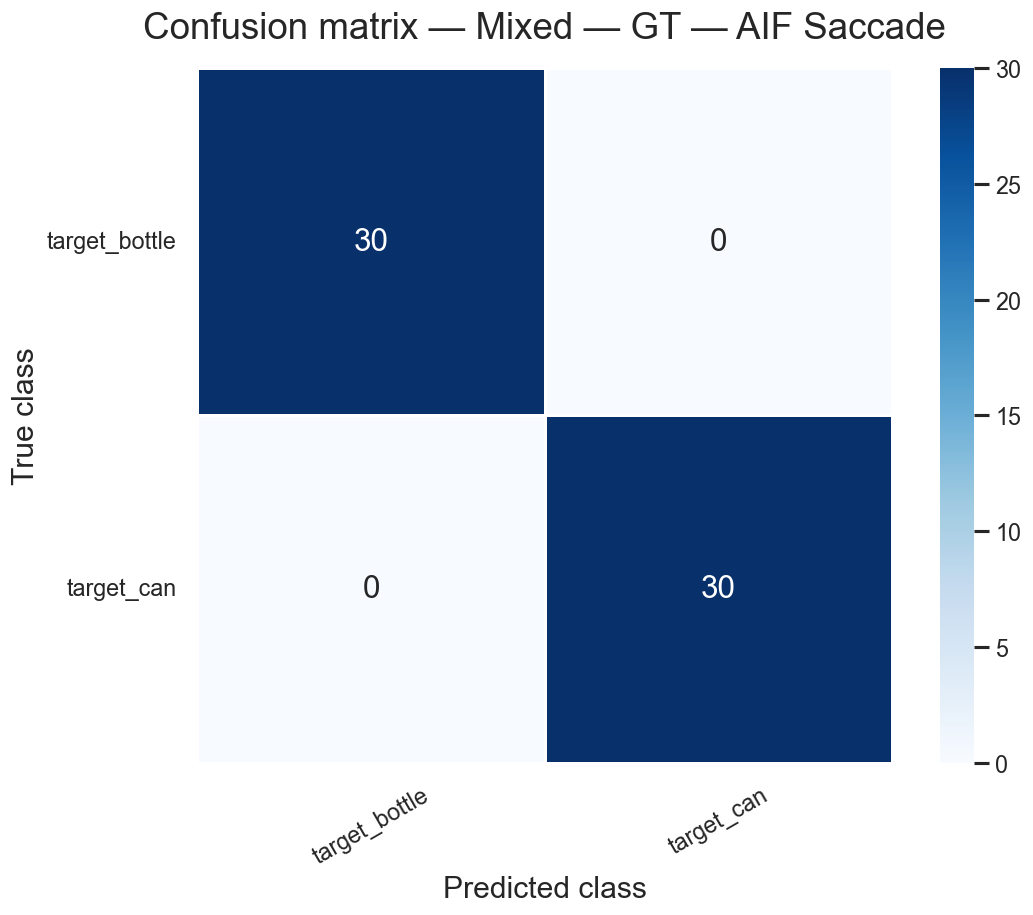

Saved figure: figures_eval_comparison/normalized_confusion_matrix___mixed___gt___aif_saccade.png


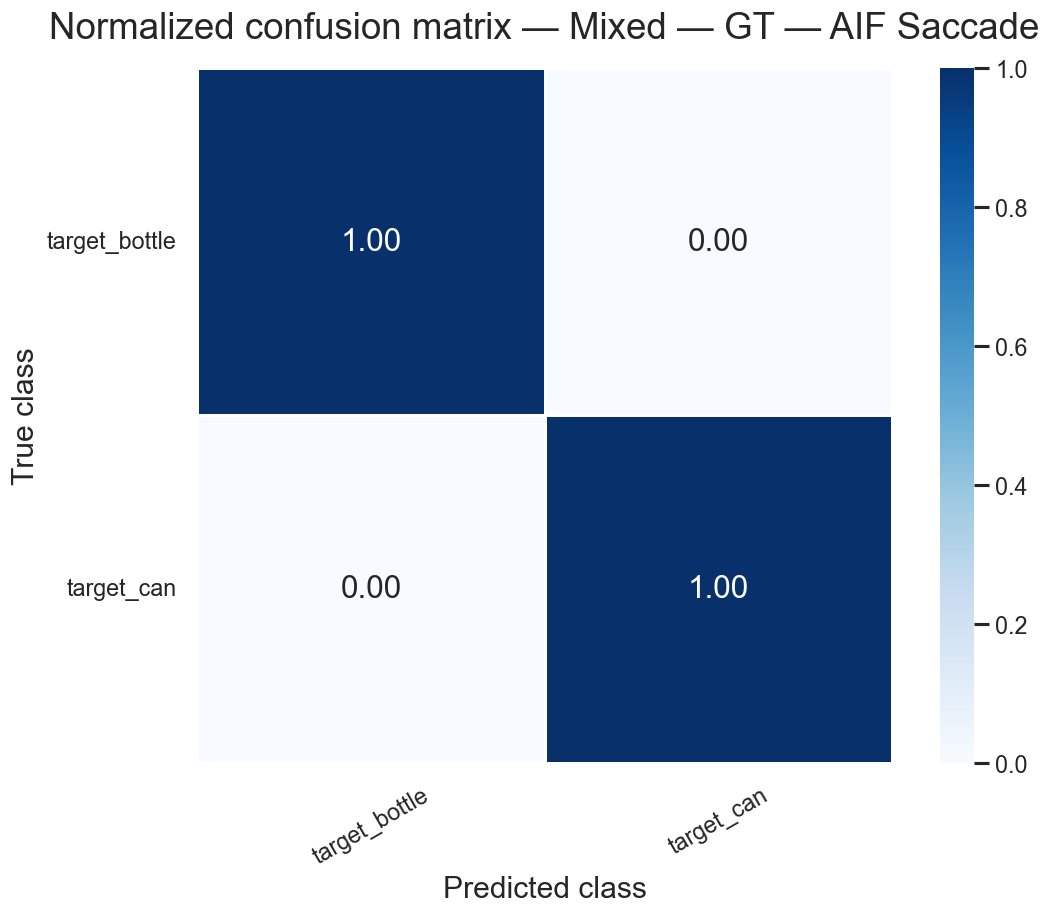

Saved figure: figures_eval_comparison/confusion_matrix___mixed___yolo_unlimited___aif_saccade.png


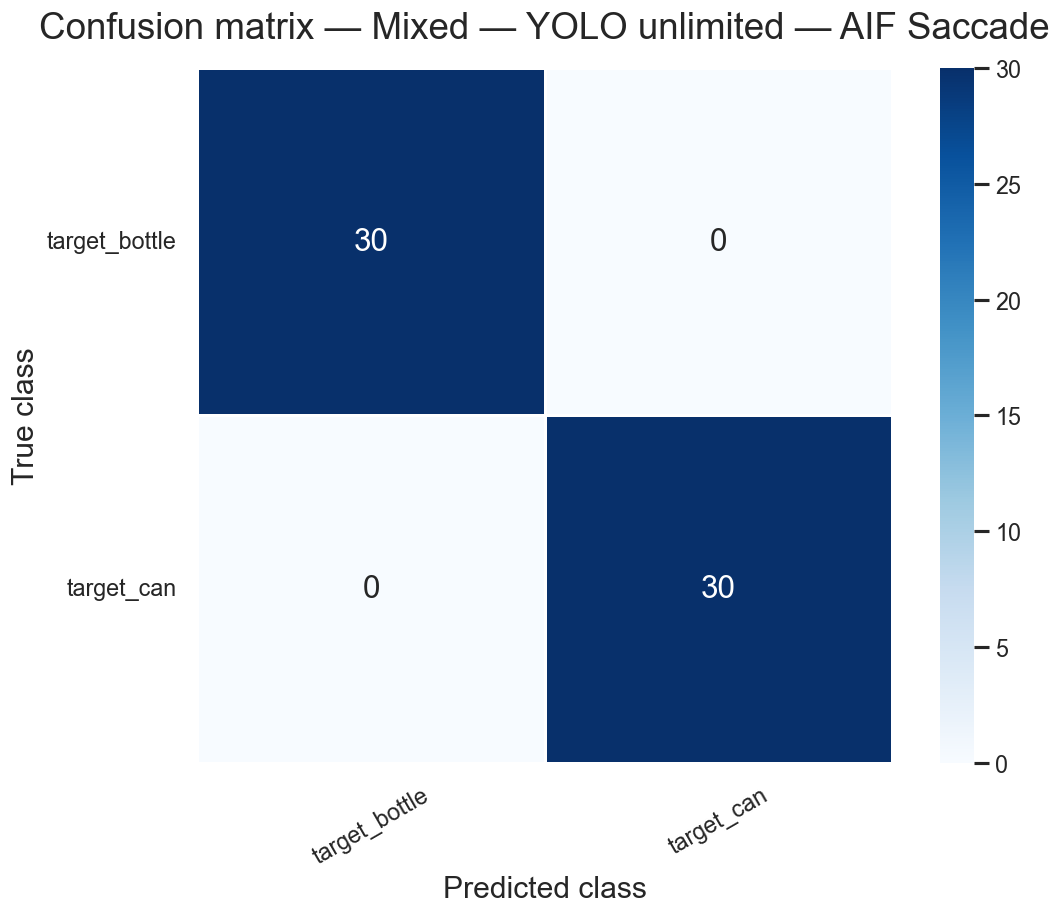

Saved figure: figures_eval_comparison/normalized_confusion_matrix___mixed___yolo_unlimited___aif_saccade.png


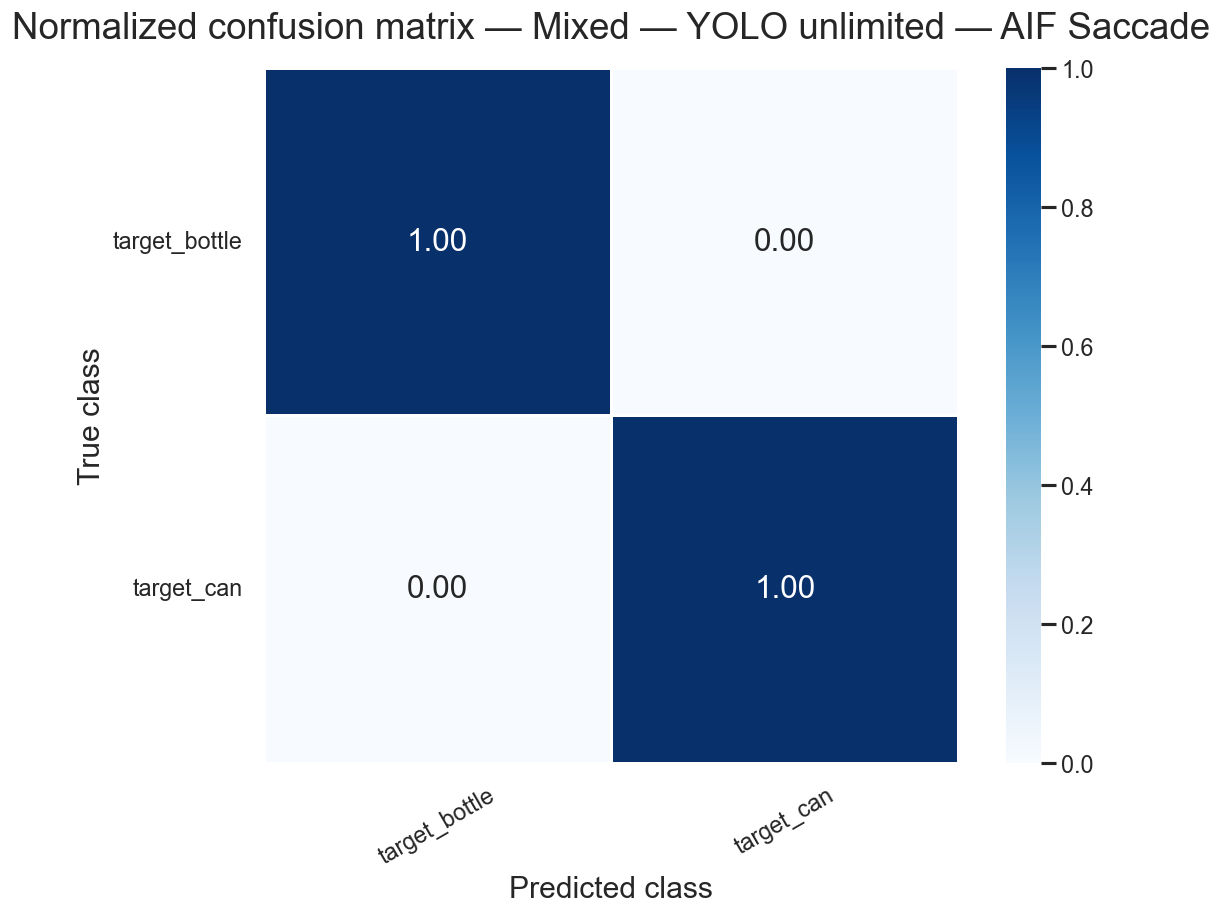

Saved figure: figures_eval_comparison/confusion_matrix___mixed___yolo_capped_at_0.625_s___aif_saccade.png


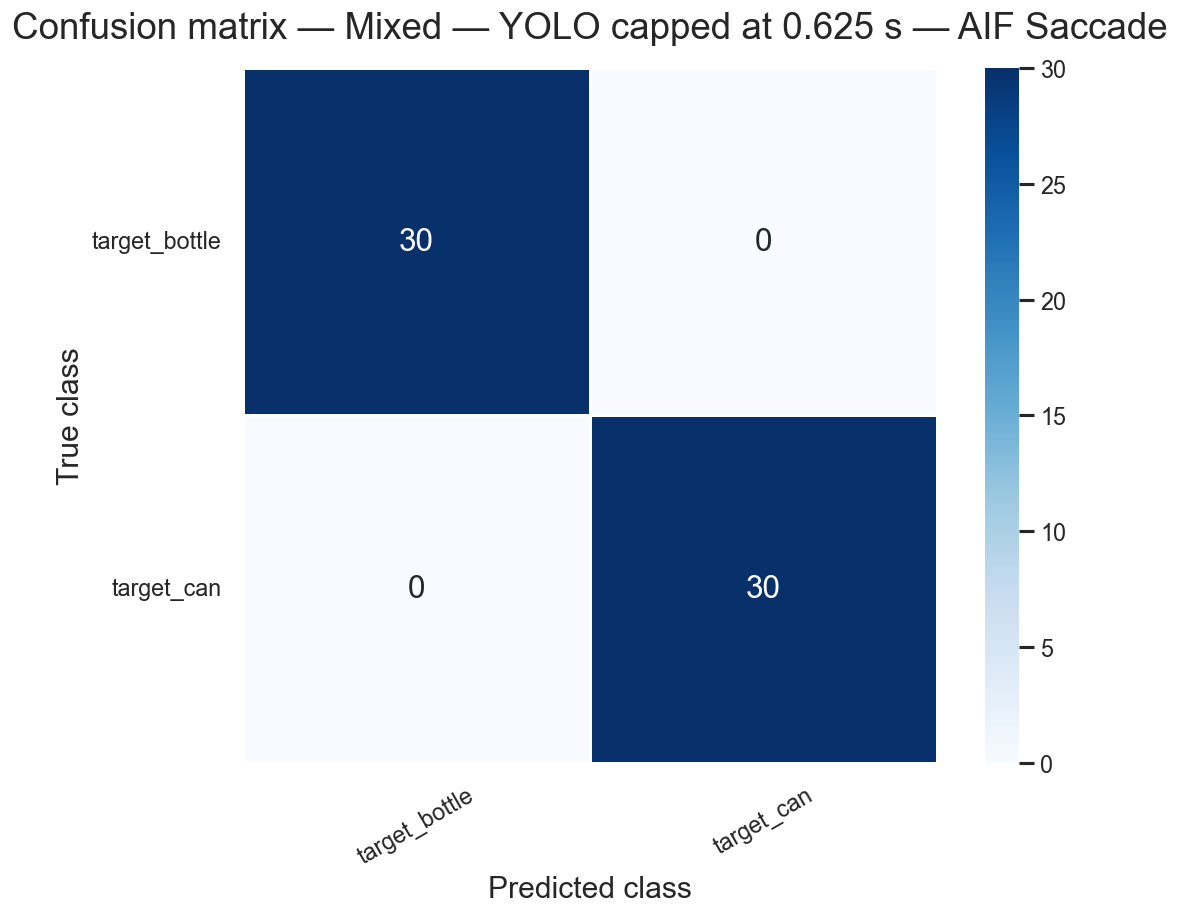

Saved figure: figures_eval_comparison/normalized_confusion_matrix___mixed___yolo_capped_at_0.625_s___aif_saccade.png


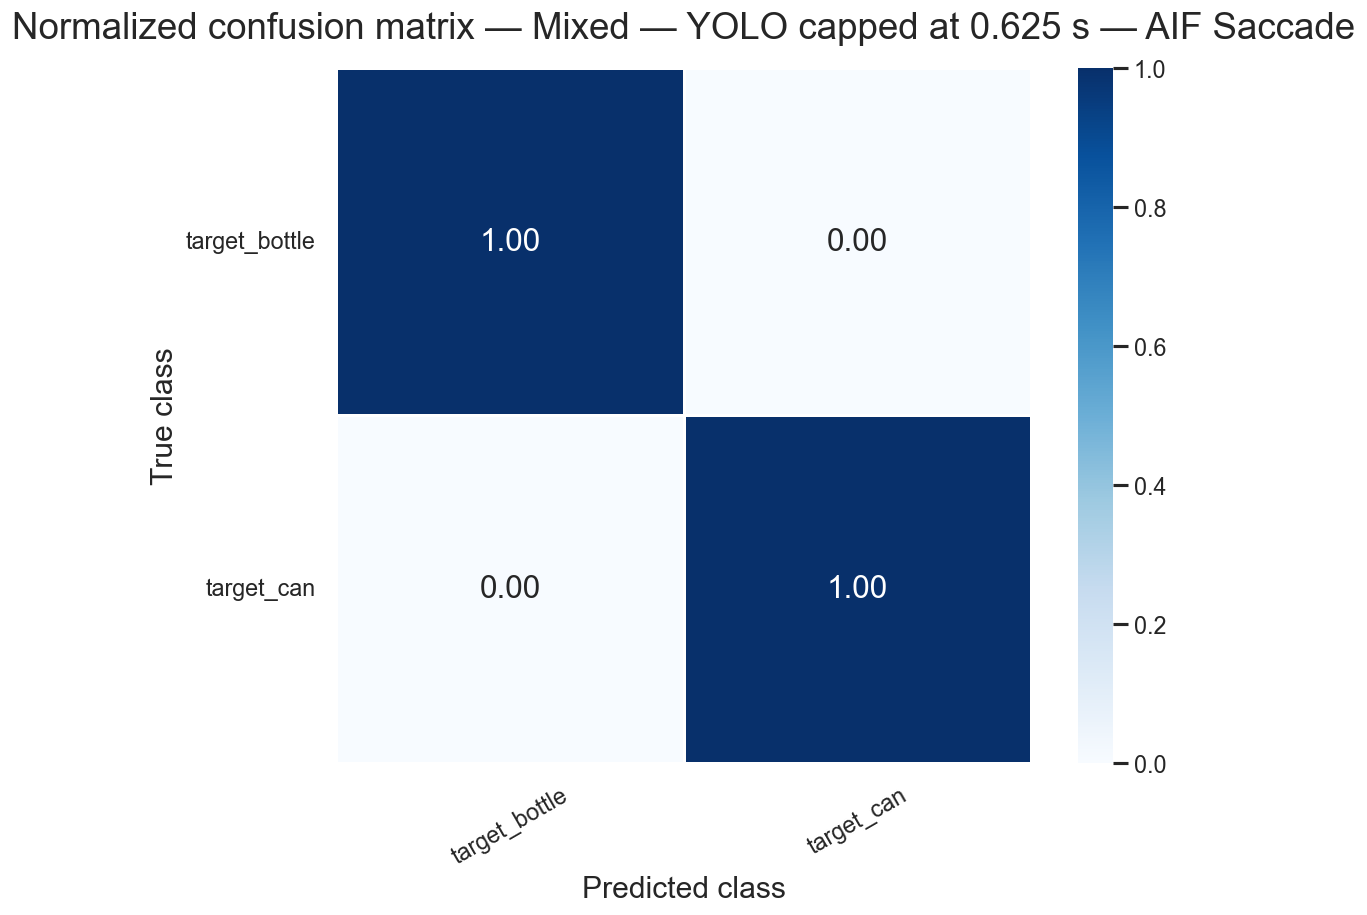

In [13]:
def aggregate_confusion_matrices(df, dataset=None, detector=None, policy=None):
    """
    Aggregates nested confusion_matrix dictionaries across all matching runs.

    Expected shape per run:
    {
        "target_bottle": {"target_bottle": 3, "target_can": 0},
        "target_can": {"target_can": 3}
    }
    """
    subset = df.copy()

    if dataset is not None:
        subset = subset[subset["dataset"] == dataset]
    if detector is not None:
        subset = subset[subset["detector"] == detector]
    if policy is not None:
        subset = subset[subset["policy"] == policy]

    matrices = subset["confusion_matrix"].dropna().tolist()
    matrices = [m for m in matrices if isinstance(m, dict)]

    if not matrices:
        return pd.DataFrame()

    true_labels = sorted({true for m in matrices for true in m.keys()})
    pred_labels = sorted({pred for m in matrices for preds in m.values() for pred in preds.keys()})
    labels = sorted(set(true_labels) | set(pred_labels))

    cm = pd.DataFrame(0, index=labels, columns=labels, dtype=float)

    for m in matrices:
        for true_label, preds in m.items():
            for pred_label, count in preds.items():
                cm.loc[true_label, pred_label] += count

    return cm


def plot_confusion_matrix(cm, title, normalize=False):
    if cm.empty:
        print(f"Skipping confusion matrix: {title} has no data.")
        return

    plot_cm = cm.copy()

    if normalize:
        row_sums = plot_cm.sum(axis=1).replace(0, np.nan)
        plot_cm = plot_cm.div(row_sums, axis=0)

    fig, ax = plt.subplots(figsize=(10, 8))

    fmt = ".2f" if normalize else ".0f"
    sns.heatmap(
        plot_cm,
        annot=True,
        fmt=fmt,
        cmap="Blues",
        cbar=True,
        square=True,
        linewidths=0.7,
        linecolor="white",
        ax=ax,
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)

    plt.tight_layout()

    safe_title = (
        title.lower()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("—", "_")
        .replace(":", "")
    )
    save_current_figure(f"{safe_title}.png")

    plt.show()


CONFUSION_MATRIX_POLICY = "aif_saccade"

for dataset in dataset_order:
    for condition in condition_order:
        cm = aggregate_confusion_matrices(
            runs_df[runs_df["condition_label"] == condition],
            dataset=dataset,
            detector=None,
            policy=CONFUSION_MATRIX_POLICY,
        )

        if cm.empty:
            continue

        policy_label = pretty_policy_name(CONFUSION_MATRIX_POLICY)

        title = f"Confusion matrix — {dataset} — {condition} — {policy_label}"
        plot_confusion_matrix(cm, title, normalize=False)

        title_norm = f"Normalized confusion matrix — {dataset} — {condition} — {policy_label}"
        plot_confusion_matrix(cm, title_norm, normalize=True)

In [14]:
display(Markdown("## Sanity checks"))

# 1. Missing pairings: useful to catch missing GT/YOLO files for a policy.
coverage_table = (
    runs_df
    .groupby(["dataset", "policy_label", "detector"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
    .pivot_table(
        index=["dataset", "policy_label"],
        columns="detector",
        values="num_runs",
        observed=True,
    )
)

display(Markdown("### Number of runs available for each comparison cell"))
display(coverage_table)

# 2. Warnings for very small sample sizes.
small_n = (
    runs_df
    .groupby(["dataset", "detector", "policy_label"], observed=True)
    .size()
    .rename("num_runs")
    .reset_index()
    .query("num_runs < 30")
)

if len(small_n) > 0:
    display(Markdown(
        "### Note on sample size\n"
        "Some experiment groups have fewer than 30 runs. "
        "Bar heights are still valid sample means, but the uncertainty bands can be noisy."
    ))
    display(small_n)

# 3. Classification coverage.
class_rows = runs_df[runs_df["overall_claim_precision"].notna()]
if len(class_rows) == 0:
    display(Markdown("### Classification metrics\nNo per-run classification metrics were found."))
else:
    display(Markdown("### Classification metrics present for:"))
    display(
        class_rows
        .groupby(["dataset", "detector", "policy_label"], observed=True)
        .size()
        .rename("num_runs_with_classification")
        .reset_index()
    )

## Sanity checks

### Number of runs available for each comparison cell

detector                           GT  YOLO
dataset      policy_label                  
Bottles only AIF Saccade         10.0  10.0
             Pseudo Random       10.0  10.0
             Wall Following      10.0  10.0
             Spiral              10.0  10.0
             Rotate and Measure  10.0  10.0
Mixed        AIF Saccade         10.0  20.0
             Pseudo Random       10.0  10.0
             Wall Following      10.0  10.0
             Spiral              10.0  20.0
             Rotate and Measure  10.0  10.0

### Note on sample size
Some experiment groups have fewer than 30 runs. Bar heights are still valid sample means, but the uncertainty bands can be noisy.

,dataset,detector,policy_label,num_runs
0,Bottles only,GT,AIF Saccade,10
1,Bottles only,GT,Pseudo Random,10
2,Bottles only,GT,Wall Following,10
3,Bottles only,GT,Spiral,10
4,Bottles only,GT,Rotate and Measure,10
5,Bottles only,YOLO,AIF Saccade,10
6,Bottles only,YOLO,Pseudo Random,10
7,Bottles only,YOLO,Wall Following,10
8,Bottles only,YOLO,Spiral,10
9,Bottles only,YOLO,Rotate and Measure,10


### Classification metrics present for:

,dataset,detector,policy_label,num_runs_with_classification
0,Mixed,GT,AIF Saccade,10
1,Mixed,GT,Pseudo Random,10
2,Mixed,GT,Wall Following,10
3,Mixed,GT,Spiral,10
4,Mixed,GT,Rotate and Measure,10
5,Mixed,YOLO,AIF Saccade,20
6,Mixed,YOLO,Pseudo Random,10
7,Mixed,YOLO,Wall Following,10
8,Mixed,YOLO,Spiral,20
9,Mixed,YOLO,Rotate and Measure,10
